In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from fredapi import Fred
import yfinance as yf

import warnings
warnings.filterwarnings("ignore")

## Data Collection

Data for this project will be obtained from FRED (Federal Reserve Economic Data), Yahoo Finance APIs, and historical CSV files for indicators where API coverage does not extend back to 1960. A free FRED API key is required to run the data collection cells and can be obtained from https://fred.stlouisfed.org/docs/api/api_key.html. The following macroeconomic and financial indicators will be examined:

### FRED Indicators
- **Unemployment Rate (UNRATE)** - monthly measure of the percentage of the labour force that is unemployed, a key lagging indicator of economic health
- **Consumer Price Index (CPIAUCSL)** - measures inflation through changes in the price of a basket of consumer goods and services
- **Federal Funds Rate (FEDFUNDS)** - the interest rate at which banks lend to each other overnight, a primary tool of US monetary policy
- **Industrial Production (INDPRO)** - measures real output of the manufacturing, mining and utilities sectors, a leading indicator of economic activity
- **House Prices (CSUSHPISA)** - S&P CoreLogic Case-Shiller US National Home Price Index, captures housing market conditions; available from 1987
- **Yield Curve (T10Y2Y)** - spread between 10-year and 2-year Treasury yields; inversion has preceded every US recession since the 1950s; available from 1976
- **Initial Jobless Claims (ICSA)** - weekly count of new unemployment insurance claims, one of the most timely labour market indicators available; available from 1967
- **Credit Spread (BAA10Y)** - spread between Moody's BAA corporate bond yield and 10-year Treasury yield; widens as default risk rises ahead of recessions; available from 1986
- **Consumer Credit (TOTALSL)** - total outstanding consumer credit, captures household borrowing trends
- **Housing Starts (HOUST)** - number of new residential construction projects begun each month, a forward-looking indicator of economic activity
- **30-Year Fixed Mortgage Rate (MORTGAGE30US)** - captures consumer borrowing costs in the housing market; available from 1971
- **Money Supply M2 (M2SL)** - broad measure of money supply including cash, deposits and money market funds; changes in M2 often precede turning points in economic activity
- **Federal Debt as % of GDP (GFDEGDQ188S)** - captures long-term fiscal sustainability; quarterly series interpolated to monthly frequency; available from 1966
- **Corporate Profits (CP)** - pre-tax corporate profits, a leading indicator of business investment and hiring decisions; quarterly series interpolated to monthly frequency
- **Recession Indicator (USREC)** - NBER defined binary indicator, 1 during recession months and 0 otherwise; used as the target variable

### Yahoo Finance and CSV Indicators
- **S&P 500 (^GSPC)** - broad measure of US equity market performance, reflects investor expectations about future economic conditions; extended back to 1960 using historical CSV data combined with Yahoo Finance API
- **Gold** - commodity price commonly associated with safe haven demand during periods of economic uncertainty; extended back to 1960 using historical CSV data combined with Yahoo Finance API

### Dataset Structure
Given the varying availability of these indicators, two datasets will be constructed:
- **1960 Dataset** - core macroeconomic indicators available from 1960, covering all nine NBER recession episodes across six decades. Indicators with limited historical coverage such as house prices, yield curve, credit spread and mortgage rates are excluded.
- **1987 Dataset** - full indicator set from 1987 onwards, covering four recession episodes: the Gulf War recession, the Dot-Com recession, the Global Financial Crisis, and COVID-19. This dataset sacrifices historical length in favour of a richer feature set reflecting the modern US economy.

A data coverage summary is printed automatically at the end of the collection cells showing the start date, end date, row count and number of NaN values for each indicator, reflecting the most recent available data at the time of running.

In [2]:
# FRED API Connection

from dotenv import load_dotenv, find_dotenv
import os

load_dotenv(find_dotenv(), override=True)
FRED_API_KEY = os.getenv("FRED_API_KEY")

fred = Fred(api_key=FRED_API_KEY)
print("FRED connection established")

FRED connection established


In [3]:
# Start & End Dates for Project

START = "1960-01-01"
END   = pd.Timestamp.today().strftime("%Y-%m-%d")

In [4]:
# FRED Indicators 

unemployment          = fred.get_series("UNRATE",       START, END)
cpi                   = fred.get_series("CPIAUCSL",     START, END)
fed_funds             = fred.get_series("FEDFUNDS",     START, END)
industrial_production = fred.get_series("INDPRO",       START, END)
house_prices          = fred.get_series("CSUSHPISA",    START, END)
recession             = fred.get_series("USREC",        START, END)
yield_curve           = fred.get_series("T10Y2Y",       START, END)
jobless_claims        = fred.get_series("ICSA",         START, END)
credit_spread         = fred.get_series("BAA10Y",       START, END)
consumer_credit       = fred.get_series("TOTALSL",      START, END)
lei                   = fred.get_series("USSLIND",      START, END)
housing_starts        = fred.get_series("HOUST",        START, END)
mortgage_rates        = fred.get_series("MORTGAGE30US", START, END)
debt_gdp              = fred.get_series("GFDEGDQ188S",  START, END)
corporate_profits     = fred.get_series("CP",           START, END)
m2                    = fred.get_series("M2SL",         START, END)

print("FRED data collected")

FRED data collected


In [5]:
# Yahoo Finance Indicators 

sp500_raw  = yf.download("^GSPC",  start=START, end=END, interval="1mo", progress=False)
gold_raw   = yf.download("GC=F",   start=START, end=END, interval="1mo", progress=False)
vix_raw    = yf.download("^VIX",   start=START, end=END, interval="1mo", progress=False)

sp500  = sp500_raw["Close"].squeeze()
gold   = gold_raw["Close"].squeeze()
vix    = vix_raw["Close"].squeeze()

print("Yahoo Finance data collected")

Yahoo Finance data collected


In [6]:
# Align to Monthly Frequency 
# resample all series to month start, forward fill where needed

def to_monthly(series, label):
    s = series.copy()
    s.index = pd.to_datetime(s.index)
    s = s.resample("MS").mean()
    s.name = label
    return s

unemployment          = to_monthly(unemployment,          "unemployment")
cpi                   = to_monthly(cpi,                   "cpi")
fed_funds             = to_monthly(fed_funds,             "fed_funds")
industrial_production = to_monthly(industrial_production, "industrial_production")
house_prices          = to_monthly(house_prices,          "house_prices")
recession             = to_monthly(recession,             "recession")
yield_curve           = to_monthly(yield_curve,           "yield_curve")
jobless_claims        = to_monthly(jobless_claims,        "jobless_claims")
credit_spread         = to_monthly(credit_spread,         "credit_spread")
consumer_credit       = to_monthly(consumer_credit,       "consumer_credit")
lei                   = to_monthly(lei,                   "lei")
housing_starts        = to_monthly(housing_starts,        "housing_starts")
mortgage_rates        = to_monthly(mortgage_rates,        "mortgage_rates")
sp500                 = to_monthly(sp500,                 "sp500")
gold                  = to_monthly(gold,                  "gold")
vix                   = to_monthly(vix,                   "vix")
m2                    = to_monthly(m2,                    "m2")


# quarterly indicators - resample then interpolate
debt_gdp = fred.get_series("GFDEGDQ188S", START, END)
debt_gdp = pd.Series(debt_gdp.values, index=pd.to_datetime(debt_gdp.index))
debt_gdp = debt_gdp.resample("MS").interpolate(method="time")
debt_gdp.name = "debt_gdp"

corporate_profits = fred.get_series("CP", START, END)
corporate_profits = pd.Series(corporate_profits.values, index=pd.to_datetime(corporate_profits.index))
corporate_profits = corporate_profits.resample("MS").interpolate(method="time")
corporate_profits.name = "corporate_profits"

print("All series aligned to monthly frequency")

All series aligned to monthly frequency


In [7]:
# Data Coverage Summary 

series_dict = {
    "unemployment":           unemployment,
    "cpi":                    cpi,
    "fed_funds":              fed_funds,
    "industrial_production":  industrial_production,
    "house_prices":           house_prices,
    "recession":              recession,
    "yield_curve":            yield_curve,
    "jobless_claims":         jobless_claims,
    "credit_spread":          credit_spread,
    "consumer_credit":        consumer_credit,
    "lei":                    lei,
    "housing_starts":         housing_starts,
    "mortgage_rates":         mortgage_rates,
    "sp500":                  sp500,
    "gold":                   gold,
    "vix":                    vix,
    "debt_gdp":               debt_gdp,
    "corporate_profits":      corporate_profits,
    "m2":                     m2,
}

print(f"{'Indicator':<25} {'Start':<15} {'End':<15} {'Rows':<10} {'NaNs'}")
print("-" * 75)
for name, series in series_dict.items():
    clean = series.dropna()
    nans  = series.isnull().sum()
    print(f"{name:<25} {str(clean.index.min().date()):<15} {str(clean.index.max().date()):<15} {len(clean):<10} {nans}")

Indicator                 Start           End             Rows       NaNs
---------------------------------------------------------------------------
unemployment              1960-01-01      2026-06-01      797        1
cpi                       1960-01-01      2026-06-01      797        1
fed_funds                 1960-01-01      2026-06-01      798        0
industrial_production     1960-01-01      2026-06-01      798        0
house_prices              1987-01-01      2026-04-01      472        144
recession                 1960-01-01      2026-06-01      798        0
yield_curve               1976-06-01      2026-07-01      602        0
jobless_claims            1967-01-01      2026-07-01      715        0
credit_spread             1986-01-01      2026-07-01      487        0
consumer_credit           1960-01-01      2026-05-01      797        0
lei                       1982-01-01      2020-02-01      458        0
housing_starts            1960-01-01      2026-06-01      798      

## Data Availability and Limitations

Many of the indicators used in this project were not historically recorded from 1960, which presents a key challenge in constructing a consistent long-run dataset. The table below summarises the earliest available data for each indicator based on the coverage summary output, and the timeline chart visualises the coverage period for each indicator relative to the two dataset start dates:

| Indicator | Source | Available From | Notes |
|---|---|---|---|
| Unemployment | FRED | 1960 | |
| CPI | FRED | 1960 | |
| Federal Funds Rate | FRED | 1960 | |
| Industrial Production | FRED | 1960 | |
| Consumer Credit | FRED | 1960 | |
| Housing Starts | FRED | 1960 | |
| Corporate Profits | FRED | 1960 | Quarterly, interpolated to monthly |
| M2 Money Supply | FRED | 1960 | |
| Gold | Historical CSV + Yahoo Finance | 1960 | CSV extended back to 1960, Yahoo Finance fills forward |
| S&P 500 | Historical CSV + Yahoo Finance | 1960 | CSV extended back to 1960, Yahoo Finance fills forward |
| Jobless Claims | FRED | 1967 | |
| Debt as % of GDP | FRED | 1966 | Quarterly, interpolated to monthly |
| Mortgage Rates | FRED | 1971 | |
| Yield Curve | FRED | 1976 | |
| Credit Spread | FRED | 1986 | |
| House Prices | FRED | 1987 | Excluded from 1960 dataset |

Note: the S&P 500 and gold historical CSV files must be downloaded manually and placed in the data folder before running the notebook. See data/README.md for download instructions.

Two indicators were considered but excluded from the final datasets:
- **VIX** - only available from 1990, insufficient historical coverage for the 1960 dataset and partially redundant given credit spread and S&P 500 already capture market stress
- **LEI (USSLIND)** - OECD composite leading indicator available from 1982 but series ends in 2020, making it unsuitable for a project that includes data up to the present day

These availability constraints directly influenced the dataset structure adopted in this project. Rather than restricting all indicators to the shortest common time period, which would reduce the dataset to approximately 36 years of data and lose several important recession episodes, two datasets were constructed:
- **1960 Dataset** - contains indicators available from 1960, covering all nine NBER recession episodes from 1960 to present. This dataset prioritises historical depth over indicator breadth.
- **1987 Dataset** - contains the full indicator set from 1987 onwards, covering four recession episodes: the Gulf War recession, the Dot-Com recession, the Global Financial Crisis, and COVID-19. This dataset sacrifices historical length in favour of a richer feature set reflecting the modern US economy.

The class imbalance in the recession indicator is a fundamental characteristic of the data that directly impacts the modelling approach. Recession months represent approximately 11% of the 1960 dataset and 8% of the 1987 dataset, meaning models must be carefully designed to avoid simply predicting non-recession for every observation.

Where minor gaps exist within a series, time-based interpolation was applied to preserve continuity. Quarterly indicators including corporate profits and federal debt as a percentage of GDP were resampled to monthly frequency using interpolation to create smooth monthly estimates between quarterly release points. No large-scale imputation was used for structural gaps where data genuinely did not exist.

In [8]:
# Gold and S&P 500 historical data was sourced via macrotrends

gold_hist = pd.read_csv("Gold_Price_US.csv", parse_dates=["Date"])
sp500_hist = pd.read_csv("S&P500.csv", parse_dates=["Date"])

#https://www.macrotrends.net/datasets/1333/historical-gold-prices-100-year-chart
#https://www.macrotrends.net/2324/sp-500-historical-chart-data

In [9]:
gold_hist

,Date,Value
0,1915-01-01,19.2500
1,1915-02-01,19.2500
2,1915-03-01,19.2500
3,1915-04-01,19.2500
4,1915-05-01,19.2500
...,...,...
1334,2026-03-01,4670.3486
1335,2026-04-01,4629.5648
1336,2026-05-01,4541.8773
1337,2026-06-01,4006.7000


In [10]:
sp500_hist

,Date,Value
0,1927-12-31,17.66
1,1928-01-31,17.57
2,1928-02-29,17.26
3,1928-03-31,19.28
4,1928-04-30,19.75
...,...,...
1178,2026-02-27,6878.88
1179,2026-03-31,6528.52
1180,2026-04-30,7209.01
1181,2026-05-29,7580.06


In [11]:
gold_hist = gold_hist.set_index("Date")
gold_hist.index = pd.to_datetime(gold_hist.index)
gold_hist = gold_hist.rename(columns={"Value": "gold"})
gold_hist = gold_hist.resample("MS").mean()

sp500_hist = sp500_hist.set_index("Date")
sp500_hist.index = pd.to_datetime(sp500_hist.index)
sp500_hist = sp500_hist.rename(columns={"Value": "sp500"})
sp500_hist = sp500_hist.resample("MS").mean()

In [12]:
# Gold - CSV + Yahoo Finance 

gold_csv_end = gold_hist.index.max()

gold_csv_end_check = pd.Timestamp.today().normalize()
if gold_csv_end < gold_csv_end_check - pd.DateOffset(months=1):
    gold_yahoo_raw = yf.download("GC=F", start=gold_csv_end + pd.DateOffset(months=1),
                                  end=END, interval="1mo", progress=False)
    gold_yahoo = gold_yahoo_raw["Close"].squeeze()
    gold_yahoo.name = "gold"
    gold_yahoo.index = pd.to_datetime(gold_yahoo.index)
    gold_yahoo = gold_yahoo.resample("MS").mean()
    gold = pd.concat([gold_hist["gold"], gold_yahoo])
else:
    gold = gold_hist["gold"]

gold = gold[~gold.index.duplicated(keep="first")]
gold.name = "gold"
gold = gold["1960-01-01":]

print(f"Gold: {gold.index.min().date()} to {gold.index.max().date()} - {len(gold)} rows")

# S&P 500 - CSV + Yahoo Finance 
# CSV dates are end of month - convert to month start

sp500_hist.index = sp500_hist.index + pd.offsets.MonthBegin(1)

sp500_csv_end = sp500_hist.index.max()

if sp500_csv_end < gold_csv_end_check - pd.DateOffset(months=1):
    sp500_yahoo_raw = yf.download("^GSPC", start=sp500_csv_end + pd.DateOffset(months=1),
                                   end=END, interval="1mo", progress=False)
    if not sp500_yahoo_raw.empty:
        sp500_yahoo = sp500_yahoo_raw["Close"]
        if isinstance(sp500_yahoo, pd.DataFrame):
            sp500_yahoo = sp500_yahoo.iloc[:, 0]
        sp500_yahoo = sp500_yahoo.squeeze()
        if isinstance(sp500_yahoo, pd.Series):
            sp500_yahoo.name = "sp500"
            sp500_yahoo.index = pd.to_datetime(sp500_yahoo.index)
            sp500_yahoo = sp500_yahoo.resample("MS").mean()
            sp500 = pd.concat([sp500_hist["sp500"], sp500_yahoo])
        else:
            sp500 = sp500_hist["sp500"]
    else:
        sp500 = sp500_hist["sp500"]
else:
    sp500 = sp500_hist["sp500"]

sp500 = sp500[~sp500.index.duplicated(keep="first")]
sp500.name = "sp500"
sp500 = sp500["1960-01-01":]

print(f"S&P 500: {sp500.index.min().date()} to {sp500.index.max().date()} - {len(sp500)} rows")

Gold: 1960-01-01 to 2026-07-01 - 799 rows
S&P 500: 1960-01-01 to 2026-07-01 - 799 rows


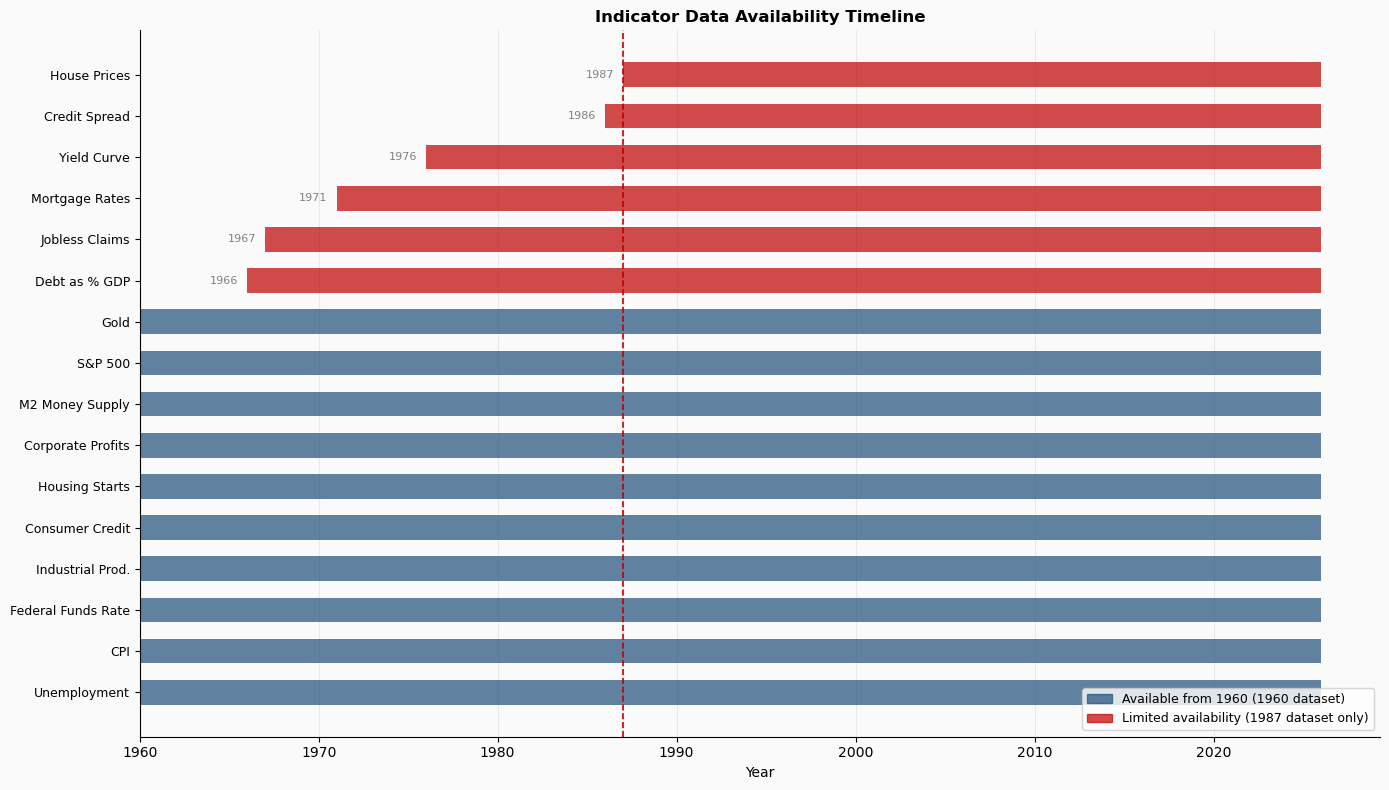

In [13]:
# Data Availability Timeline 

import matplotlib.patches as mpatches

indicators = {
    "Unemployment":        1960,
    "CPI":                 1960,
    "Federal Funds Rate":  1960,
    "Industrial Prod.":    1960,
    "Consumer Credit":     1960,
    "Housing Starts":      1960,
    "Corporate Profits":   1960,
    "M2 Money Supply":     1960,
    "S&P 500":             1960,
    "Gold":                1960,
    "Jobless Claims":      1967,
    "Mortgage Rates":      1971,
    "Yield Curve":         1976,
    "Debt as % GDP":       1966,
    "House Prices":        1987,
    "Credit Spread":       1986,
}

current_year = 2026
dataset_1960_cutoff = 1960
dataset_1987_cutoff = 1987

fig, ax = plt.subplots(figsize=(14, 8))
fig.patch.set_facecolor("#fafafa")
ax.set_facecolor("#fafafa")

sorted_indicators = sorted(indicators.items(), key=lambda x: x[1])

for i, (name, start) in enumerate(sorted_indicators):
    colour = "#1f4e79" if start <= dataset_1960_cutoff else "#c00000"
    ax.barh(i, current_year - start, left=start,
            color=colour, alpha=0.7, height=0.6)
    # only show start year label for non-1960 indicators
    if start > dataset_1960_cutoff:
        ax.text(start - 0.5, i, str(start), ha="right", va="center",
                fontsize=8, color="grey")

ax.axvline(dataset_1987_cutoff, color="#c00000", linestyle="--",
           linewidth=1.2, label="1987 dataset start")
ax.axvline(dataset_1960_cutoff, color="#1f4e79", linestyle="--",
           linewidth=1.2, label="1960 dataset start")

ax.set_yticks(range(len(sorted_indicators)))
ax.set_yticklabels([name for name, _ in sorted_indicators], fontsize=9)
ax.set_xlabel("Year", fontsize=10)
ax.set_title("Indicator Data Availability Timeline", fontsize=12,
             fontweight="bold")

patch_1960 = mpatches.Patch(color="#1f4e79", alpha=0.7,
                             label="Available from 1960 (1960 dataset)")
patch_1987 = mpatches.Patch(color="#c00000", alpha=0.7,
                             label="Limited availability (1987 dataset only)")
ax.legend(handles=[patch_1960, patch_1987], fontsize=9, loc="lower right")

ax.xaxis.grid(True, color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

## Joining the Datasets and Handling Missing Values

Once all indicators were collected and aligned to a consistent monthly frequency, two datasets were constructed by concatenating the relevant series along the column axis.

The **1960 dataset** contains ten indicators available from 1960, covering all nine NBER recession episodes from 1960 to present. Indicators with limited historical coverage such as house prices, yield curve, credit spread and mortgage rates were excluded from this dataset to avoid introducing large structural gaps into the training data. After handling missing values the dataset contains 787 rows and 10 feature columns plus the recession target variable.

The **1987 dataset** contains the full set of sixteen indicators from 1987 onwards, covering four recession episodes in the modern economic era. All indicators in this dataset have coverage from at least 1986, meaning any missing values at the start of the series are minor and addressable through interpolation. After handling missing values the dataset contains 451 rows and 16 feature columns plus the recession target variable.

After concatenation, missing values were handled as follows:

- **Time-based interpolation** was applied to both datasets using `interpolate(method="time")`, which fills gaps by linearly interpolating between known values weighted by the time distance between them. This is appropriate for economic time series where values change gradually and smoothly between observations.
- **Quarterly indicators** - corporate profits and federal debt as a percentage of GDP were resampled from quarterly to monthly frequency prior to concatenation using interpolation, creating smooth monthly estimates between quarterly release points.
- **Federal debt as a percentage of GDP** in the 1960 dataset contains structural missing values before 1966 where the series does not exist. These early NaNs were handled using back-fill from the first available observation rather than interpolation, as there are no prior values to interpolate from. This is noted as a limitation of the dataset.

Inspection of the tail end of both datasets revealed that all remaining missing values occur at the most recent end of the series, reflecting the natural reporting lag in official economic data. Indicators such as CPI, unemployment, industrial production and corporate profits are typically released with a one to two month delay, meaning the most recent months will always contain some NaNs at the time of data collection. Rather than dropping these rows, time-based interpolation was applied to fill them, as the values will become available on FRED as official releases are published. This means the datasets will become more complete over time as FRED is updated, and anyone running the data collection code at a later date will automatically retrieve the most recent available data.

After handling missing values, both datasets were verified to be complete with no remaining NaNs before proceeding to exploratory data analysis. Both datasets are saved to CSV in the data folder at this point, allowing subsequent sections to be run independently without re-executing the full data collection pipeline.

In [14]:
df_1960 = pd.concat([
    unemployment, cpi, fed_funds, industrial_production, recession,
     corporate_profits, m2, sp500, gold
], axis=1)

df_1987 = pd.concat([
    unemployment, cpi, fed_funds, industrial_production, recession,
    debt_gdp, corporate_profits, m2, sp500, gold,
    house_prices, yield_curve, jobless_claims, credit_spread,
    consumer_credit, housing_starts, mortgage_rates
], axis=1)

df_1987 = df_1987["1987-01-01":]

print(f"1960 Dataset Shape: {df_1960.shape}")
print(f"\nMissing Values:\n{df_1960.isnull().sum().to_string()}")
print("-"*40)
print(f"1987 Dataset Shape: {df_1987.shape}")
print(f"\nMissing Values:\n{df_1987.isnull().sum().to_string()}")

1960 Dataset Shape: (799, 9)

Missing Values:
unemployment             2
cpi                      2
fed_funds                1
industrial_production    1
recession                1
corporate_profits        6
m2                       2
sp500                    0
gold                     0
----------------------------------------
1987 Dataset Shape: (475, 17)

Missing Values:
unemployment             2
cpi                      2
fed_funds                1
industrial_production    1
recession                1
debt_gdp                 6
corporate_profits        6
m2                       2
sp500                    0
gold                     0
house_prices             3
yield_curve              0
jobless_claims           0
credit_spread            0
consumer_credit          2
housing_starts           1
mortgage_rates           0


In [15]:
df_1987.tail(10)

,unemployment,cpi,fed_funds,industrial_production,recession,debt_gdp,corporate_profits,m2,sp500,gold,house_prices,yield_curve,jobless_claims,credit_spread,consumer_credit,housing_starts,mortgage_rates
2025-10-01,NaN,NaN,4.09,101.2195,0.0,122.568150,3792.207000,22245.1,6688.46,4002.7699,328.849,0.540455,226750.000000,1.673182,5080761.86,1273.0,6.2540
2025-11-01,4.5,325.063,3.88,101.0344,0.0,122.576817,3845.605848,22277.3,6840.20,4217.3637,330.201,0.543889,222400.000000,1.763333,5084254.90,1319.0,6.2375
2025-12-01,4.4,326.031,3.72,101.4941,0.0,122.585203,3897.282152,22353.4,6849.09,4322.3617,331.403,0.642273,219250.000000,1.754545,5099408.78,1378.0,6.1900
2026-01-01,4.3,326.588,3.64,101.0388,0.0,122.593870,3950.681000,22429.3,6845.50,4865.3500,332.055,0.676500,211800.000000,1.665000,5103863.05,1385.0,6.1025
2026-02-01,4.4,327.460,3.64,101.9263,0.0,NaN,NaN,22626.9,6939.03,5277.8900,332.071,0.654211,215750.000000,1.686842,5111112.08,1346.0,6.0475
2026-03-01,4.3,330.293,3.64,101.6172,0.0,NaN,NaN,22686.2,6878.88,4670.3486,331.359,0.531364,208000.000000,1.789545,5133898.43,1522.0,6.1775
2026-04-01,4.3,332.407,3.64,102.4196,0.0,NaN,NaN,22804.5,6528.52,4629.5648,330.873,0.520000,207750.000000,1.711429,5154721.31,1414.0,6.3320
2026-05-01,4.3,333.979,3.63,102.5606,0.0,NaN,NaN,23052.3,7209.01,4541.8773,NaN,0.489000,211600.000000,1.619000,5154538.86,1199.0,6.4425
2026-06-01,4.2,332.568,3.63,102.6395,0.0,NaN,NaN,NaN,7580.06,4006.7000,NaN,0.357619,222500.000000,1.530476,NaN,1427.0,6.4900
2026-07-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7499.36,4030.3000,NaN,0.365000,204333.333333,1.575882,NaN,NaN,6.5125


In [16]:
df_1960 = df_1960.interpolate(method="time")
df_1987 = df_1987.interpolate(method="time")

In [17]:
df_1987.tail(10)

,unemployment,cpi,fed_funds,industrial_production,recession,debt_gdp,corporate_profits,m2,sp500,gold,house_prices,yield_curve,jobless_claims,credit_spread,consumer_credit,housing_starts,mortgage_rates
2025-10-01,4.44918,324.647295,4.09,101.2195,0.0,122.568150,3792.207000,22245.1,6688.46,4002.7699,328.849,0.540455,226750.000000,1.673182,5080761.86,1273.0,6.2540
2025-11-01,4.50000,325.063000,3.88,101.0344,0.0,122.576817,3845.605848,22277.3,6840.20,4217.3637,330.201,0.543889,222400.000000,1.763333,5084254.90,1319.0,6.2375
2025-12-01,4.40000,326.031000,3.72,101.4941,0.0,122.585203,3897.282152,22353.4,6849.09,4322.3617,331.403,0.642273,219250.000000,1.754545,5099408.78,1378.0,6.1900
2026-01-01,4.30000,326.588000,3.64,101.0388,0.0,122.593870,3950.681000,22429.3,6845.50,4865.3500,332.055,0.676500,211800.000000,1.665000,5103863.05,1385.0,6.1025
2026-02-01,4.40000,327.460000,3.64,101.9263,0.0,122.593870,3950.681000,22626.9,6939.03,5277.8900,332.071,0.654211,215750.000000,1.686842,5111112.08,1346.0,6.0475
2026-03-01,4.30000,330.293000,3.64,101.6172,0.0,122.593870,3950.681000,22686.2,6878.88,4670.3486,331.359,0.531364,208000.000000,1.789545,5133898.43,1522.0,6.1775
2026-04-01,4.30000,332.407000,3.64,102.4196,0.0,122.593870,3950.681000,22804.5,6528.52,4629.5648,330.873,0.520000,207750.000000,1.711429,5154721.31,1414.0,6.3320
2026-05-01,4.30000,333.979000,3.63,102.5606,0.0,122.593870,3950.681000,23052.3,7209.01,4541.8773,330.873,0.489000,211600.000000,1.619000,5154538.86,1199.0,6.4425
2026-06-01,4.20000,332.568000,3.63,102.6395,0.0,122.593870,3950.681000,23052.3,7580.06,4006.7000,330.873,0.357619,222500.000000,1.530476,5154538.86,1427.0,6.4900
2026-07-01,4.20000,332.568000,3.63,102.6395,0.0,122.593870,3950.681000,23052.3,7499.36,4030.3000,330.873,0.365000,204333.333333,1.575882,5154538.86,1427.0,6.5125


## Descriptive Statistics

Descriptive statistics were calculated for all indicators across both datasets to understand the distribution, central tendency, spread, and shape of each series before modelling. Statistics are generated automatically from the data and will reflect the most recent available observations each time the notebook is run.

### 1960 Dataset

Unemployment ranged from 3.40% to 14.80% with a mean of 5.85% and a positive skew of 0.94, reflecting the relatively rare but severe spikes in unemployment during recessionary periods. The Federal Funds Rate showed substantial variation from near zero in the post-2008 era to a peak of 19.10% during the early 1980s energy crisis, with positive skew and moderate kurtosis consistent with the presence of extreme high-rate periods. Industrial production showed slight negative skew (-0.13) and negative kurtosis (-1.48), suggesting a relatively flat distribution across the sample period reflecting long-run growth.

CPI ranged from 29.37 to 333.98 with near-zero skew (0.25) and negative kurtosis (-1.05), consistent with a broadly uniform upward trend over six decades rather than clustering around any particular level. Corporate profits and M2 money supply both showed strong right skew reflecting exponential long-run growth. The S&P 500 exhibited the highest skew (2.07) and kurtosis (4.25) of any indicator in this dataset, consistent with its long-term upward trajectory punctuated by sharp short-term declines. Gold showed even stronger right skew (2.32) and high kurtosis (7.22), reflecting the concentration of extreme price movements in recent decades.

Comparing recession and non-recession periods reveals clear differences across indicators. Unemployment averaged 6.61% during recessions versus 5.75% outside them. The Federal Funds Rate averaged 7.01% during recessions compared to 4.48% in non-recession periods, consistent with the pattern of monetary tightening preceding downturns. Industrial production averaged 58.17 during recessions versus 70.62 outside them, reflecting the sharp output contractions associated with economic downturns. Corporate profits, M2, S&P 500 and gold all showed substantially lower averages during recession periods, confirming their sensitivity to economic conditions.

Recession months represent approximately 11.1% of the 1960 dataset, with 95 recession months out of 787 total observations. This significant class imbalance is a fundamental characteristic of the data that directly shapes the modelling approach adopted in later sections.

### 1987 Dataset

The 1987 dataset shows broadly consistent patterns with the 1960 dataset for the shared indicators, though with higher baseline values reflecting the more recent time period. Several indicators unique to this dataset show notable characteristics.

The yield curve ranged from -0.93 to 2.83 with a mean of 0.97, capturing both normal upward sloping yield curve environments and the inverted periods that preceded recessions. Initial jobless claims showed extreme right skew (11.05) and very high kurtosis (159.42), driven by the unprecedented spike to 4,663,250 claims during the COVID-19 recession in April 2020 - a clear statistical outlier relative to the rest of the series. Credit spread ranged from 1.29 to 6.01 with positive skew (1.86) and high kurtosis (6.02), reflecting the sharp widening of spreads during financial stress periods such as the GFC.

Federal debt as a percentage of GDP ranged from 47.58% to 132.66% with a mean of 80.25% and negative kurtosis (-1.38), consistent with the broadly linear upward trend in US government debt over the period. House prices showed moderate right skew (0.90) reflecting the long-run upward trend in property values. Mortgage rates ranged from 2.68% to 11.26% with near-zero skew and negative kurtosis, consistent with the gradual long-run decline in rates from the peaks of the early 1990s to the historic lows of the post-2008 era.

Recession versus non-recession comparisons in the 1987 dataset reveal several notable patterns. Jobless claims averaged 627,765 during recessions compared to 339,834 outside them, nearly double, confirming their sensitivity to economic downturns. Credit spread averaged 3.42 during recessions versus 2.16 in non-recession periods, reflecting the increase in perceived default risk during downturns. The yield curve averaged 1.42 during recessions versus 0.93 outside them, which appears counterintuitive but reflects the fact that the yield curve often steepens again during recessions as short-term rates are cut aggressively while long-term rates remain elevated. Housing starts averaged 1,029 during recessions versus 1,364 outside them, consistent with the sharp slowdown in construction activity during economic downturns.

Recession months represent approximately 8.0% of the 1987 dataset, with 36 recession months out of 451 total observations, a more severe imbalance than the 1960 dataset reflecting the predominantly non-recessionary nature of the post-1987 period outside the four major downturns covered.

In [18]:
summary_1960 = df_1960.drop(columns=["recession"]).agg(
    ["min", "max", "mean", "median", "std", "var", 
     lambda x: x.quantile(0.25), 
     lambda x: x.quantile(0.75),
     lambda x: x.quantile(0.75) - x.quantile(0.25),
     "skew", "kurt"])

summary_1960.index = [
    "Min", "Max", "Mean", "Median", "Std Dev", "Variance",
    "Q1 (25%)", "Q3 (75%)", "IQR", "Skewness", "Kurtosis"]

display(summary_1960.T.round(2))

,Min,Max,Mean,Median,Std Dev,Variance,Q1 (25%),Q3 (75%),IQR,Skewness,Kurtosis
unemployment,3.40,14.80,5.85,5.60,1.69,2.87,4.60,6.90,2.30,0.94,1.11
cpi,29.37,333.98,144.98,143.80,86.89,7549.64,57.45,217.35,159.90,0.25,-1.05
fed_funds,0.05,19.10,4.78,4.66,3.60,12.98,2.00,6.48,4.48,0.98,1.51
industrial_production,22.13,104.10,69.14,64.91,26.52,703.23,45.71,97.13,51.42,-0.13,-1.48
corporate_profits,29.22,3950.68,874.44,349.00,1001.94,1003880.05,138.97,1518.63,1379.66,1.31,0.79
m2,298.20,23052.30,5913.39,3426.50,6263.66,39233379.27,1104.75,8500.05,7395.30,1.34,0.76
sp500,53.39,7580.06,1097.41,443.38,1459.51,2130183.62,102.84,1369.56,1266.73,2.07,4.25
gold,34.98,5277.89,660.87,379.00,775.83,601908.39,160.30,1062.75,902.45,2.32,7.22


In [19]:
summary_1987 = df_1987.drop(columns=["recession"]).agg(
    ["min", "max", "mean", "median", "std", "var", 
     lambda x: x.quantile(0.25), 
     lambda x: x.quantile(0.75),
     lambda x: x.quantile(0.75) - x.quantile(0.25),
     "skew", "kurt"])

summary_1987.index = [
    "Min", "Max", "Mean", "Median", "Std Dev", "Variance",
    "Q1 (25%)", "Q3 (75%)", "IQR", "Skewness", "Kurtosis"]

display(summary_1987.T.round(2))

,Min,Max,Mean,Median,Std Dev,Variance,Q1 (25%),Q3 (75%),IQR,Skewness,Kurtosis
unemployment,3.40,14.80,5.65,5.40,1.67,2.800000e+00,4.40,6.35,1.95,1.35,2.56
cpi,111.40,333.98,205.09,202.90,57.13,3.263510e+03,158.90,240.86,81.96,0.36,-0.68
fed_funds,0.05,9.85,3.26,3.09,2.61,6.810000e+00,0.40,5.32,4.92,0.32,-0.93
industrial_production,56.09,104.10,88.24,93.47,14.72,2.166500e+02,77.29,100.19,22.90,-0.88,-0.74
debt_gdp,47.58,132.66,80.25,64.45,25.25,6.374100e+02,59.98,102.86,42.88,0.44,-1.38
corporate_profits,191.69,3950.68,1392.66,1333.26,1011.57,1.023264e+06,535.79,1944.80,1409.01,0.77,-0.32
m2,2743.90,23052.30,9228.76,7001.70,6210.34,3.856832e+07,3806.85,13022.30,9215.45,0.90,-0.46
sp500,230.30,7580.06,1773.61,1257.64,1566.93,2.455256e+06,720.18,2147.21,1427.03,1.62,2.14
gold,254.60,5277.89,995.13,638.25,847.54,7.183214e+05,371.05,1340.05,969.00,1.93,4.98
house_prices,63.96,332.07,155.02,145.63,75.60,5.714790e+03,83.64,184.44,100.80,0.90,-0.03


In [20]:
features_1960 = [c for c in df_1960.columns if c != "recession"]

recession_summary_1960 = df_1960.groupby("recession")[features_1960].mean().round(2)
recession_summary_1960.index = ["Non-Recession", "Recession"]

display(recession_summary_1960)

,unemployment,cpi,fed_funds,industrial_production,corporate_profits,m2,sp500,gold
Non-Recession,5.75,149.77,4.48,70.62,937.77,6275.5,1184.28,696.55
Recession,6.61,109.44,7.01,58.17,405.14,3230.0,453.69,396.43


In [21]:
features_1987 = [c for c in df_1987.columns if c != "recession"]

recession_summary_1987 = df_1987.groupby("recession")[features_1987].mean().round(2)
recession_summary_1987.index = ["Non-Recession", "Recession"]

display(recession_summary_1987)

,unemployment,cpi,fed_funds,industrial_production,debt_gdp,corporate_profits,m2,sp500,gold,house_prices,yield_curve,jobless_claims,credit_spread,consumer_credit,housing_starts,mortgage_rates
Non-Recession,5.59,206.27,3.28,88.44,81.26,1434.75,9426.92,1833.11,1020.50,156.76,0.93,339794.72,2.16,2528977.83,1365.27,6.31
Recession,6.38,190.66,3.11,85.75,67.90,879.38,6812.30,1048.01,685.82,133.79,1.42,627765.28,3.42,2131838.26,1029.17,6.77


## Stationarity Testing

Prior to feature engineering, Augmented Dickey-Fuller (ADF) tests were conducted on all indicators to determine whether each series is stationary. A stationary series has a constant mean and variance over time and does not contain a unit root. Non-stationary series trend upward or downward over time, which can cause models to learn spurious relationships from the trend rather than genuine recession signals. The ADF test uses the AIC criterion for automatic lag selection to determine the optimal number of lags for each series.

The null hypothesis of the ADF test is that the series contains a unit root and is non-stationary. A p-value below 0.05 allows rejection of the null hypothesis, confirming stationarity. Results are presented in the colour coded table above, with green indicating stationary series and red indicating non-stationary series.

Results indicate that unemployment, the Federal Funds Rate, yield curve, jobless claims, credit spread and housing starts are stationary at the 5% significance level. These series fluctuate around a relatively stable mean over time and can be used directly as model features. This pattern is consistent across both datasets for the shared indicators, adding confidence to the findings.

The remaining indicators - CPI, industrial production, corporate profits, M2, S&P 500, gold, house prices, debt as a percentage of GDP, consumer credit and mortgage rates - are non-stationary, with p-values at or near 1.0 in several cases. These series exhibit clear long-run upward trends that are unrelated to the recession cycle. Including raw levels of these series as model features risks introducing spurious correlations, as the model may learn to associate high absolute values with recession or non-recession periods simply due to the time period rather than the underlying economic dynamics.

This finding directly informs the feature engineering approach in the following section. For non-stationary series, month-over-month percentage change and rolling mean features will capture economically meaningful signals such as acceleration, deceleration and trend direction, rather than the absolute level of the series. For stationary series, raw levels and lag features remain appropriate as the values themselves carry meaningful information about economic conditions.

In [22]:
# Stationarity Testing - Augmented Dickey-Fuller

from statsmodels.tsa.stattools import adfuller

def adf_test(series, name):
    clean = series.dropna()
    result = adfuller(clean, autolag="AIC")
    return {
        "Indicator":   name,
        "ADF Stat":    round(result[0], 4),
        "p-value":     round(result[1], 4),
        "Critical 1%": round(result[4]["1%"], 4),
        "Critical 5%": round(result[4]["5%"], 4),
        "Stationary":  "Yes" if result[1] < 0.05 else "No"
    }

In [23]:
# 1960 Dataset - Stationarity Results 

features_1960 = {
    "unemployment":          unemployment,
    "cpi":                   cpi,
    "fed_funds":             fed_funds,
    "industrial_production": industrial_production,
    "corporate_profits":     corporate_profits,
    "m2":                    m2,
    "sp500":                 sp500,
    "gold":                  gold,
}

results_1960 = pd.DataFrame([adf_test(s, n) for n, s in features_1960.items()])
results_1960 = results_1960.set_index("Indicator")
display(results_1960)

,ADF Stat,p-value,Critical 1%,Critical 5%,Stationary
Indicator,,,,,
unemployment,-3.3841,0.0115,-3.4386,-2.8652,Yes
cpi,2.0715,0.9988,-3.4388,-2.8652,No
fed_funds,-2.9892,0.0359,-3.4388,-2.8653,Yes
industrial_production,-1.3602,0.6012,-3.4387,-2.8652,No
corporate_profits,3.6625,1.0000,-3.4389,-2.8653,No
m2,3.5499,1.0000,-3.4388,-2.8653,No
sp500,5.4293,1.0000,-3.4388,-2.8653,No
gold,1.7944,0.9983,-3.4388,-2.8653,No


In [24]:
# 1987 Dataset - Stationarity Results

features_1987 = {
    "unemployment":          unemployment,
    "cpi":                   cpi,
    "fed_funds":             fed_funds,
    "industrial_production": industrial_production,
    "debt_gdp":              debt_gdp,
    "corporate_profits":     corporate_profits,
    "m2":                    m2,
    "sp500":                 sp500,
    "gold":                  gold,
    "house_prices":          house_prices,
    "yield_curve":           yield_curve,
    "jobless_claims":        jobless_claims,
    "credit_spread":         credit_spread,
    "consumer_credit":       consumer_credit,
    "housing_starts":        housing_starts,
    "mortgage_rates":        mortgage_rates,
}

results_1987 = pd.DataFrame([adf_test(s, n) for n, s in features_1987.items()])
results_1987 = results_1987.set_index("Indicator")
display(results_1987)

,ADF Stat,p-value,Critical 1%,Critical 5%,Stationary
Indicator,,,,,
unemployment,-3.3841,0.0115,-3.4386,-2.8652,Yes
cpi,2.0715,0.9988,-3.4388,-2.8652,No
fed_funds,-2.9892,0.0359,-3.4388,-2.8653,Yes
industrial_production,-1.3602,0.6012,-3.4387,-2.8652,No
debt_gdp,0.5572,0.9865,-3.4397,-2.8657,No
corporate_profits,3.6625,1.0000,-3.4389,-2.8653,No
m2,3.5499,1.0000,-3.4388,-2.8653,No
sp500,5.4293,1.0000,-3.4388,-2.8653,No
gold,1.7944,0.9983,-3.4388,-2.8653,No


In [25]:
# ADF Results Summary Table 

adf_summary = pd.concat([
    results_1960.assign(Dataset="1960"),
    results_1987.assign(Dataset="1987")
]).reset_index()

adf_summary = adf_summary.rename(columns={"Indicator": "Indicator"})

def colour_stationary(val):
    if val == "Yes":
        return "background-color: #d4edda; color: #155724"
    elif val == "No":
        return "background-color: #f8d7da; color: #721c24"
    return ""

display(adf_summary.style.applymap(
    colour_stationary, subset=["Stationary"]
).set_caption("ADF Test Results - Both Datasets"))

,Indicator,ADF Stat,p-value,Critical 1%,Critical 5%,Stationary,Dataset
0,unemployment,-3.384100,0.011500,-3.438600,-2.865200,Yes,1960
1,cpi,2.071500,0.998800,-3.438800,-2.865200,No,1960
2,fed_funds,-2.989200,0.035900,-3.438800,-2.865300,Yes,1960
3,industrial_production,-1.360200,0.601200,-3.438700,-2.865200,No,1960
4,corporate_profits,3.662500,1.000000,-3.438900,-2.865300,No,1960
5,m2,3.549900,1.000000,-3.438800,-2.865300,No,1960
6,sp500,5.429300,1.000000,-3.438800,-2.865300,No,1960
7,gold,1.794400,0.998300,-3.438800,-2.865300,No,1960
8,unemployment,-3.384100,0.011500,-3.438600,-2.865200,Yes,1987
9,cpi,2.071500,0.998800,-3.438800,-2.865200,No,1987


## Time Series Plots

Time series plots were generated for all indicators across both datasets, with NBER recession periods shaded in red. Each feature is plotted on a separate subplot with a shared x axis, allowing direct visual comparison of how each indicator behaves across the same time periods. Recession episode names are annotated on the top subplot for reference.

### 1960 Dataset

The time series plots confirm the long-run upward trends identified in the stationarity testing for CPI, corporate profits, M2, S&P 500 and gold - all show clear non-stationary behaviour with values increasing substantially over the six decade sample period. The recession shading reveals that most indicators show visible responses around recessionary periods, though the magnitude and direction vary by indicator.

Unemployment shows clear cyclical spikes at each recession window, confirming its sensitivity to economic downturns even in the raw series. The Federal Funds Rate shows the dramatic rise and fall associated with the Volcker tightening of the early 1980s, reaching its peak during the Energy Crisis recessions before declining steadily through subsequent decades to near zero after the GFC. Industrial production shows a broadly upward trend with visible dips at each recession episode, most pronounced during the GFC and COVID-19. Gold shows minimal movement in the pre-1970 period when prices were fixed under the Bretton Woods system, followed by sharp appreciation during the Oil Shock and Energy Crisis periods and again from the mid-2000s onwards.

### 1987 Dataset

The 1987 dataset plots show a cleaner set of indicators given the shorter and more recent sample period. The yield curve plot is particularly informative, showing clear inversions - where the line dips below zero - in the periods preceding the Dot-Com recession, the GFC and COVID-19, visually confirming the lead/lag analysis finding that yield curve inversion is one of the strongest recession predictors. Credit spread shows sharp spikes during the GFC and COVID-19 recessions, consistent with the widening of corporate bond spreads during periods of financial stress. Housing starts shows a dramatic collapse during the GFC that is visually distinct from all other recession episodes, reflecting the central role of the housing market in that particular downturn.

The time series plots provide an accessible visual foundation for understanding the data before moving into more formal statistical analysis, and confirm that the indicators selected capture a broad range of economic dynamics across the business cycle.

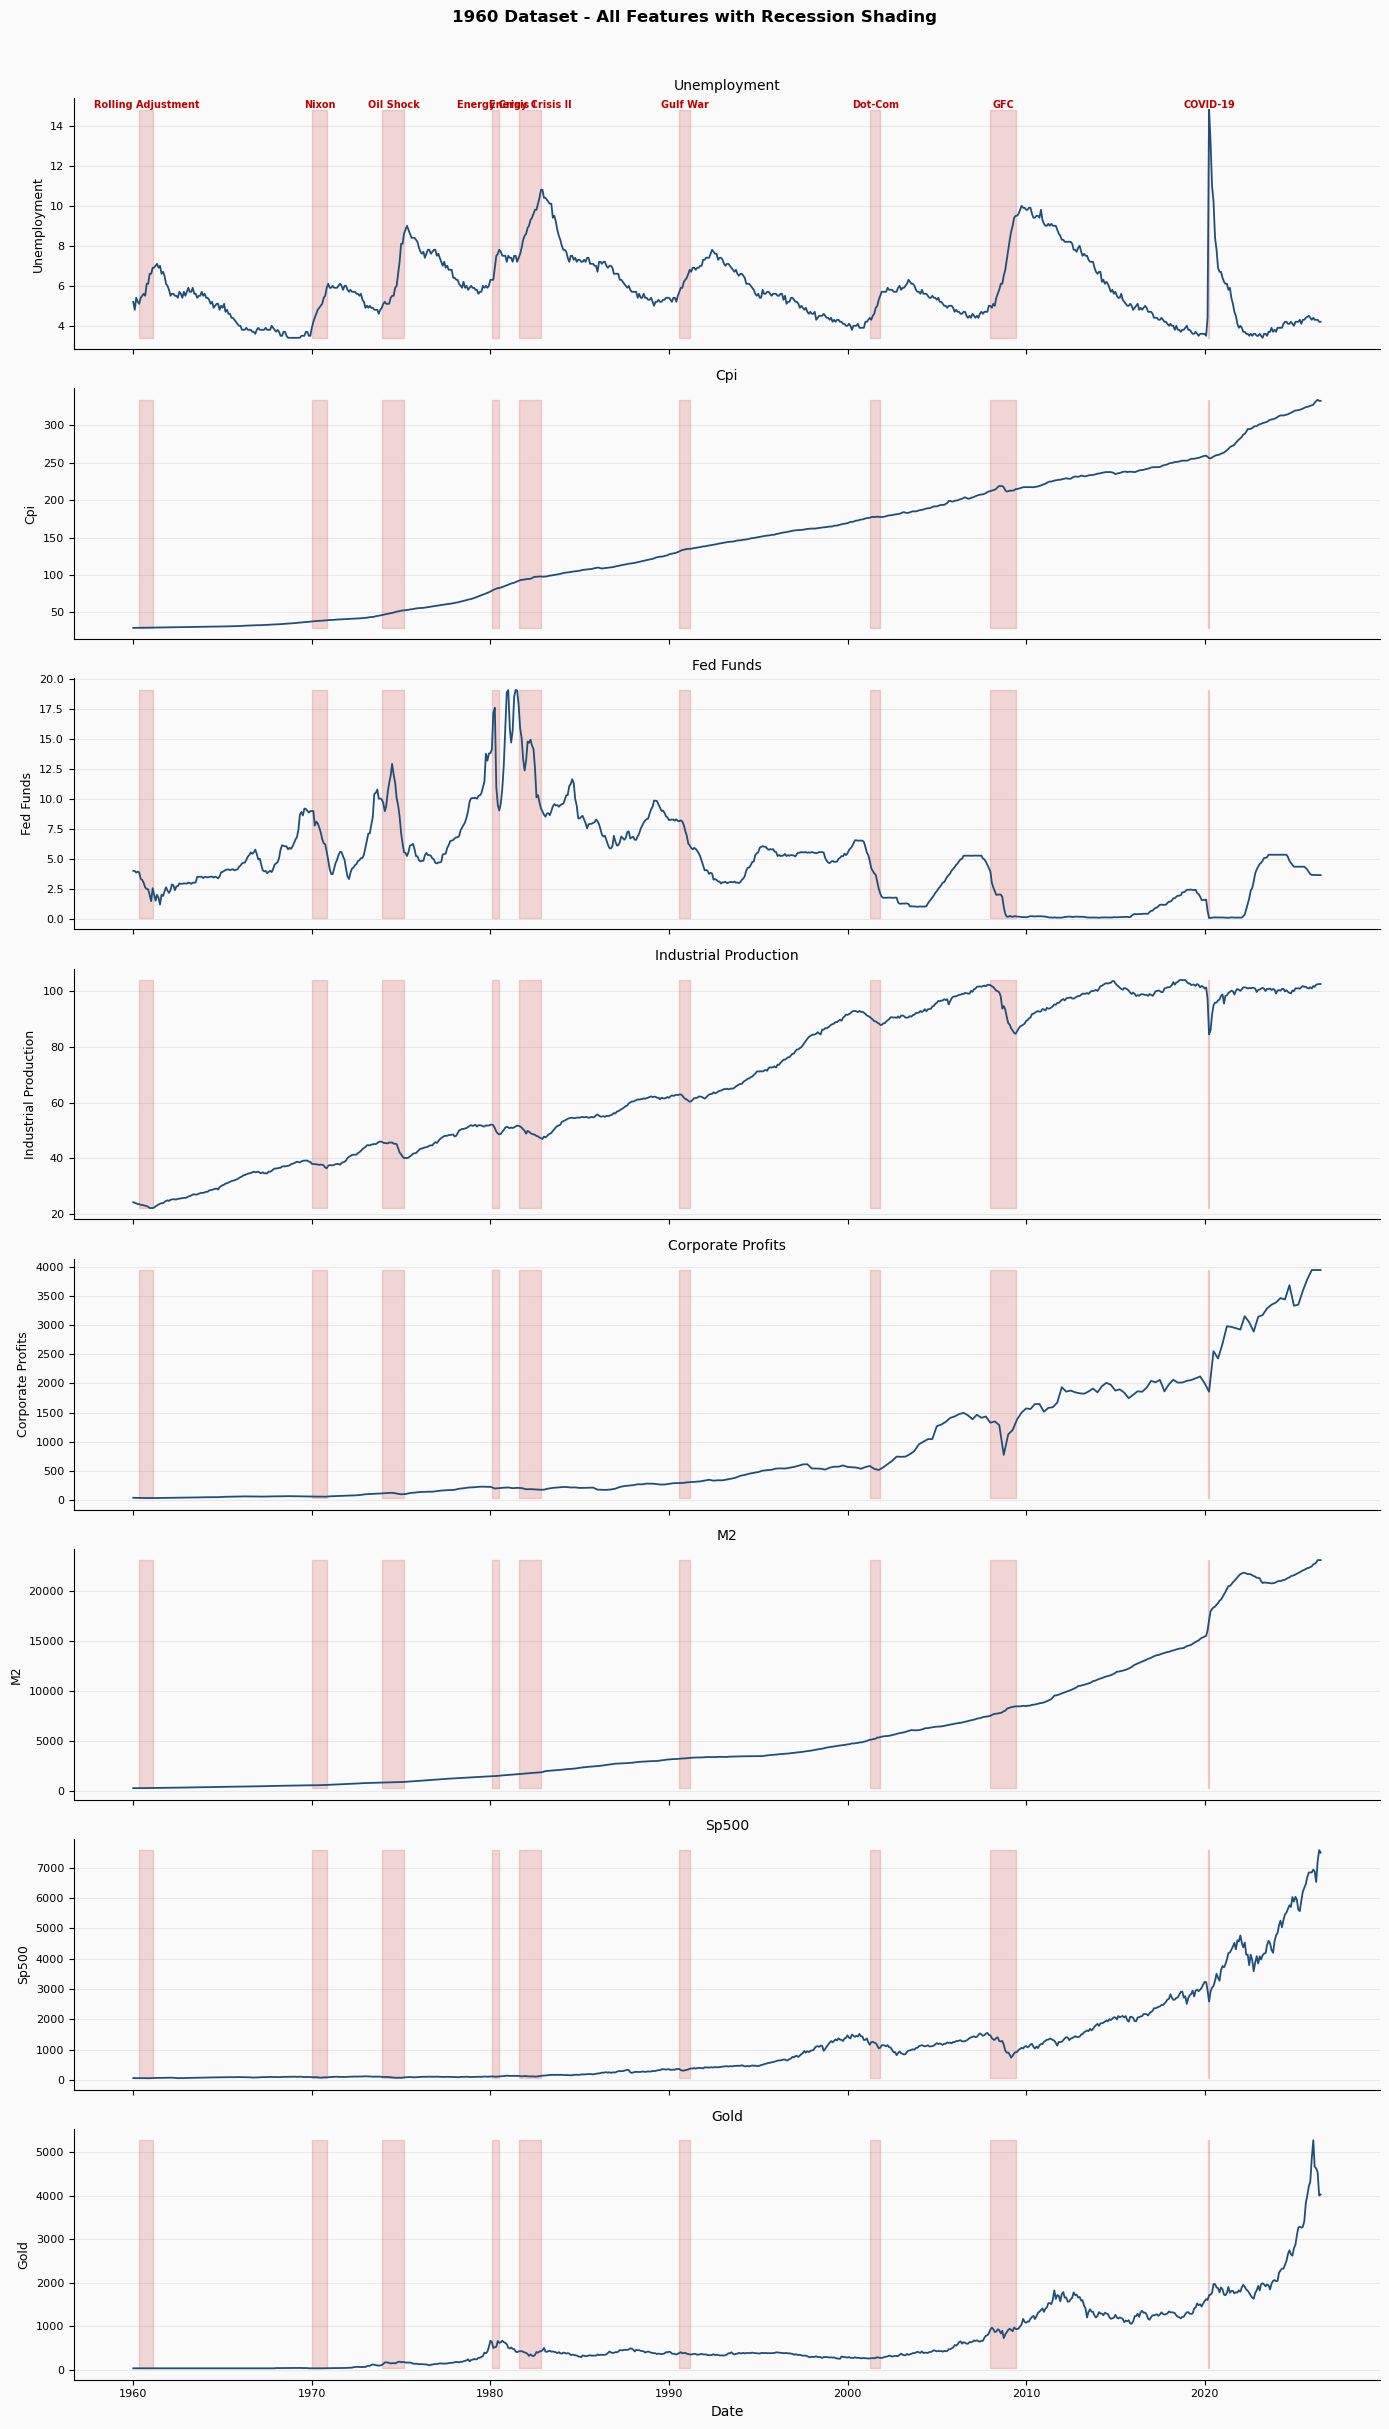

In [26]:
# Time Series Plots - 1960 Dataset

RECESSION_NAMES_1960 = {
    "1960-05-01": "Rolling Adjustment",
    "1970-01-01": "Nixon",
    "1973-12-01": "Oil Shock",
    "1980-02-01": "Energy Crisis I",
    "1981-08-01": "Energy Crisis II",
    "1990-08-01": "Gulf War",
    "2001-04-01": "Dot-Com",
    "2008-01-01": "GFC",
    "2020-03-01": "COVID-19",
}

features_1960_plot = [c for c in df_1960.columns if c != "recession"]

fig, axes = plt.subplots(len(features_1960_plot), 1,
                          figsize=(14, 3 * len(features_1960_plot)), sharex=True)
fig.patch.set_facecolor("#fafafa")

for ax, feat in zip(axes, features_1960_plot):
    ax.set_facecolor("#fafafa")
    ax.plot(df_1960.index, df_1960[feat], color="#1f4e79", linewidth=1.3)
    ax.fill_between(df_1960.index, df_1960[feat].min(), df_1960[feat].max(),
                    where=(df_1960["recession"] == 1), color="#c00000", alpha=0.15)
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_title(feat.replace("_", " ").title(), fontsize=10)
    ax.set_ylabel(feat.replace("_", " ").title(), fontsize=9)
    ax.tick_params(labelsize=8)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    if feat == features_1960_plot[0]:
        in_rec = False
        for date, row in df_1960.iterrows():
            if row["recession"] == 1 and not in_rec:
                rec_start = date
                in_rec = True
            elif row["recession"] == 0 and in_rec:
                mid = rec_start + (date - rec_start) / 2
                label = RECESSION_NAMES_1960.get(str(rec_start.date()), "")
                ax.text(mid, df_1960[feat].max(), label,
                        ha="center", va="bottom", fontsize=7,
                        color="#c00000", fontweight="bold")
                in_rec = False

axes[-1].set_xlabel("Date", fontsize=10)
fig.suptitle("1960 Dataset - All Features with Recession Shading", fontsize=12,
             fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

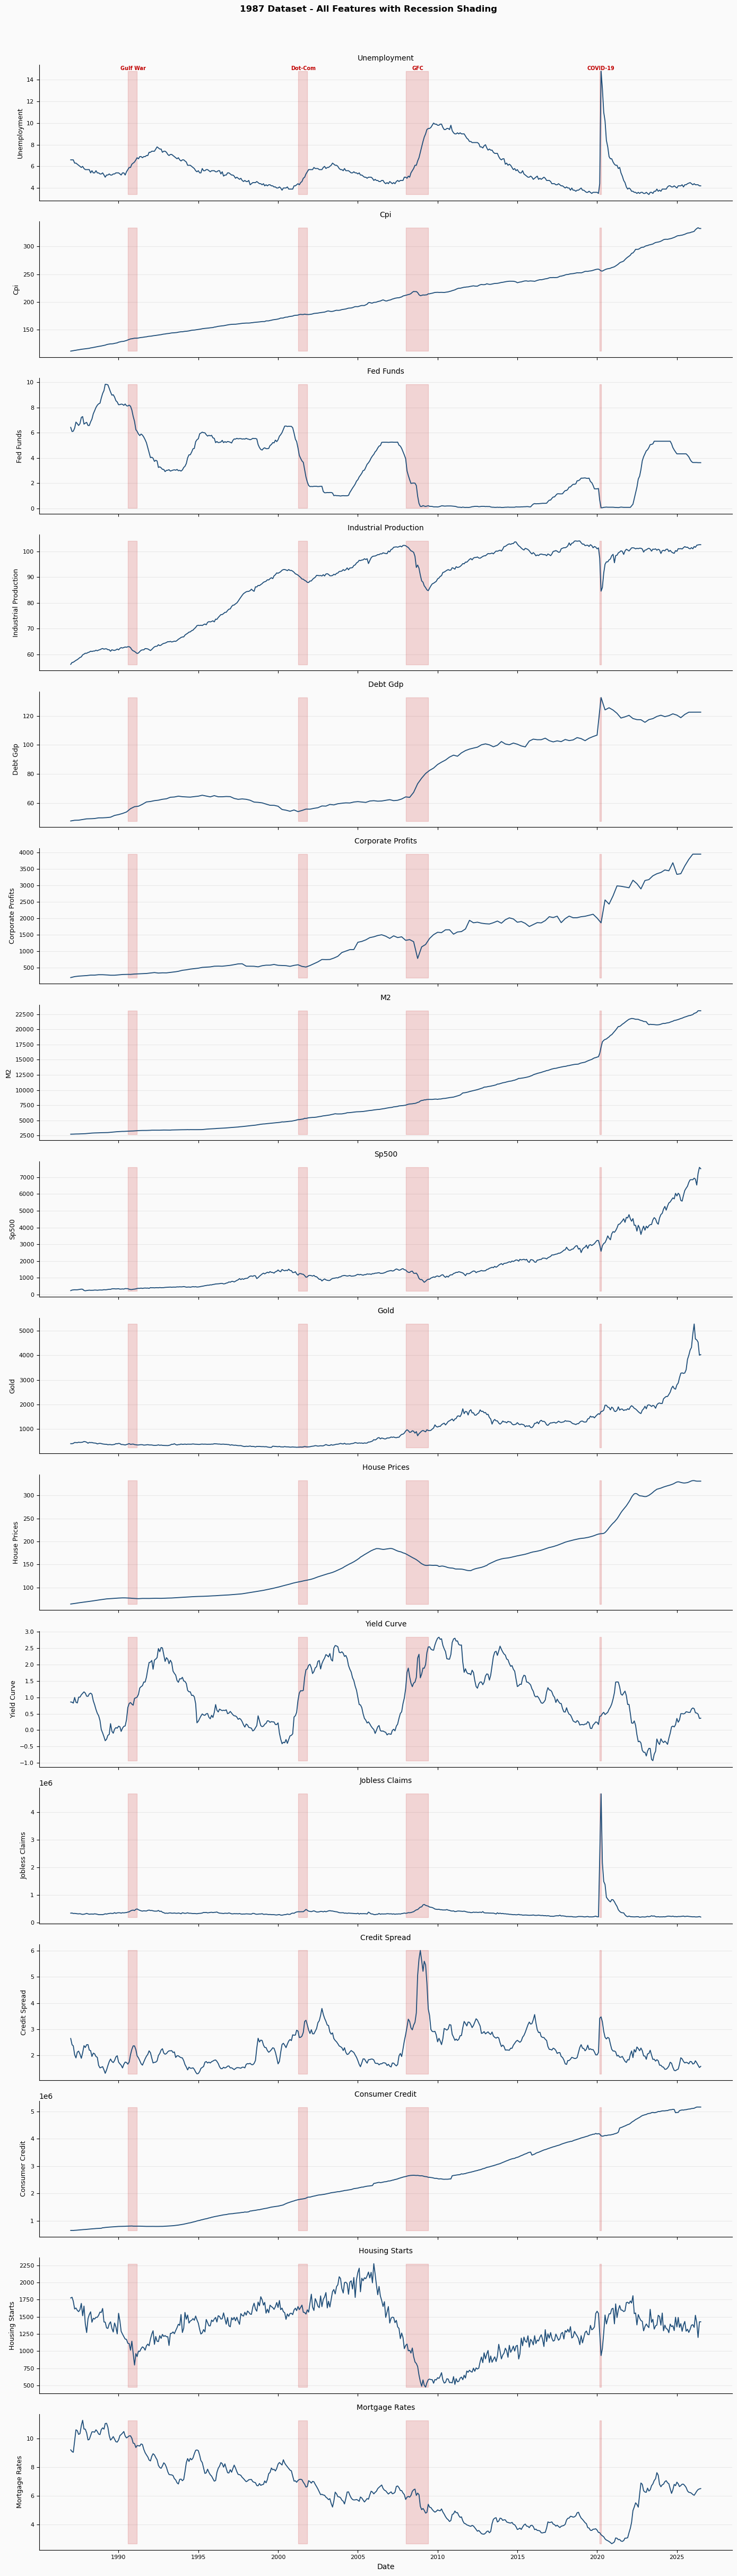

In [27]:
# Time Series Plots - 1987 Dataset 

RECESSION_NAMES_1987 = {
    "1990-08-01": "Gulf War",
    "2001-04-01": "Dot-Com",
    "2008-01-01": "GFC",
    "2020-03-01": "COVID-19",
}

features_1987_plot = [c for c in df_1987.columns if c != "recession"]

fig, axes = plt.subplots(len(features_1987_plot), 1,
                          figsize=(14, 3 * len(features_1987_plot)), sharex=True)
fig.patch.set_facecolor("#fafafa")

for ax, feat in zip(axes, features_1987_plot):
    ax.set_facecolor("#fafafa")
    ax.plot(df_1987.index, df_1987[feat], color="#1f4e79", linewidth=1.3)
    ax.fill_between(df_1987.index, df_1987[feat].min(), df_1987[feat].max(),
                    where=(df_1987["recession"] == 1), color="#c00000", alpha=0.15)
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.set_title(feat.replace("_", " ").title(), fontsize=10)
    ax.set_ylabel(feat.replace("_", " ").title(), fontsize=9)
    ax.tick_params(labelsize=8)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    if feat == features_1987_plot[0]:
        in_rec = False
        for date, row in df_1987.iterrows():
            if row["recession"] == 1 and not in_rec:
                rec_start = date
                in_rec = True
            elif row["recession"] == 0 and in_rec:
                mid = rec_start + (date - rec_start) / 2
                label = RECESSION_NAMES_1987.get(str(rec_start.date()), "")
                ax.text(mid, df_1987[feat].max(), label,
                        ha="center", va="bottom", fontsize=7,
                        color="#c00000", fontweight="bold")
                in_rec = False

axes[-1].set_xlabel("Date", fontsize=10)
fig.suptitle("1987 Dataset - All Features with Recession Shading", fontsize=12,
             fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

## Phase and Episode Analysis

To understand how each indicator behaves around recessionary periods, average values were calculated for the twelve months before, during, and after each recession episode. A twelve month window was chosen to capture the typical lead and lag dynamics identified in the literature while remaining narrow enough to avoid overlap between adjacent recession episodes. This analysis was conducted across both datasets and broken down by individual episode to capture variation in recession dynamics over time, covering all nine episodes in the 1960 dataset and four in the 1987 dataset.

### 1960 Dataset

**Unemployment** rose during and continued rising after every single recession without exception, confirming its well-documented lagging nature. The COVID-19 recession shows the most dramatic spike, jumping from 3.62% before to 9.60% during, before falling back to 7.98% after - a pattern unique among all episodes where unemployment typically continues rising in the post-recession period. The GFC shows the most persistent increase, rising from 4.62% before to 9.76% after, reflecting the prolonged labour market recovery following the financial crisis.

**Federal Funds Rate** peaked in the pre-recession phase and declined during and after in almost every episode, reflecting monetary policy easing in response to economic weakness. The pattern is most pronounced in the Dot-Com and GFC episodes, where rates fell from 6.22% to 1.72% and 5.02% to 0.15% respectively. The Energy Crisis I episode is the notable exception, where rates continued rising during and after the recession as the Fed prioritised inflation control over economic stimulus.

**Industrial Production** declined during recessions in most episodes. The GFC and COVID-19 show the sharpest contractions, with production continuing to fall after the GFC reflecting the prolonged nature of that recovery. The Oil Shock recession saw production continue declining after the recession ended, consistent with the structural disruption to manufacturing caused by the energy supply shock.

**Corporate Profits** fell during most recessions before recovering strongly in the aftermath. The GFC saw the sharpest contraction, falling from 1,417.50 before to 1,178.94 during. M2 money supply grew consistently through every recession episode, reflecting expansionary monetary policy responses.

**S&P 500** generally declined during recessions but at varying speeds. The Dot-Com recession stands out as the post-recession value (1,027.87) was lower than the during-recession average (1,166.94), reflecting the prolonged market weakness of that period. The COVID-19 recession saw the fastest recovery, with the S&P 500 rising from 2,769.40 during to 3,444.78 after.

**Gold** showed markedly different behaviour across episodes. During the 1960s and early 1970s gold prices were fixed and showed no movement. The Oil Shock and Energy Crisis I saw dramatic gold price spikes consistent with inflation hedging. The GFC and COVID-19 saw strong gold appreciation during and after the recession, consistent with safe haven demand during periods of financial uncertainty.

### 1987 Dataset

**Yield Curve** showed a consistent pattern of being flat or slightly negative before recessions and steepening sharply during and after. Before the Dot-Com recession the yield curve was inverted at -0.10, rising to 1.37 during and 1.96 after as short-term rates were cut aggressively. This steepening during recessions reflects the speed at which central banks cut short-term rates relative to long-term yields.

**Jobless Claims** nearly doubled during every modern recession. The COVID-19 episode represents an extreme outlier, with claims spiking from 216,050 before to 3,499,250 during - more than fifteen times the pre-recession level - before falling to 1,003,813 after. Excluding COVID-19, the GFC showed the most sustained increase with claims remaining elevated at 500,233 in the post-recession period.

**Credit Spread** widened during every recession without exception, reflecting increased perceived default risk. The GFC saw the most dramatic widening, from 1.85 before to 4.21 during, more than double the pre-recession level, consistent with the severe financial market stress of that period. Credit spread remained elevated after the GFC at 2.82, suggesting prolonged market uncertainty in the recovery period.

**Housing Starts** fell sharply during most recessions. The GFC saw the most severe and persistent decline, falling from 1,341.83 before to 776.67 during and continuing to 594.00 after - less than half the pre-recession level - reflecting the central role of the housing market collapse in that downturn. In contrast, housing starts rose during the Dot-Com recession, suggesting the housing market remained largely insulated from that technology-driven downturn.

**Debt as a percentage of GDP** rose during and after every recession as government borrowing increased to fund stimulus measures. The GFC saw the most dramatic increase, rising from 62.26% before to 85.87% after. The COVID-19 recession saw debt/GDP spike to 128.25% during the recession before falling slightly to 124.81% after, reflecting the unprecedented scale of pandemic-related fiscal stimulus.

**Mortgage Rates** declined consistently during and after every modern recession, tracking the broader decline in interest rates as monetary policy was eased. Rates fell from 10.08% before the Gulf War recession to 3.79% before COVID-19, reflecting the long-run structural decline in interest rates over the modern era.

### Summary

Several consistent patterns emerge across both datasets and all recession episodes. Unemployment is the most reliable lagging indicator, rising during and persisting after every episode without exception. The Federal Funds Rate consistently peaks before recessions and declines during them, confirming the role of monetary policy tightening as a precursor to economic downturns. Credit spread and jobless claims are the most responsive near-term indicators in the 1987 dataset, widening and rising sharply at or immediately before recession onset. The COVID-19 recession stands apart from all other episodes in the speed and magnitude of its labour market shock, while the GFC is unique in the severity and persistence of its impact on housing, credit markets and the broader economy. These patterns directly informed the selection of lag windows and feature types in the feature engineering stage.

In [28]:
# Episode Detection 

RECESSION_NAMES = {
    pd.Timestamp("1960-05-01"): "Rolling Adjustment",
    pd.Timestamp("1970-01-01"): "Nixon",
    pd.Timestamp("1973-12-01"): "Oil Shock",
    pd.Timestamp("1980-02-01"): "Energy Crisis I",
    pd.Timestamp("1981-08-01"): "Energy Crisis II",
    pd.Timestamp("1990-08-01"): "Gulf War",
    pd.Timestamp("2001-04-01"): "Dot-Com",
    pd.Timestamp("2008-01-01"): "GFC",
    pd.Timestamp("2020-03-01"): "COVID-19",
}

def get_episodes(df):
    starts = df.index[(df["recession"] == 1) & (df["recession"].shift(1, fill_value=0) == 0)]
    ends   = df.index[(df["recession"] == 1) & (df["recession"].shift(-1, fill_value=0) == 0)]
    episodes = pd.DataFrame({"start": starts, "end": ends})
    episodes["name"] = episodes["start"].map(RECESSION_NAMES)
    return episodes

episodes_1960 = get_episodes(df_1960)
episodes_1987 = get_episodes(df_1987)

display(episodes_1960)
display(episodes_1987)

,start,end,name
0,1960-05-01,1961-02-01,Rolling Adjustment
1,1970-01-01,1970-11-01,Nixon
2,1973-12-01,1975-03-01,Oil Shock
3,1980-02-01,1980-07-01,Energy Crisis I
4,1981-08-01,1982-11-01,Energy Crisis II
5,1990-08-01,1991-03-01,Gulf War
6,2001-04-01,2001-11-01,Dot-Com
7,2008-01-01,2009-06-01,GFC
8,2020-03-01,2020-04-01,COVID-19


,start,end,name
0,1990-08-01,1991-03-01,Gulf War
1,2001-04-01,2001-11-01,Dot-Com
2,2008-01-01,2009-06-01,GFC
3,2020-03-01,2020-04-01,COVID-19


In [29]:
# Phase Labelling 

def label_phases(df, episodes, months=12):
    df_out = df.copy()
    df_out["phase"] = "other"
    for _, row in episodes.iterrows():
        s, e = row["start"], row["end"]
        df_out.loc[s - pd.DateOffset(months=months): s - pd.DateOffset(months=1), "phase"] = "before"
        df_out.loc[s:e, "phase"] = "during"
        df_out.loc[e + pd.DateOffset(months=1): e + pd.DateOffset(months=months), "phase"] = "after"
    return df_out

df_1960_phased = label_phases(df_1960, episodes_1960)
df_1987_phased = label_phases(df_1987, episodes_1987)

In [30]:
# Phase Summary - 1960 Dataset

features_1960_phase = [c for c in df_1960.columns if c != "recession"]

phase_summary_1960 = (
    df_1960_phased[df_1960_phased["phase"] != "other"]
    .groupby("phase")[features_1960_phase]
    .mean()
    .loc[["before", "during", "after"]]
    .round(2)
)

display(phase_summary_1960)

,unemployment,cpi,fed_funds,industrial_production,corporate_profits,m2,sp500,gold
phase,,,,,,,,
before,4.92,121.98,8.03,66.29,589.14,4192.11,800.19,462.26
during,6.61,109.44,7.01,58.17,405.14,3230.00,453.69,396.43
after,7.64,127.33,3.53,61.11,684.10,5053.86,793.22,529.55


In [31]:
# Phase Summary - 1987 Dataset

features_1987_phase = [c for c in df_1987.columns if c != "recession"]

phase_summary_1987 = (
    df_1987_phased[df_1987_phased["phase"] != "other"]
    .groupby("phase")[features_1987_phase]
    .mean()
    .loc[["before", "during", "after"]]
    .round(2)
)

display(phase_summary_1987)

,unemployment,cpi,fed_funds,industrial_production,debt_gdp,corporate_profits,m2,sp500,gold,house_prices,yield_curve,jobless_claims,credit_spread,consumer_credit,housing_starts,mortgage_rates
phase,,,,,,,,,,,,,,,,
before,4.40,191.28,5.43,89.54,68.77,1077.62,7593.12,1551.73,702.22,143.66,0.11,302288.54,2.09,2282071.86,1391.85,6.99
during,6.38,190.66,3.11,85.75,67.90,879.38,6812.30,1048.01,685.82,133.79,1.42,627765.28,3.42,2131838.26,1029.17,6.77
after,7.63,198.59,1.76,84.04,81.82,1264.59,9100.98,1483.67,896.87,144.00,1.76,586568.75,2.58,2352918.61,1211.96,5.90


In [32]:
# Per-Episode Phase Breakdown 

def episode_phase_table(df, episodes, feature, months=12):
    rows = {}
    for _, ep in episodes.dropna(subset=["name"]).iterrows():
        s, e = ep["start"], ep["end"]
        rows[ep["name"]] = {
            "before": df.loc[s - pd.DateOffset(months=months): s - pd.DateOffset(months=1), feature].mean(),
            "during": df.loc[s:e, feature].mean(),
            "after":  df.loc[e + pd.DateOffset(months=1): e + pd.DateOffset(months=months), feature].mean(),
        }
    return pd.DataFrame(rows).T.round(2)

print("1960 Dataset - Per Episode Phase Breakdown")
for feat in features_1960_phase:
    print(f"\n{feat}")
    display(episode_phase_table(df_1960, episodes_1960, feat))

1960 Dataset - Per Episode Phase Breakdown

unemployment


,before,during,after
Rolling Adjustment,5.15,5.94,6.51
Nixon,3.49,4.88,5.96
Oil Shock,4.88,6.09,8.34
Energy Crisis I,5.88,7.07,7.43
Energy Crisis II,7.43,9.09,9.81
Gulf War,5.33,6.22,7.04
Dot-Com,4.02,4.81,5.76
GFC,4.62,6.79,9.76
COVID-19,3.62,9.60,7.98



cpi


,before,during,after
Rolling Adjustment,29.43,29.70,29.94
Nixon,36.68,38.75,40.38
Oil Shock,44.11,49.74,54.66
Energy Crisis I,73.38,81.13,87.37
Energy Crisis II,87.37,95.46,99.28
Gulf War,127.45,133.71,137.14
Dot-Com,173.64,177.42,179.50
GFC,207.34,214.48,216.76
COVID-19,256.69,257.05,260.97



fed_funds


...

,before,during,after
Rolling Adjustment,299.00,308.60,328.75
Nixon,578.72,599.18,667.42
Oil Shock,827.32,885.48,994.46
Energy Crisis I,1434.92,1513.93,1621.14
Energy Crisis II,1621.14,1792.43,2036.33
Gulf War,3161.94,3275.55,3364.68
Dot-Com,4876.23,5249.58,5569.92
GFC,7308.00,7996.86,8518.80
COVID-19,15026.31,16549.15,18950.49



sp500


,before,during,after
Rolling Adjustment,56.74,56.19,67.24
Nixon,98.56,83.10,96.81
Oil Shock,109.94,83.12,90.63
Energy Crisis I,103.33,110.28,130.56
Energy Crisis II,130.56,119.05,156.38
Gulf War,344.78,331.52,390.74
Dot-Com,1406.82,1166.94,1027.87
GFC,1473.92,1122.32,1071.28
COVID-19,2981.41,2769.40,3444.78



gold


,before,during,after
Rolling Adjustment,35.31,35.31,35.31
Nixon,40.84,35.86,40.46
Oil Shock,95.99,161.76,148.25
Energy Crisis I,357.22,579.07,537.44
Energy Crisis II,537.44,385.12,424.94
Gulf War,380.84,379.48,355.78
Dot-Com,271.45,273.36,307.34
GFC,704.68,896.96,1095.29
COVID-19,1451.93,1660.70,1829.06


In [33]:
print("1987 Dataset - Per Episode Phase Breakdown")
for feat in features_1987_phase:
    print(f"\n{feat}")
    display(episode_phase_table(df_1987, episodes_1987, feat))

1987 Dataset - Per Episode Phase Breakdown

unemployment


,before,during,after
Gulf War,5.33,6.22,7.04
Dot-Com,4.02,4.81,5.76
GFC,4.62,6.79,9.76
COVID-19,3.62,9.60,7.98



cpi


,before,during,after
Gulf War,127.45,133.71,137.14
Dot-Com,173.64,177.42,179.50
GFC,207.34,214.48,216.76
COVID-19,256.69,257.05,260.97



fed_funds


...

,before,during,after
Gulf War,794555.67,809465.74,801797.56
Dot-Com,1671296.71,1806536.12,1918109.46
GFC,2531514.79,2641287.24,2550211.45
COVID-19,4130920.28,4137496.04,4141555.97



housing_starts


,before,during,after
Gulf War,1309.00,1004.62,1095.33
Dot-Com,1559.83,1603.88,1691.92
GFC,1341.83,776.67,594.00
COVID-19,1356.75,1101.00,1466.58



mortgage_rates


,before,during,after
Gulf War,10.08,9.83,9.05
Dot-Com,7.75,6.94,6.62
GFC,6.34,5.71,4.99
COVID-19,3.79,3.38,2.93


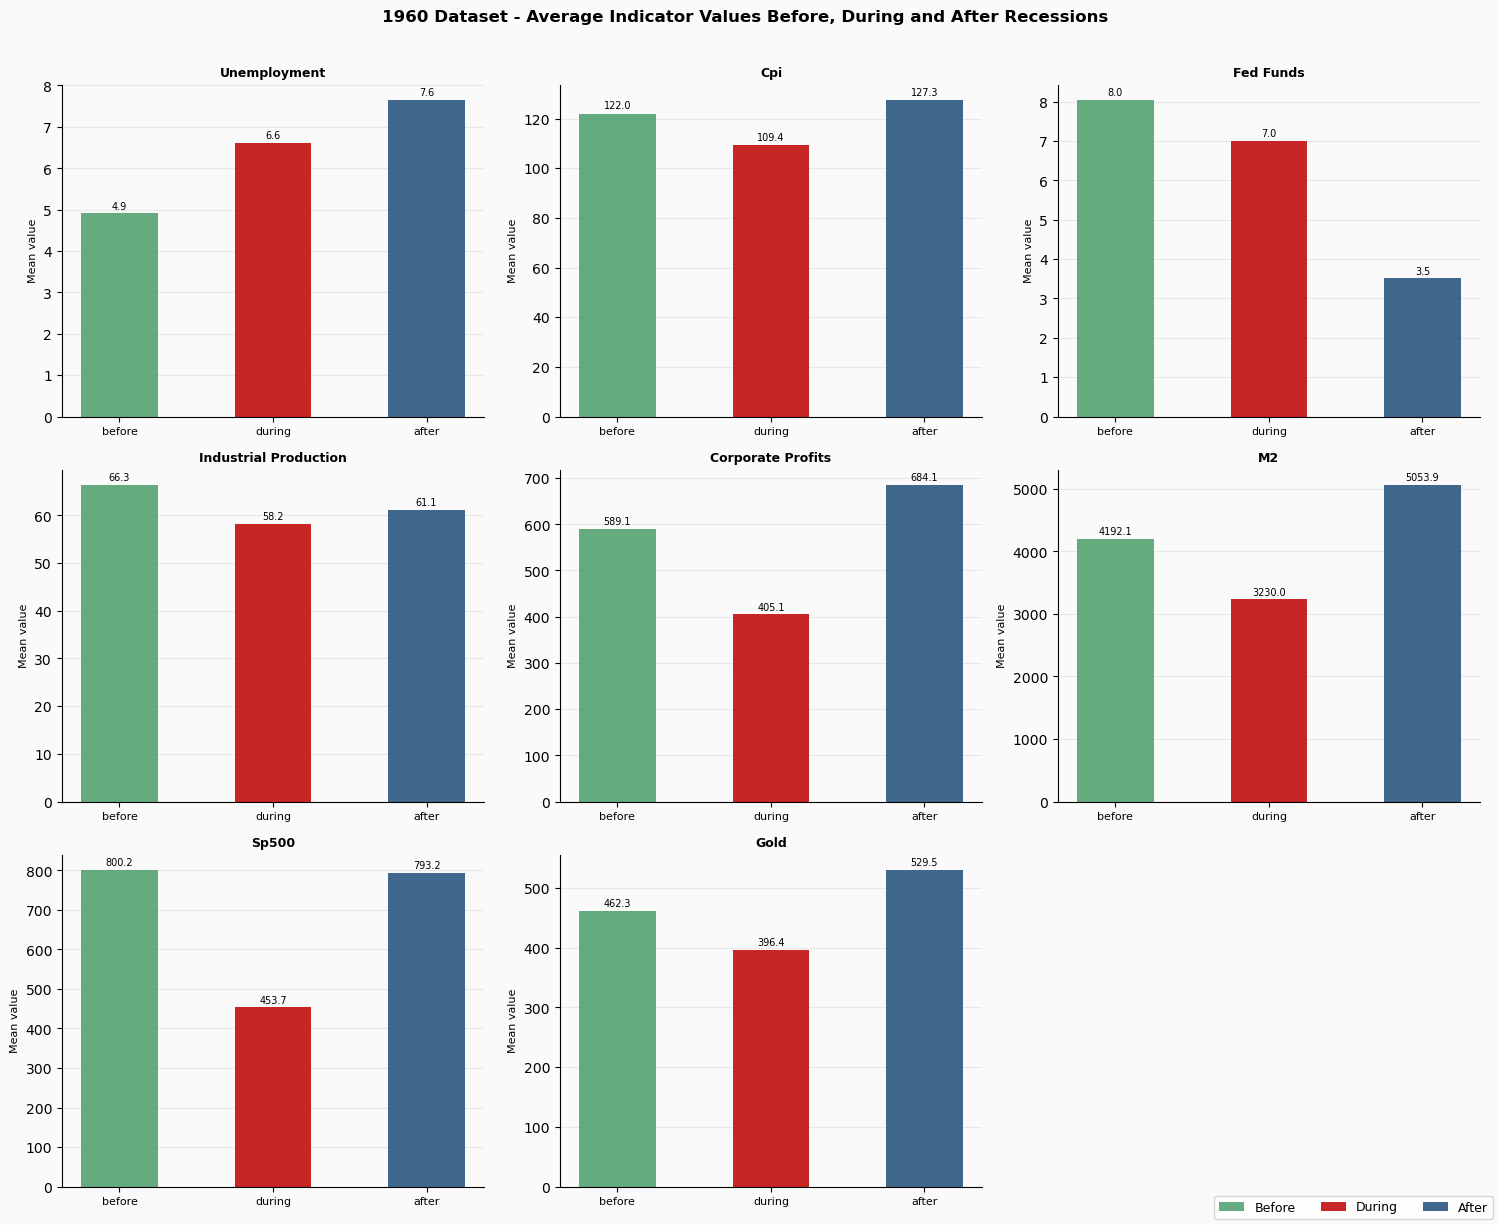

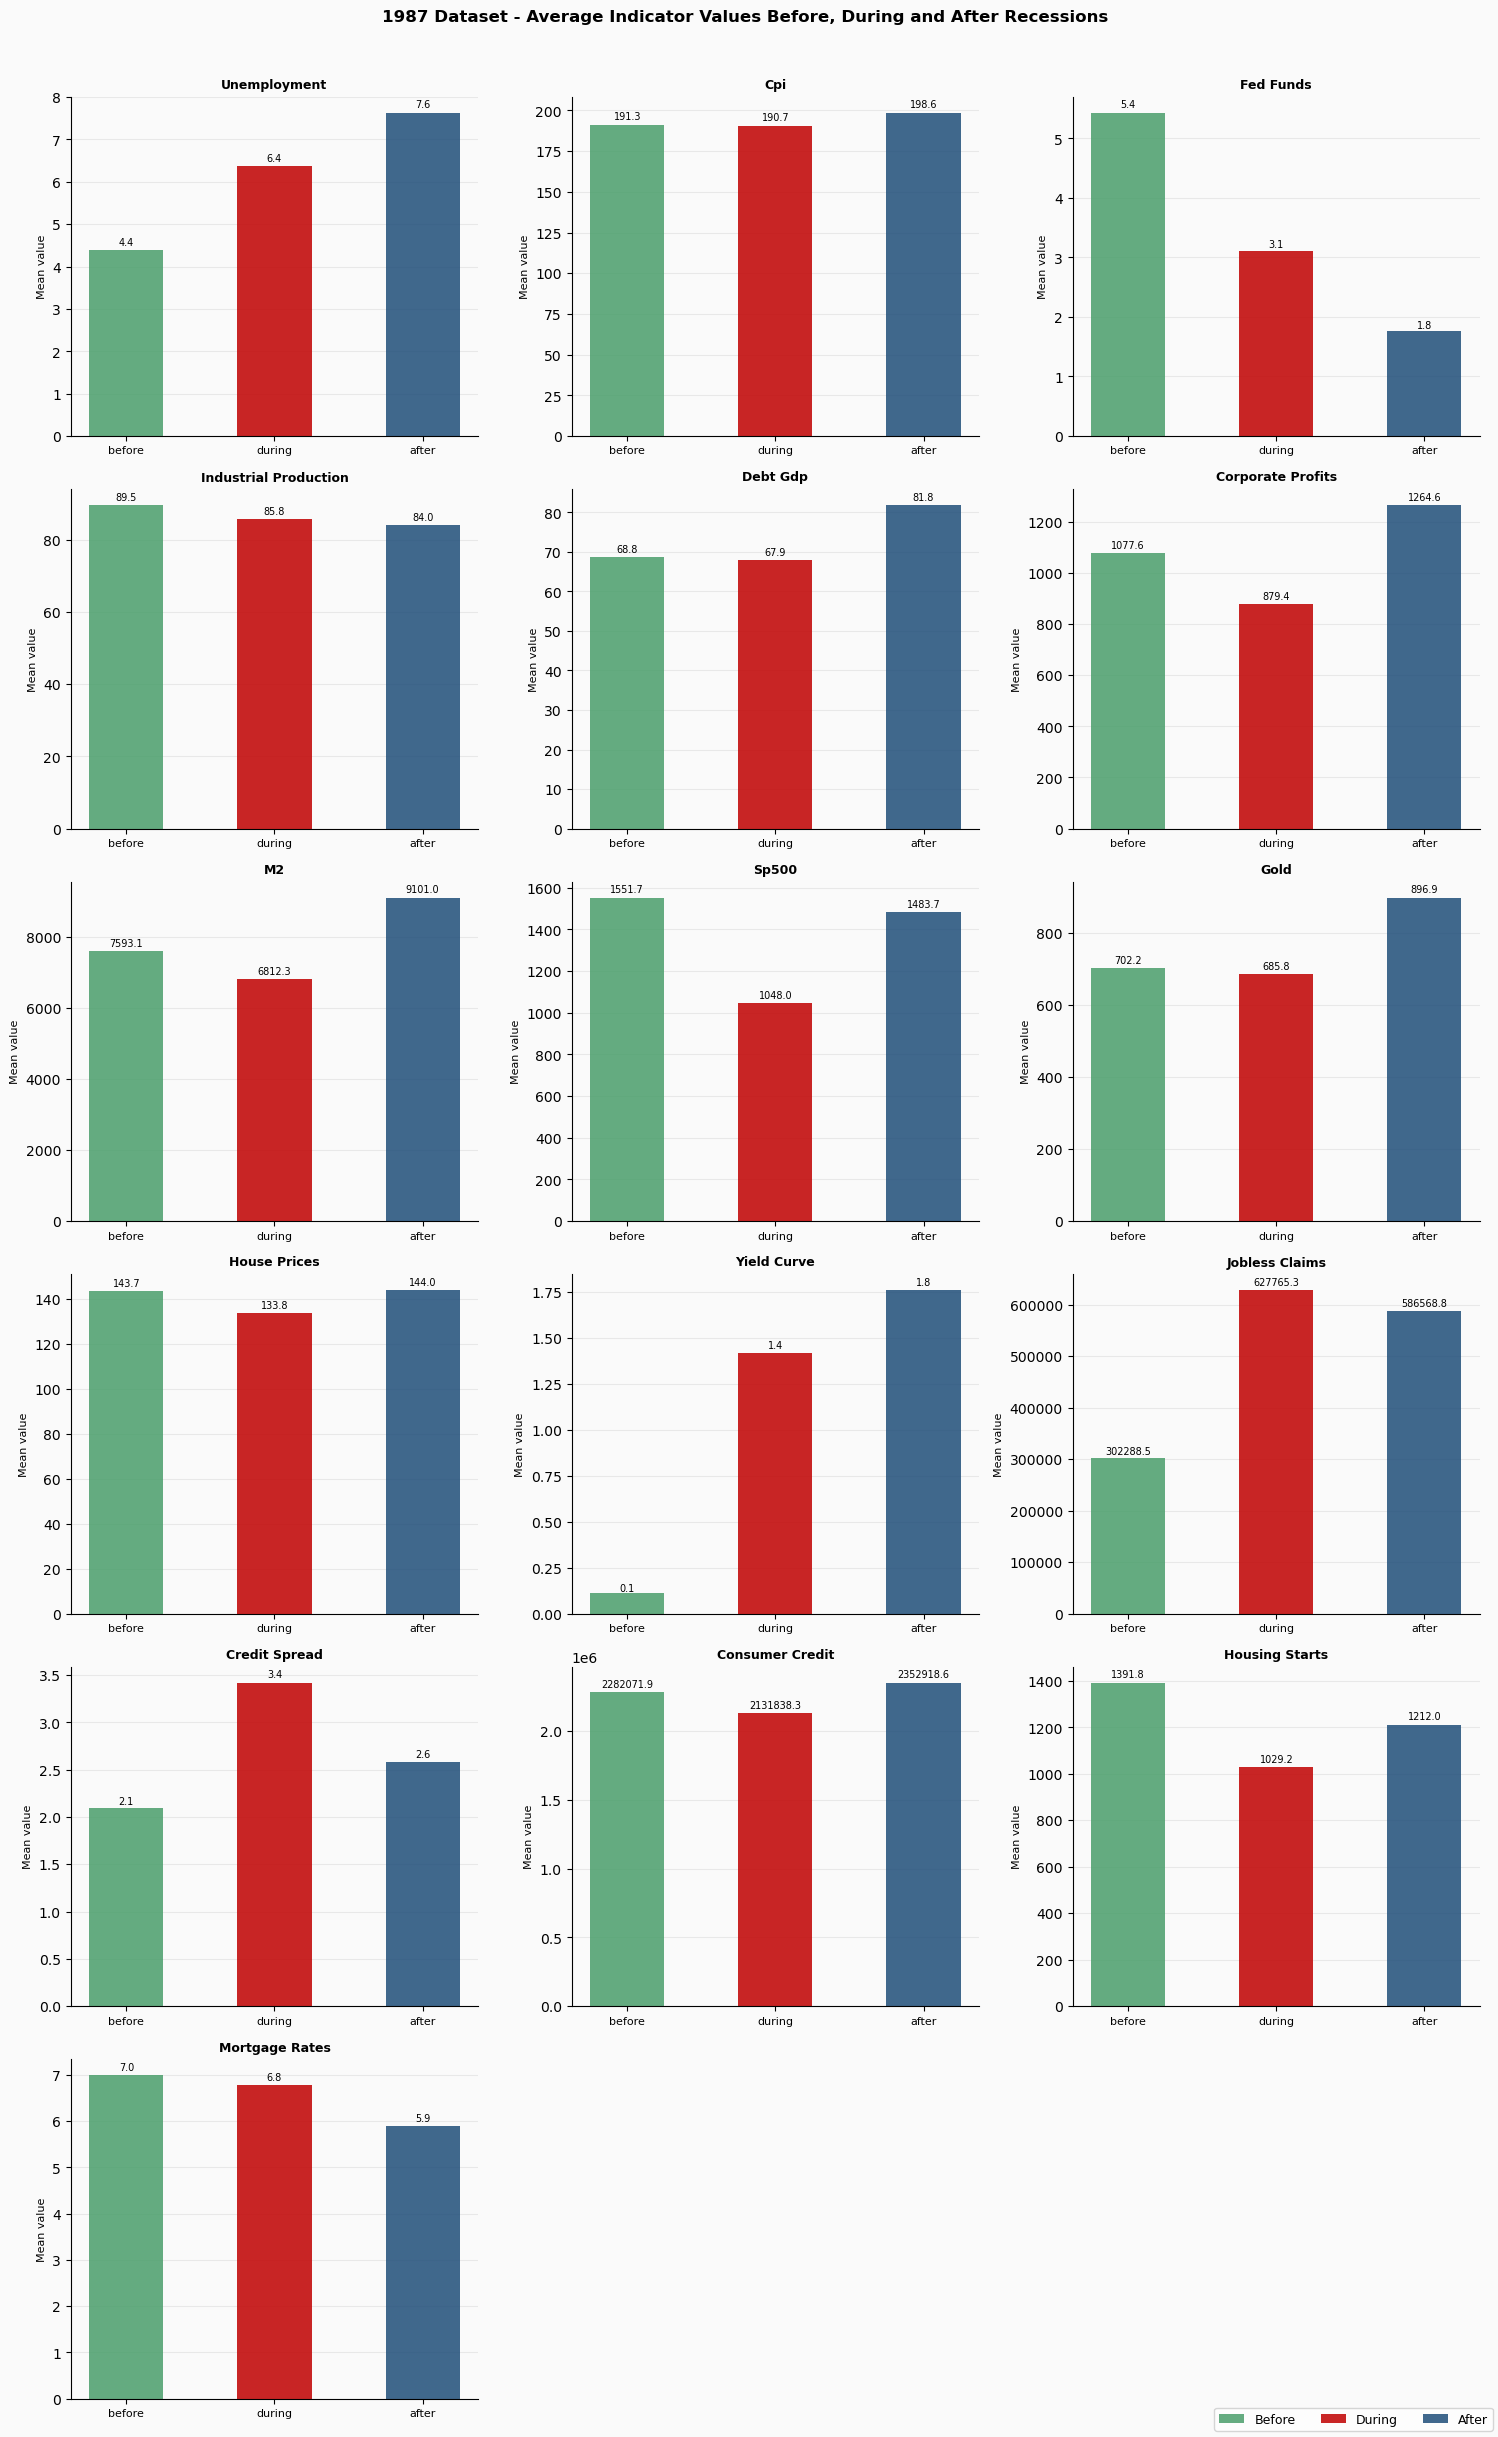

In [34]:
# Phase Bar Charts 

for df_phase, phase_summary, label in [
    (df_1960_phased, phase_summary_1960, "1960 Dataset"),
    (df_1987_phased, phase_summary_1987, "1987 Dataset"),
]:
    features = phase_summary.columns.tolist()
    n = len(features)
    ncols = 3
    nrows = (n + ncols - 1) // ncols

    fig, axes = plt.subplots(nrows, ncols,
                              figsize=(15, 4 * nrows))
    axes = axes.flatten()
    fig.patch.set_facecolor("#fafafa")

    colours = {"before": "#4a9e6b", "during": "#c00000", "after": "#1f4e79"}

    for i, feat in enumerate(features):
        ax = axes[i]
        ax.set_facecolor("#fafafa")
        vals = phase_summary[feat]
        bars = ax.bar(vals.index, vals.values,
                      color=[colours[p] for p in vals.index],
                      width=0.5, alpha=0.85)
        for bar, val in zip(bars, vals.values):
            ax.text(bar.get_x() + bar.get_width() / 2,
                    bar.get_height() * 1.01, f"{val:.1f}",
                    ha="center", va="bottom", fontsize=7)
        ax.set_title(feat.replace("_", " ").title(), fontsize=9,
                     fontweight="bold")
        ax.set_ylabel("Mean value", fontsize=8)
        ax.tick_params(axis="x", labelsize=8)
        ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
        ax.set_axisbelow(True)
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)

    for j in range(i + 1, len(axes)):
        axes[j].set_visible(False)

    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor="#4a9e6b", alpha=0.85, label="Before"),
        Patch(facecolor="#c00000", alpha=0.85, label="During"),
        Patch(facecolor="#1f4e79", alpha=0.85, label="After"),
    ]
    fig.legend(handles=legend_elements, loc="lower right",
               fontsize=9, ncol=3)
    fig.suptitle(f"{label} - Average Indicator Values Before, During and After Recessions",
                 fontsize=12, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

## Recession Lead/Lag Analysis

To inform the selection of lag windows in feature engineering, the Pearson correlation between each indicator and the recession indicator was calculated at lags ranging from -24 to +24 months. A negative lag indicates the indicator moves before the recession begins, making it a leading indicator. A positive lag indicates the indicator moves after the recession has started, making it a lagging indicator. A lag of zero indicates a coincident indicator that moves in line with the recession. Individual lead/lag plots are generated for all indicators in the notebook above. Given the limited number of recession episodes in both datasets, these correlations should be interpreted as indicative of general patterns rather than precise statistical estimates.

### 1960 Dataset

The lead/lag analysis reveals clear differentiation between leading, coincident and lagging indicators:

- **Unemployment** shows the strongest leading correlation in the 1960 dataset, peaking at lag -12 with a correlation of 0.444. This is counterintuitive given unemployment is commonly described as a lagging indicator, but reflects the fact that unemployment begins rising in the months before a recession is officially declared rather than strictly after it
- **Industrial Production and S&P 500** both peak at lag -11 with moderate negative correlations of -0.183 and -0.168 respectively, confirming they begin declining approximately eleven months before recession onset
- **Corporate Profits** peaks at lag 0, indicating it moves broadly in line with the recession cycle
- **CPI, M2 and Gold** all peak at lag +4, confirming their lagging nature - these series tend to respond to recessionary conditions rather than anticipate them
- **Federal Funds Rate** peaks at lag +9 with a correlation of 0.389, reflecting the well-documented pattern of monetary tightening preceding recessions by several months before rates are eventually cut

### 1987 Dataset

The richer indicator set in the 1987 dataset provides a more detailed picture of leading and lagging dynamics:

- **Yield Curve** is the strongest leading indicator, peaking at lag -22 with a correlation of 0.450. This confirms the well-documented finding that yield curve inversion precedes recessions by up to two years, making it one of the most valuable early warning signals available
- **Credit Spread** peaks at lag -1 with the highest correlation in the dataset at 0.490, making it the strongest near-term leading indicator - widening credit spreads signal increasing default risk in the month immediately before recession onset
- **Jobless Claims** also peaks at lag -1 with a correlation of 0.294, consistent with its role as one of the most timely labour market indicators
- **Housing Starts** peaks at lag -5 with a correlation of -0.277, confirming it leads recessions by approximately five months as construction activity slows ahead of broader economic downturns
- **Unemployment** peaks at lag -17, again appearing as a leading indicator for the same reasons discussed above
- **Debt/GDP, Federal Funds Rate, Mortgage Rates, CPI, M2, Gold and Consumer Credit** all peak at positive lags, confirming their lagging nature

### Implications for Feature Engineering

These findings directly inform the lag window selection in the feature engineering step. The strongest leading indicators - yield curve and credit spread leading by one to two months, housing starts by five months, and industrial production and S&P 500 by approximately eleven months - suggest that lag features at 3, 6 and 12 months will capture the most economically meaningful predictive signals. The long leading time of the yield curve at 22 months also justifies including a 24-month lag feature for that specific indicator. Coincident and lagging indicators such as CPI, M2 and consumer credit are better represented through their percentage change features rather than raw levels or lagged values.

In [35]:
# Recession Lead/Lag Analysis

# for each indicator calculate correlation with recession
# at lags from -12 (indicator leads recession by 12 months)
# to +12 (indicator lags recession by 12 months)

def lead_lag_analysis(df, features, max_lag=24):
    results = {}
    for feat in features:
        correlations = {}
        for lag in range(-max_lag, max_lag + 1):
            shifted = df[feat].shift(lag)
            corr = shifted.corr(df["recession"])
            correlations[lag] = corr
        results[feat] = correlations
    return pd.DataFrame(results)

features_1960_ll = [c for c in df_1960.columns if c != "recession"]
features_1987_ll = [c for c in df_1987.columns if c != "recession"]

ll_1960 = lead_lag_analysis(df_1960, features_1960_ll)
ll_1987 = lead_lag_analysis(df_1987, features_1987_ll)

print("Lead/Lag analysis complete")
print("Negative lag = indicator leads recession")
print("Positive lag = indicator lags recession")

Lead/Lag analysis complete
Negative lag = indicator leads recession
Positive lag = indicator lags recession


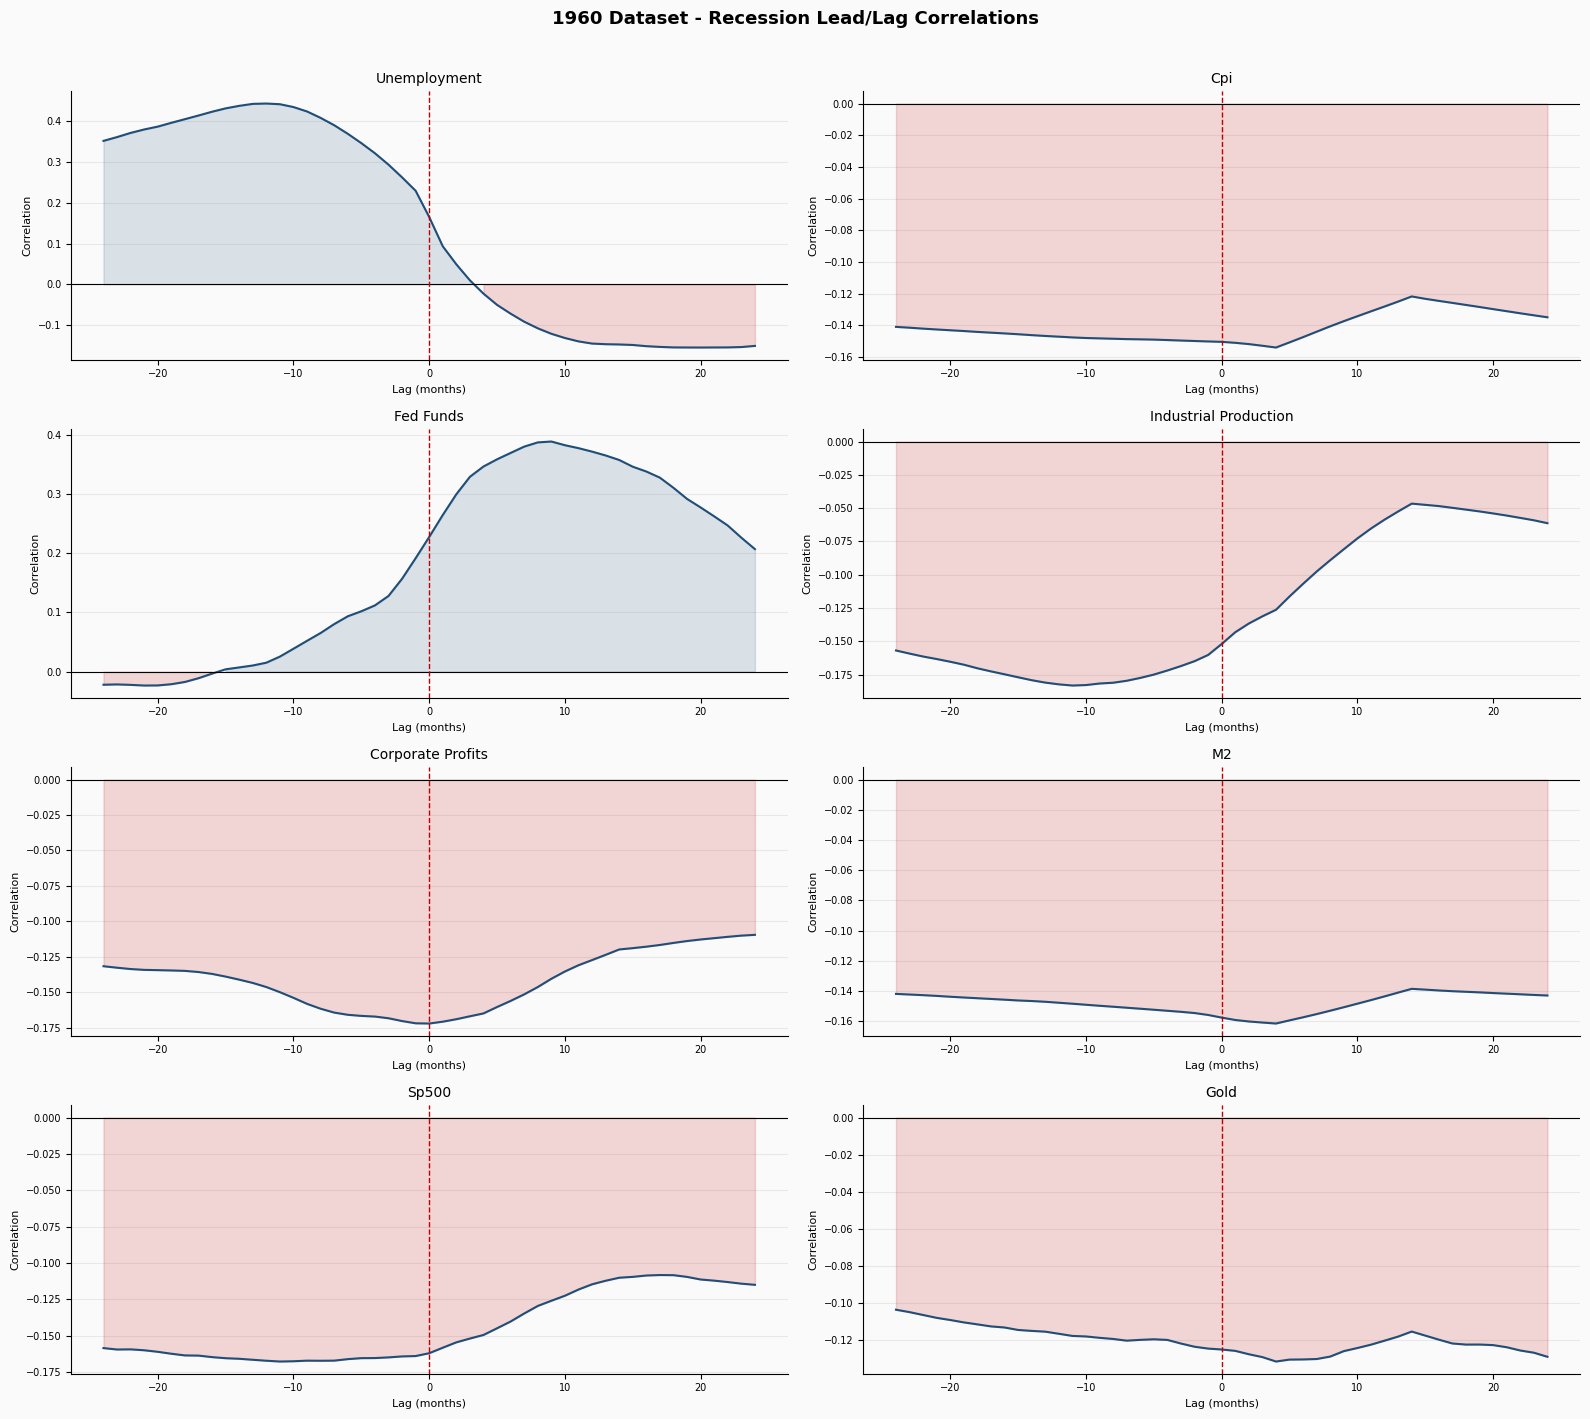

In [36]:
# Lead/Lag Plot - 1960 Dataset 

n = len(features_1960_ll)
ncols = 2
nrows = (n + 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.5 * nrows))
axes = axes.flatten()
fig.patch.set_facecolor("#fafafa")

for i, feat in enumerate(features_1960_ll):
    ax = axes[i]
    ax.set_facecolor("#fafafa")
    ax.plot(ll_1960.index, ll_1960[feat], color="#1f4e79", linewidth=1.5)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="-")
    ax.axvline(0, color="#c00000", linewidth=1.0, linestyle="--", label="Recession start")
    ax.fill_between(ll_1960.index, ll_1960[feat], 0,
                    where=(ll_1960[feat] > 0), alpha=0.15, color="#1f4e79")
    ax.fill_between(ll_1960.index, ll_1960[feat], 0,
                    where=(ll_1960[feat] < 0), alpha=0.15, color="#c00000")
    ax.set_title(feat.replace("_", " ").title(), fontsize=10)
    ax.set_xlabel("Lag (months)", fontsize=8)
    ax.set_ylabel("Correlation", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

# hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("1960 Dataset - Recession Lead/Lag Correlations", fontsize=13,
             fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

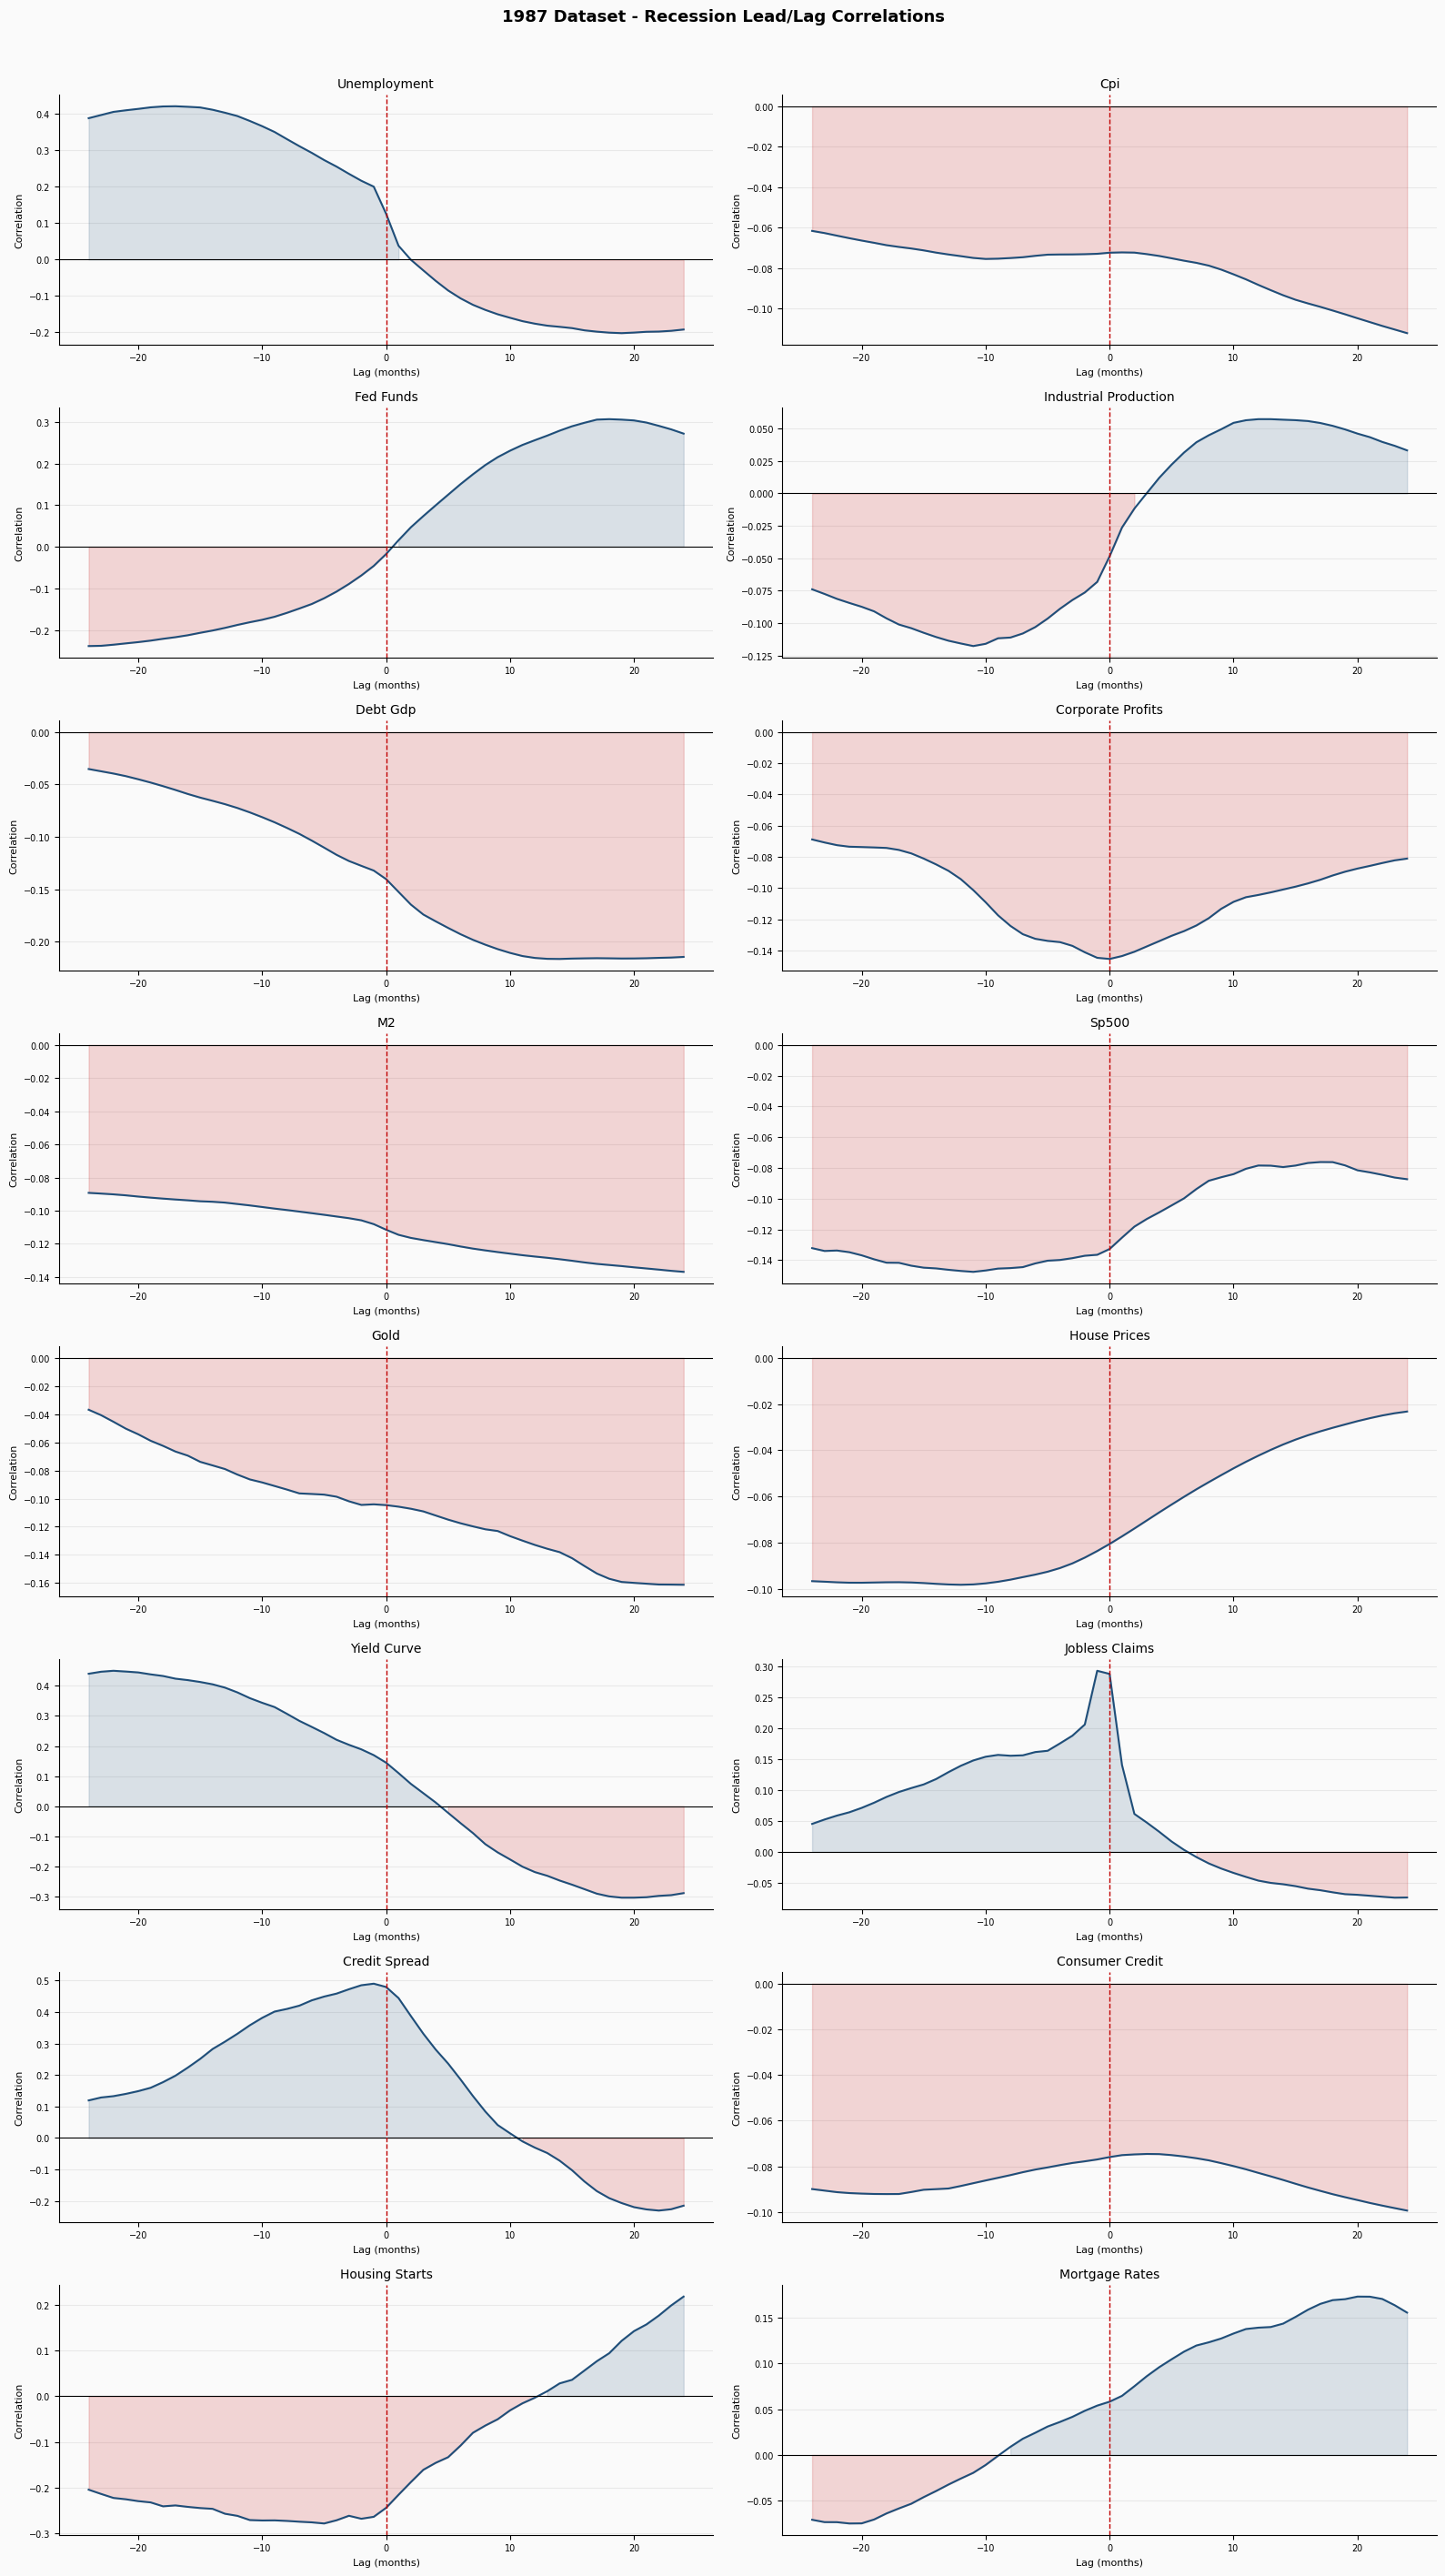

In [37]:
# Lead/Lag Plot - 1987 Dataset 

n = len(features_1987_ll)
ncols = 2
nrows = (n + 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.5 * nrows))
axes = axes.flatten()
fig.patch.set_facecolor("#fafafa")

for i, feat in enumerate(features_1987_ll):
    ax = axes[i]
    ax.set_facecolor("#fafafa")
    ax.plot(ll_1987.index, ll_1987[feat], color="#1f4e79", linewidth=1.5)
    ax.axhline(0, color="black", linewidth=0.8, linestyle="-")
    ax.axvline(0, color="#c00000", linewidth=1.0, linestyle="--", label="Recession start")
    ax.fill_between(ll_1987.index, ll_1987[feat], 0,
                    where=(ll_1987[feat] > 0), alpha=0.15, color="#1f4e79")
    ax.fill_between(ll_1987.index, ll_1987[feat], 0,
                    where=(ll_1987[feat] < 0), alpha=0.15, color="#c00000")
    ax.set_title(feat.replace("_", " ").title(), fontsize=10)
    ax.set_xlabel("Lag (months)", fontsize=8)
    ax.set_ylabel("Correlation", fontsize=8)
    ax.tick_params(labelsize=7)
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle("1987 Dataset - Recession Lead/Lag Correlations", fontsize=13,
             fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

In [38]:
# Peak Correlation Summary
# for each indicator find the lag at which correlation is strongest
# negative lag = leading indicator, positive lag = lagging indicator

def peak_correlation_summary(ll_df, label):
    rows = []
    for feat in ll_df.columns:
        series = ll_df[feat].dropna()
        peak_lag = series.abs().idxmax()
        peak_corr = series[peak_lag]
        direction = "Leading" if peak_lag < 0 else "Lagging" if peak_lag > 0 else "Coincident"
        rows.append({
            "Indicator": feat,
            "Peak Lag (months)": peak_lag,
            "Peak Correlation": round(peak_corr, 3),
            "Direction": direction
        })
    df_out = pd.DataFrame(rows).set_index("Indicator")
    print(f"\n{label}")
    display(df_out.sort_values("Peak Lag (months)"))

peak_correlation_summary(ll_1960, "1960 Dataset - Peak Correlations")
peak_correlation_summary(ll_1987, "1987 Dataset - Peak Correlations")


1960 Dataset - Peak Correlations


,Peak Lag (months),Peak Correlation,Direction
Indicator,,,
unemployment,-12,0.444,Leading
industrial_production,-11,-0.183,Leading
sp500,-11,-0.168,Leading
corporate_profits,0,-0.172,Coincident
cpi,4,-0.154,Lagging
m2,4,-0.161,Lagging
gold,4,-0.132,Lagging
fed_funds,9,0.389,Lagging



1987 Dataset - Peak Correlations


,Peak Lag (months),Peak Correlation,Direction
Indicator,,,
yield_curve,-22,0.450,Leading
unemployment,-17,0.421,Leading
house_prices,-12,-0.098,Leading
industrial_production,-11,-0.118,Leading
sp500,-11,-0.148,Leading
housing_starts,-5,-0.278,Leading
jobless_claims,-1,0.294,Leading
credit_spread,-1,0.490,Leading
corporate_profits,0,-0.145,Coincident


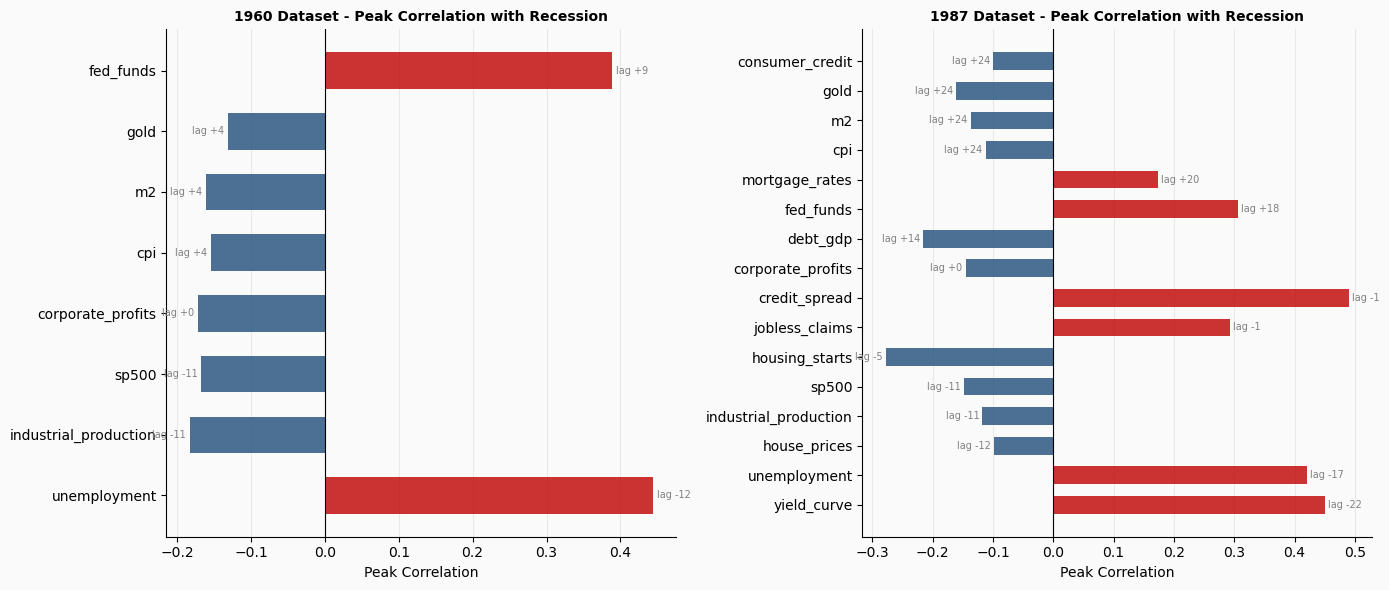

In [39]:
# Peak Correlation Heatmap 

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor("#fafafa")

for ax, ll_df, label in [
    (axes[0], ll_1960, "1960 Dataset"),
    (axes[1], ll_1987, "1987 Dataset"),
]:
    ax.set_facecolor("#fafafa")

    peak_data = pd.DataFrame({
        feat: {
            "Peak Lag": ll_df[feat].abs().idxmax(),
            "Peak Correlation": ll_df[feat][ll_df[feat].abs().idxmax()]
        }
        for feat in ll_df.columns
    }).T.sort_values("Peak Lag")

    colours = ["#c00000" if v > 0 else "#1f4e79"
               for v in peak_data["Peak Correlation"]]

    bars = ax.barh(peak_data.index,
                   peak_data["Peak Correlation"],
                   color=colours, alpha=0.8, height=0.6)

    ax.axvline(0, color="black", linewidth=0.8)

    for bar, lag in zip(bars, peak_data["Peak Lag"]):
        x = bar.get_width()
        ax.text(x + 0.005 if x >= 0 else x - 0.005,
                bar.get_y() + bar.get_height() / 2,
                f"lag {int(lag):+d}",
                ha="left" if x >= 0 else "right",
                va="center", fontsize=7, color="grey")

    ax.set_title(f"{label} - Peak Correlation with Recession",
                 fontsize=10, fontweight="bold")
    ax.set_xlabel("Peak Correlation")
    ax.xaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

## Distribution Analysis

Distribution plots were generated for all indicators across both datasets. Each indicator is shown with three plots: a histogram with KDE curve showing the overall shape of the distribution, a Q-Q plot comparing the distribution against a theoretical normal distribution, and a boxplot split by recession and non-recession periods to show how the indicator behaves differently across the two states.

### 1960 Dataset

**Unemployment** shows a right-skewed distribution with most values clustered between 4% and 7%, reflecting the concentration of observations during non-recessionary expansionary periods. The Q-Q plot shows moderate deviation from normality in the upper tail, driven by the extreme unemployment spikes during severe recessions. The boxplot confirms a noticeably higher median and wider spread during recession periods, with several outliers above 10%.

**CPI** shows a broadly uniform distribution across its range, consistent with the long-run upward trend in prices over sixty years producing observations spread fairly evenly across all value ranges. The Q-Q plot shows clear non-normality with an S-shaped curve, reflecting the non-stationary nature of the series confirmed by the ADF test. The boxplot shows lower median CPI values during recessions, which is counterintuitive but reflects the fact that most historical recessions occurred in earlier decades when CPI levels were lower.

**Federal Funds Rate** shows a bimodal distribution with peaks around 2-3% and 5%, reflecting the distinct monetary policy regimes of the pre and post-GFC eras. The Q-Q plot shows good linearity in the middle range with deviation in the upper tail driven by the extreme rates of the early 1980s. The boxplot shows a notably higher median and wider spread during recessions, consistent with the pattern of elevated rates preceding downturns.

**Industrial Production** shows a broadly uniform distribution reflecting its long-run upward trend, with clear non-normality in the Q-Q plot. The boxplot shows lower values and a wider spread during recession periods, with the range extending down to the low values of the 1960s when production was structurally lower.

**Corporate Profits** shows strong right skew with the majority of observations clustered at low values and a long tail reflecting the exponential growth in profits over sixty years. The Q-Q plot confirms severe non-normality. The boxplot shows substantially lower median profits during recessions, with the recession distribution tightly clustered at lower values.

**M2** and **S&P 500** show similar strongly right-skewed distributions driven by long-run exponential growth, with Q-Q plots showing clear non-normality. Both show lower median values during recessions in their boxplots, though the recession distributions remain wide given the range of absolute values across different time periods.

**Gold** shows a right-skewed distribution with most observations below 1,000, reflecting the concentration of lower gold prices in the earlier decades of the sample. The Q-Q plot shows deviation in both tails. The boxplot shows lower median gold prices during recessions, again reflecting the time period effect rather than a direct recession relationship.

### 1987 Dataset

**Unemployment** in the 1987 dataset shows a similar right-skewed distribution to the 1960 dataset but with a higher peak around 5-6% reflecting the more recent sample. The boxplot shows a slightly higher median during recessions with a wider spread, and a notable outlier above 14% from the COVID-19 period.

**CPI** in the 1987 dataset shows a more uniform distribution compared to the 1960 dataset, reflecting the narrower range of inflation values in the modern era. The boxplots show very similar distributions between recession and non-recession periods, consistent with the weak correlation found in the heatmap.

**Federal Funds Rate** shows a strongly left-skewed distribution in the 1987 dataset with most values concentrated near zero, reflecting the prolonged period of near-zero rates following the GFC. The Q-Q plot shows significant deviation from normality. The boxplot shows slightly lower median rates during recessions, reflecting the speed of rate cuts during downturns.

**Industrial Production** shows a left-skewed distribution in the 1987 dataset, concentrated at higher values reflecting the more recent sample period. The boxplot shows a noticeably lower distribution during recessions with the COVID-19 outlier clearly visible at around 60.

**Debt/GDP** shows a bimodal distribution with peaks around 60% and 100-120%, reflecting the structural step-up in government debt following the GFC and COVID-19. The Q-Q plot shows clear non-normality with a stepped pattern. The boxplot shows lower debt/GDP during recessions, reflecting the time period effect as recessions occurred when debt levels were structurally lower.

**Corporate Profits** in the 1987 dataset shows a more normal distribution than in the 1960 dataset given the shorter and more recent sample period, though still with right skew. The boxplot clearly shows lower median profits during recessions.

**Yield Curve** shows a broadly uniform distribution ranging from below -1 to nearly 3, reflecting the full range of yield curve environments from deeply inverted to steeply upward sloping. The Q-Q plot shows reasonable linearity. The boxplot shows a notably higher median yield curve during recessions, consistent with the steepening that occurs as short-term rates are cut aggressively during downturns.

**Jobless Claims** shows extreme right skew with the vast majority of observations clustered near zero on the scale of the plot, driven by the unprecedented COVID-19 spike to over 4 million claims. The Q-Q plot shows severe deviation from normality with the COVID-19 outlier clearly visible as an extreme point in the upper right. The boxplot shows that despite the COVID-19 outlier, the median during recessions is only modestly higher than non-recession periods, with the outlier appearing as a single point well above the whiskers. This extreme observation may influence model training and is noted as a potential source of bias toward COVID-19 type recession patterns.

**Credit Spread** shows right skew with most values below 3% and a tail extending to 6% during the GFC. The boxplot shows a clear and meaningful difference between recession and non-recession periods, with the median credit spread during recessions approximately 1.5 times the non-recession median - one of the clearest visual separations between the two states across all indicators in the 1987 dataset.

**Housing Starts** shows an approximately normal distribution centred around 1,250-1,500 units. The Q-Q plot shows good linearity. The boxplot shows a clearly lower distribution during recessions with a lower median and tighter range, consistent with the sharp slowdown in construction activity during downturns.

**House Prices** show a right-skewed distribution reflecting the long-run upward trend in property values. The boxplot shows similar median values between recession and non-recession periods, though with a wider spread during recessions reflecting the varied behaviour of house prices across different downturns - rising through the Dot-Com recession but falling sharply during the GFC.

**Consumer Credit** shows a broadly uniform distribution reflecting its long-run upward trend, with clear non-normality in the Q-Q plot. The boxplot shows lower median consumer credit during recessions, reflecting the time period effect.

**Mortgage Rates** shows a bimodal distribution with peaks around 4% and 7%, reflecting the structural decline in rates over the post-1987 period. The Q-Q plot shows reasonable linearity. The boxplot shows similar distributions during recession and non-recession periods, consistent with the weak correlation found in the heatmap.

### Key Findings

The distribution analysis confirms several patterns identified in earlier sections. The majority of indicators show clear non-normality, consistent with the stationarity testing results, reinforcing the case for percentage change features over raw levels. The boxplots reveal that credit spread, unemployment, housing starts and jobless claims show the clearest visual separation between recession and non-recession distributions, suggesting these indicators carry the most direct discriminative information. For many trending indicators such as CPI, M2, S&P 500 and consumer credit, the boxplot differences reflect time period effects rather than recession dynamics, further supporting the use of momentum and rate of change features in the modelling phase.

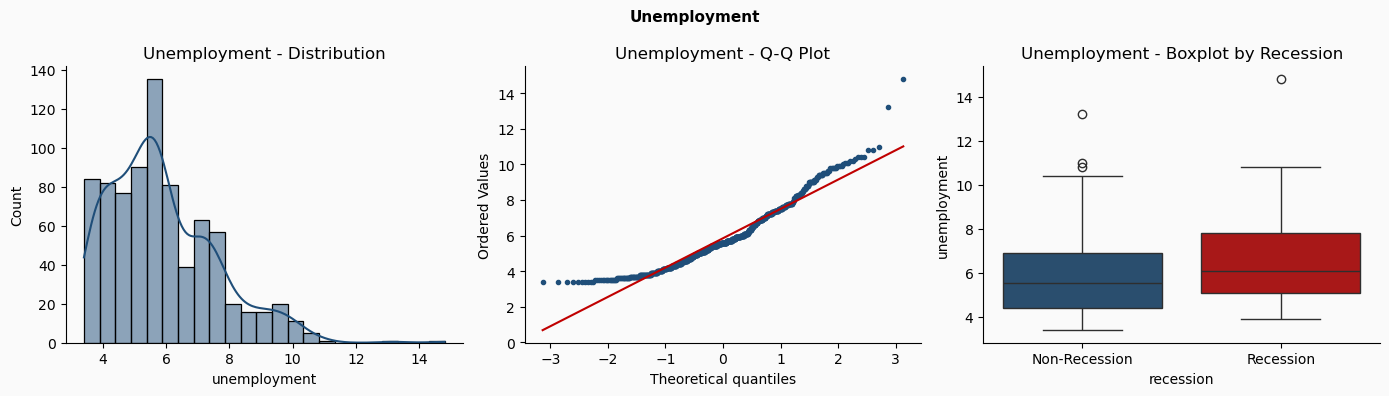

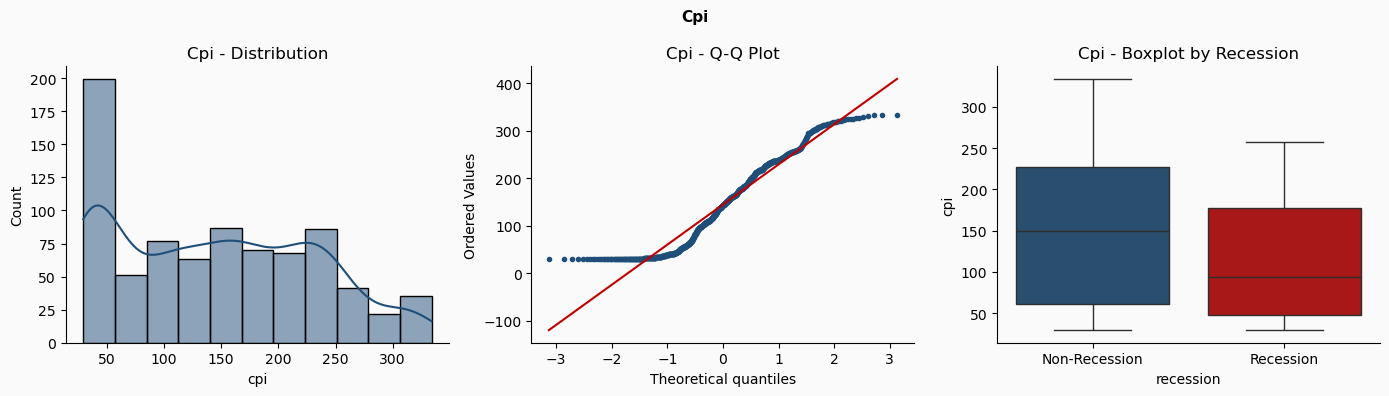

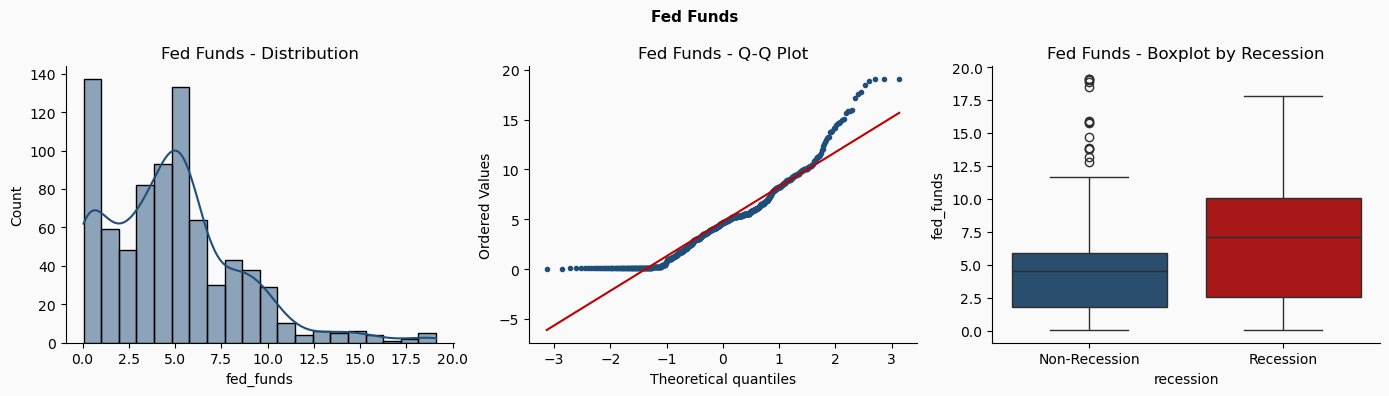

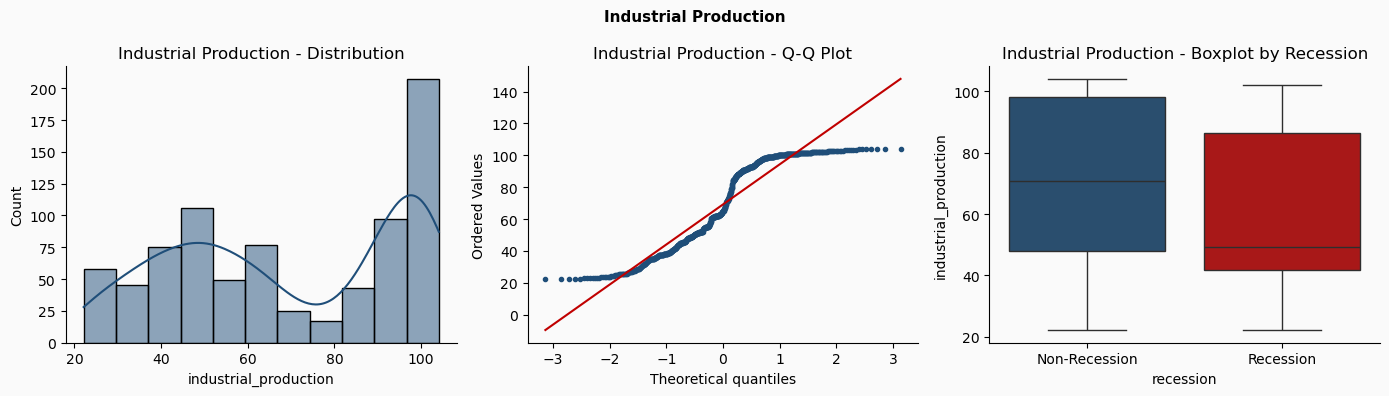

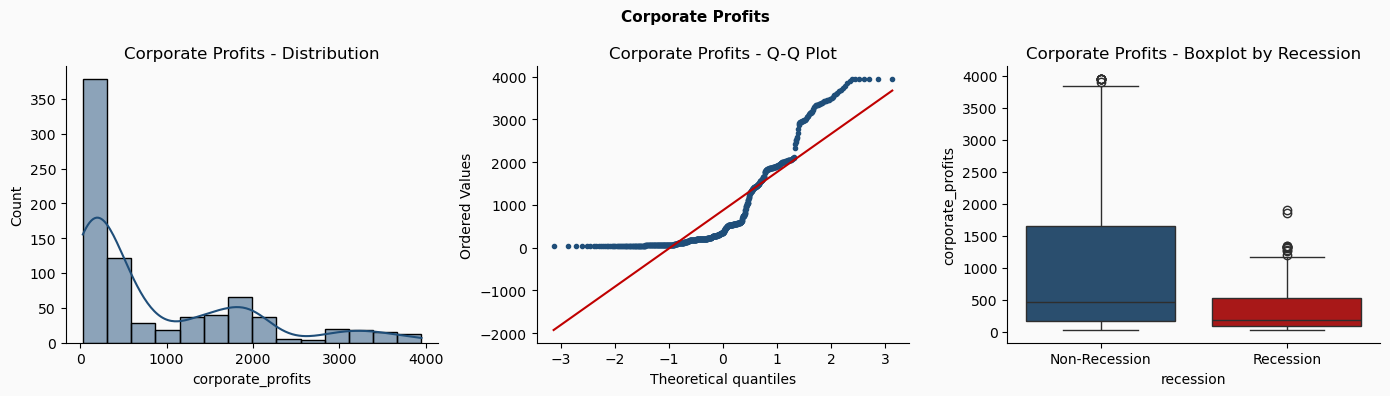

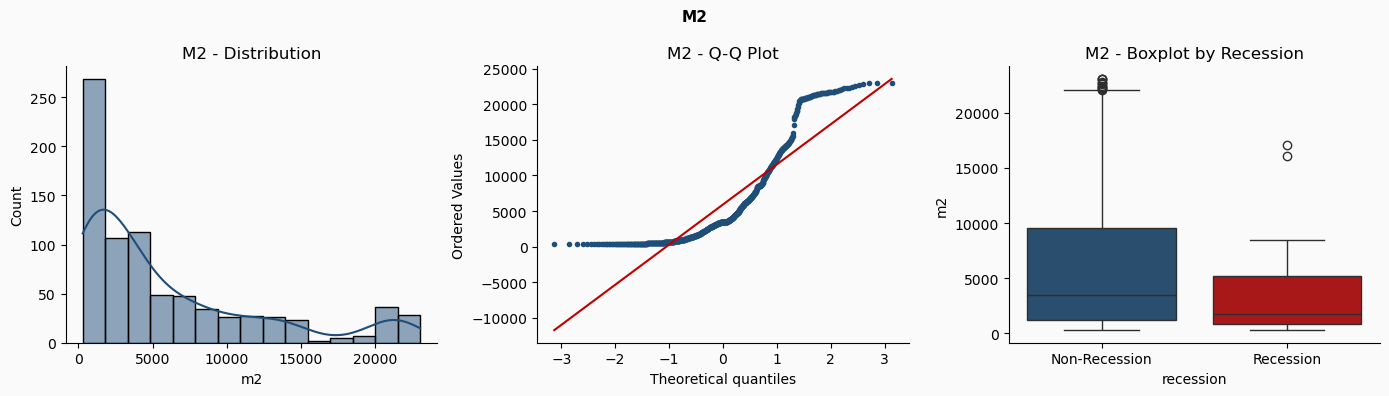

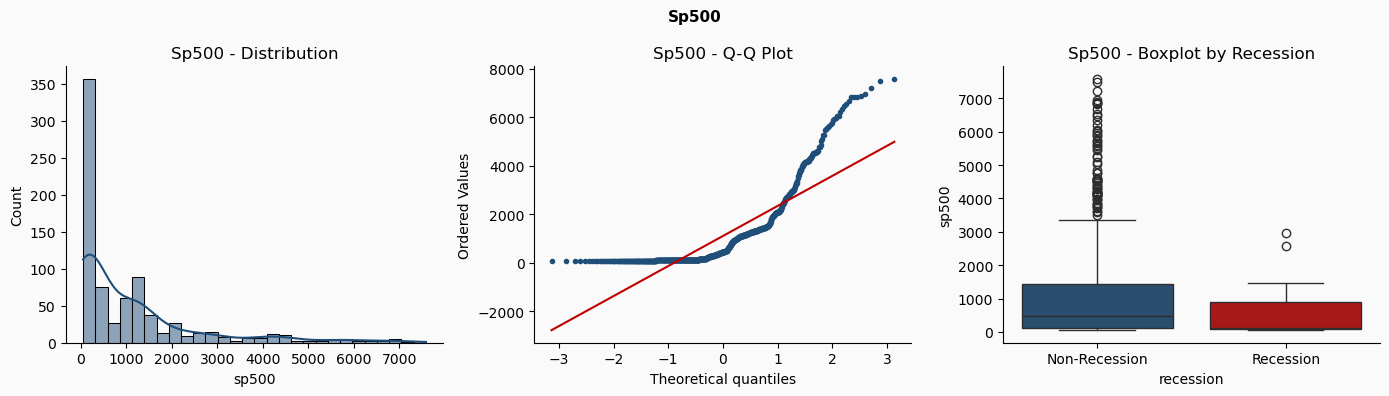

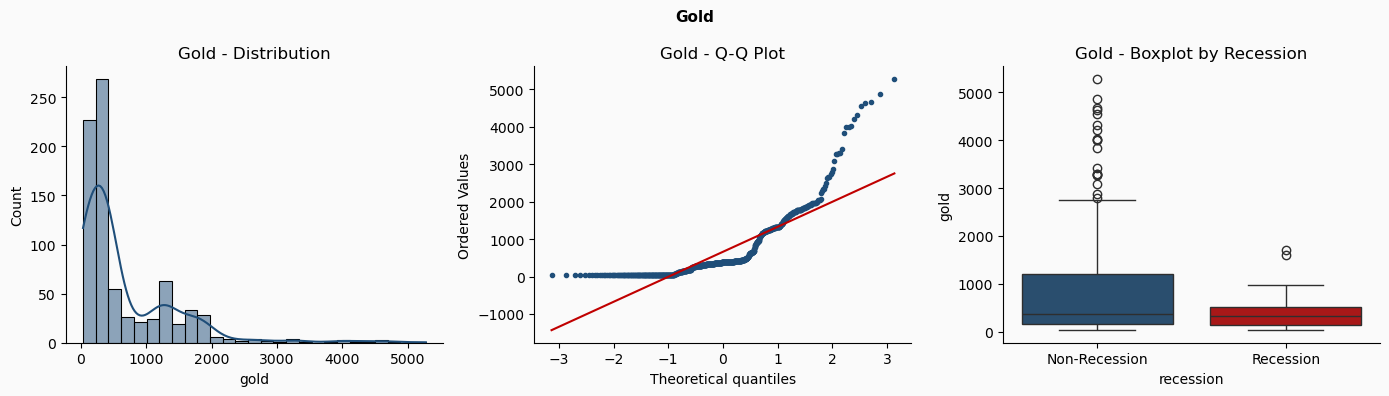

In [40]:
# Distribution Plots - 1960 Dataset 

from scipy import stats

features_1960_dist = [c for c in df_1960.columns if c != "recession"]

for feat in features_1960_dist:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    fig.patch.set_facecolor("#fafafa")

    for ax in axes:
        ax.set_facecolor("#fafafa")
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)

    sns.histplot(df_1960[feat], kde=True, ax=axes[0], color="#1f4e79")
    axes[0].set_title(f"{feat.replace('_', ' ').title()} - Distribution")

    stats.probplot(df_1960[feat], dist="norm", plot=axes[1])
    axes[1].get_lines()[0].set(color="#1f4e79", markersize=3)
    axes[1].get_lines()[1].set(color="#c00000")
    axes[1].set_title(f"{feat.replace('_', ' ').title()} - Q-Q Plot")

    sns.boxplot(data=df_1960, x="recession", y=feat, ax=axes[2],
            hue="recession", palette={0.0: "#1f4e79", 1.0: "#c00000"},
            legend=False)
    axes[2].set_xticklabels(["Non-Recession", "Recession"])
    axes[2].set_title(f"{feat.replace('_', ' ').title()} - Boxplot by Recession")

    plt.suptitle(feat.replace("_", " ").title(), fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

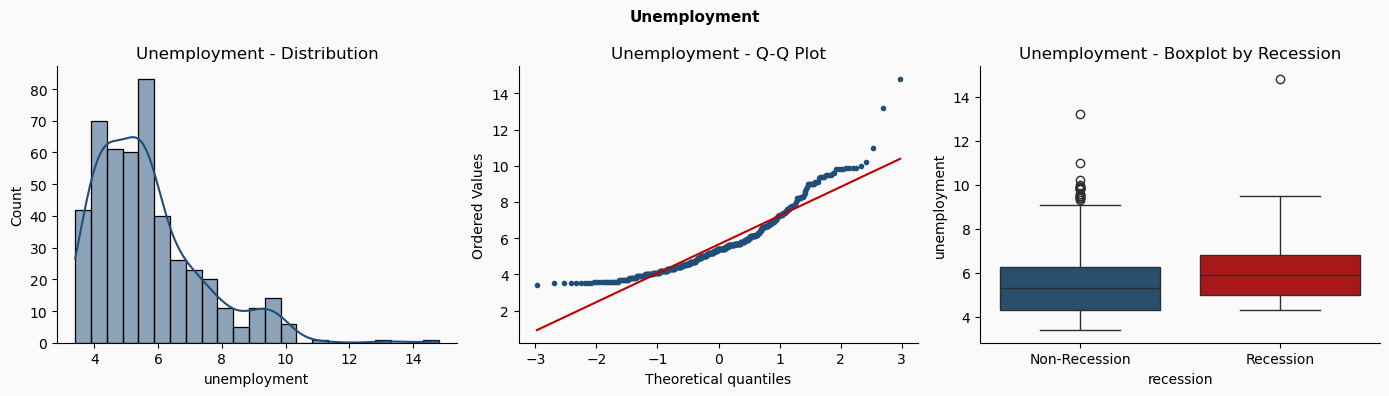

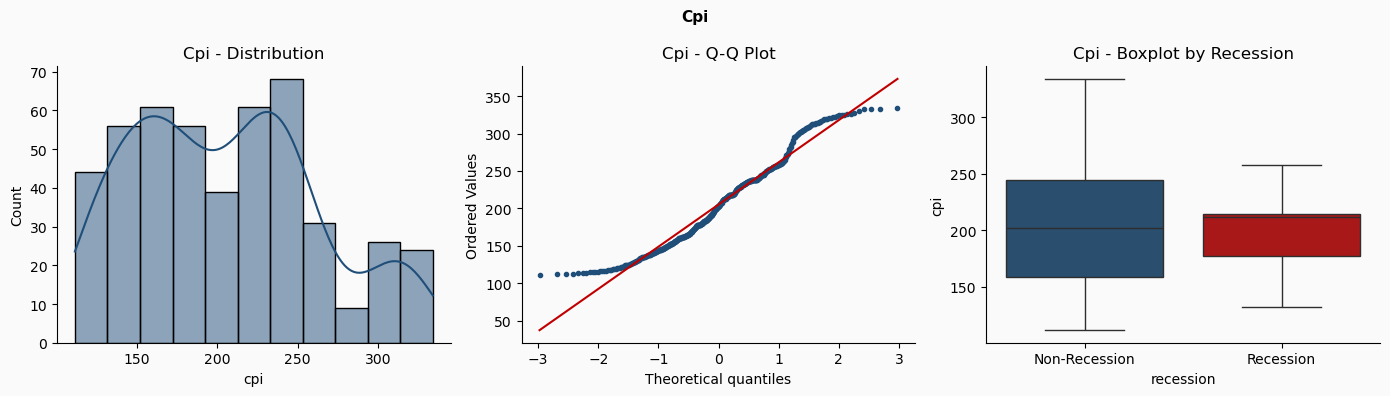

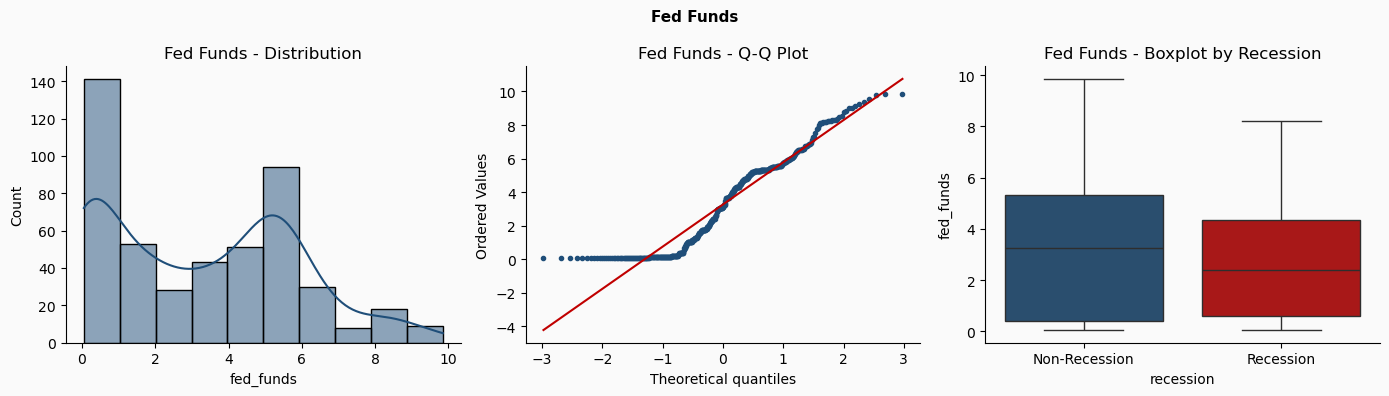

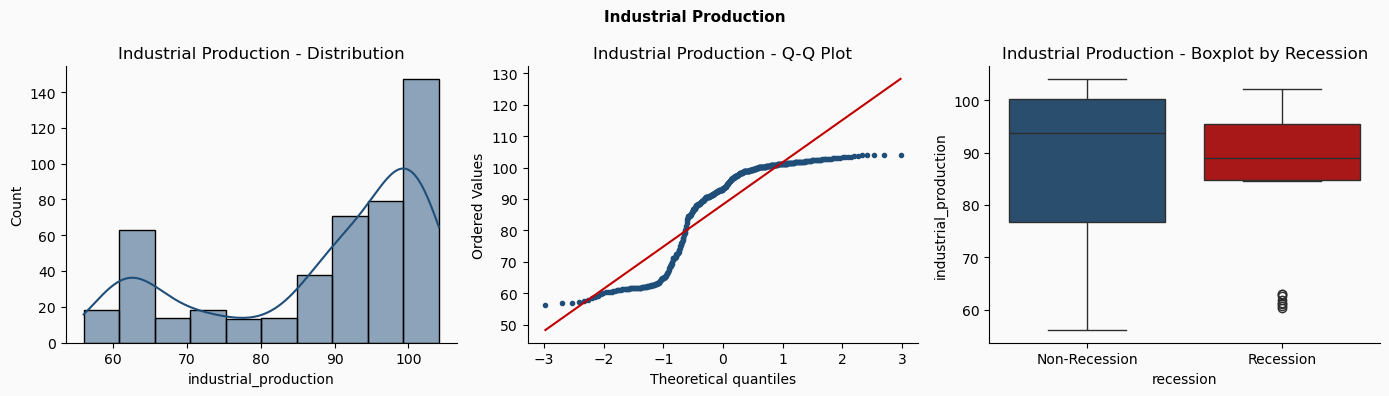

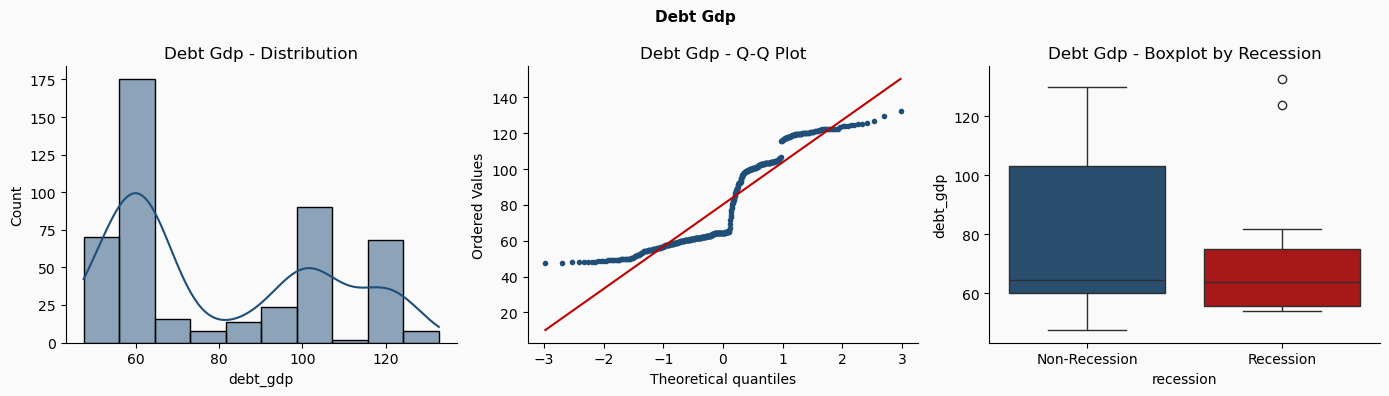

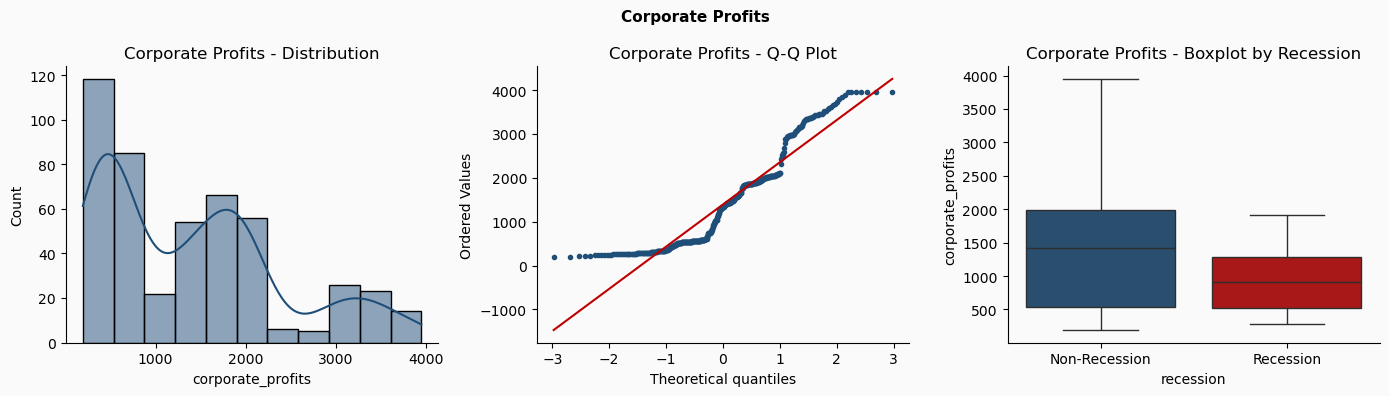

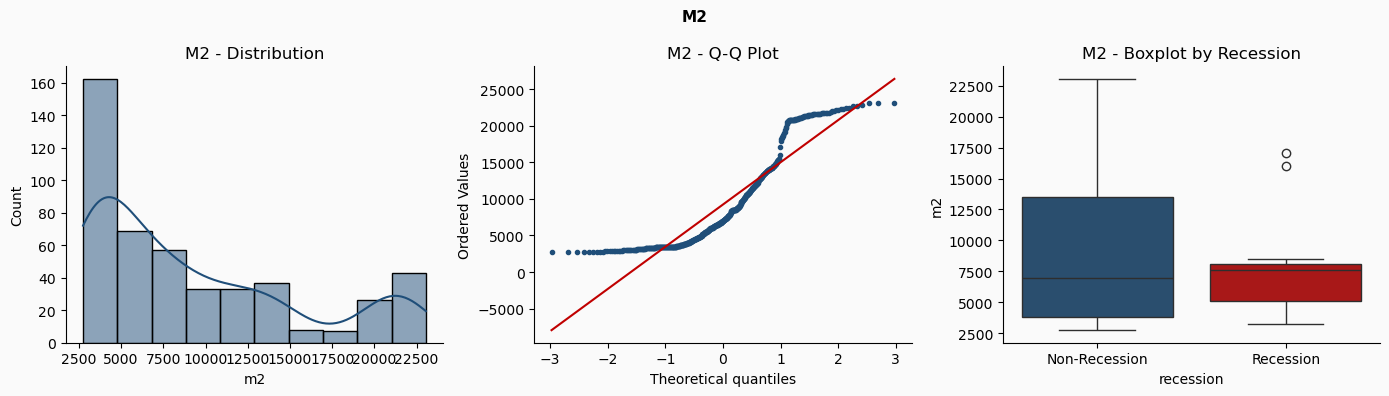

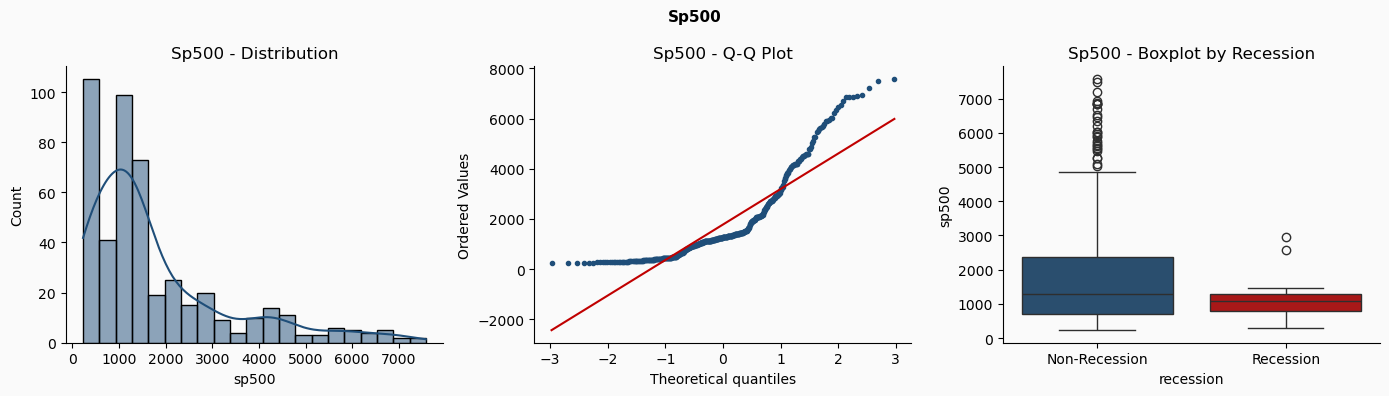

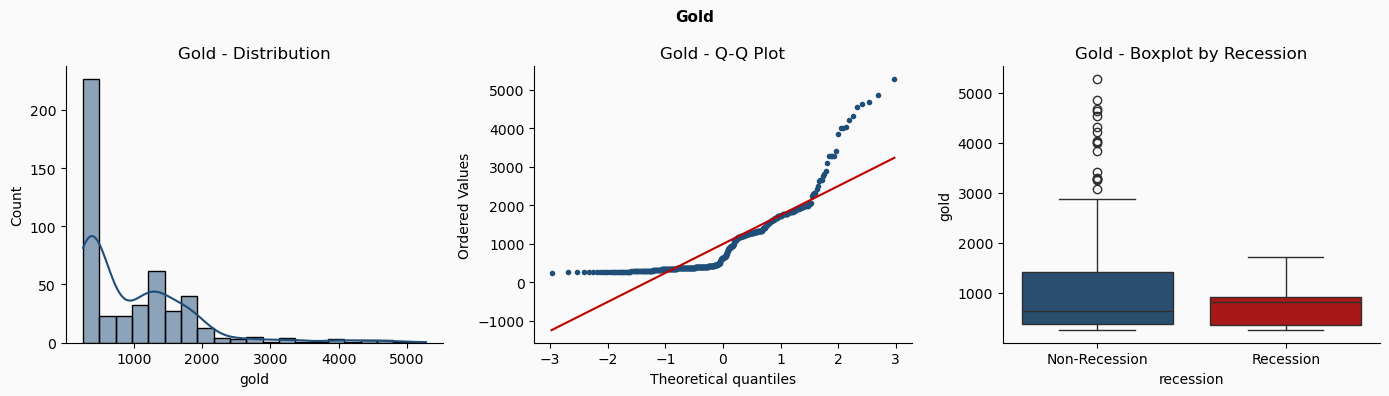

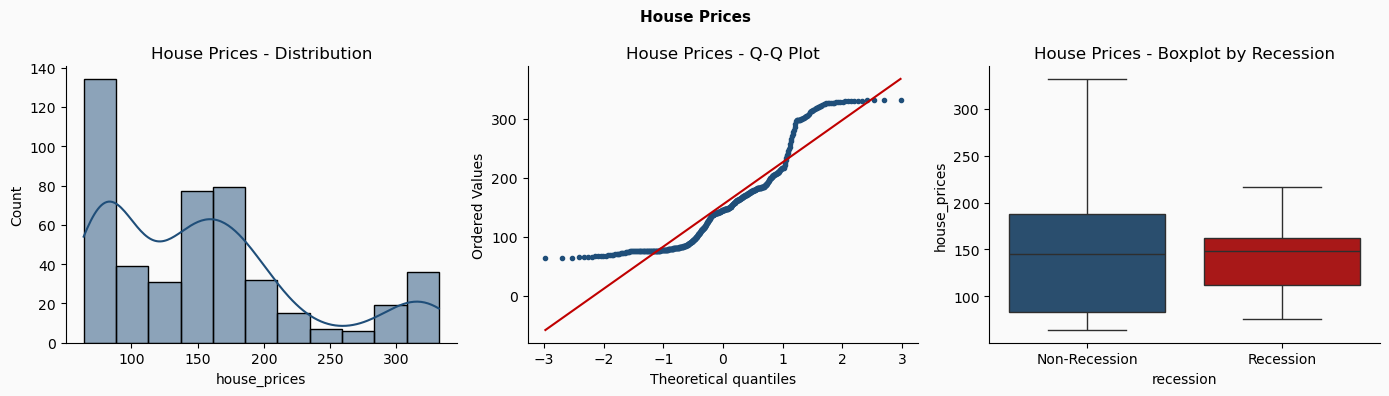

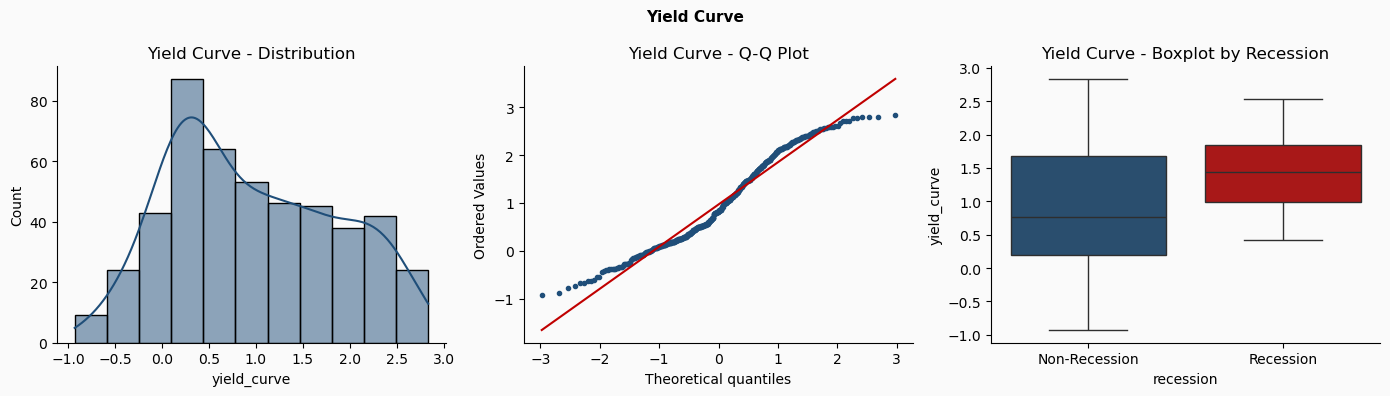

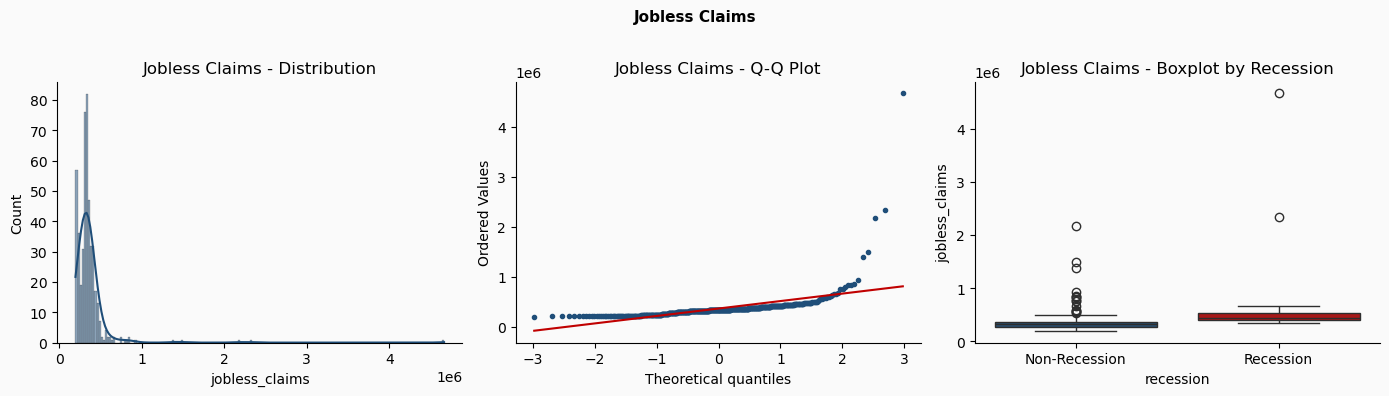

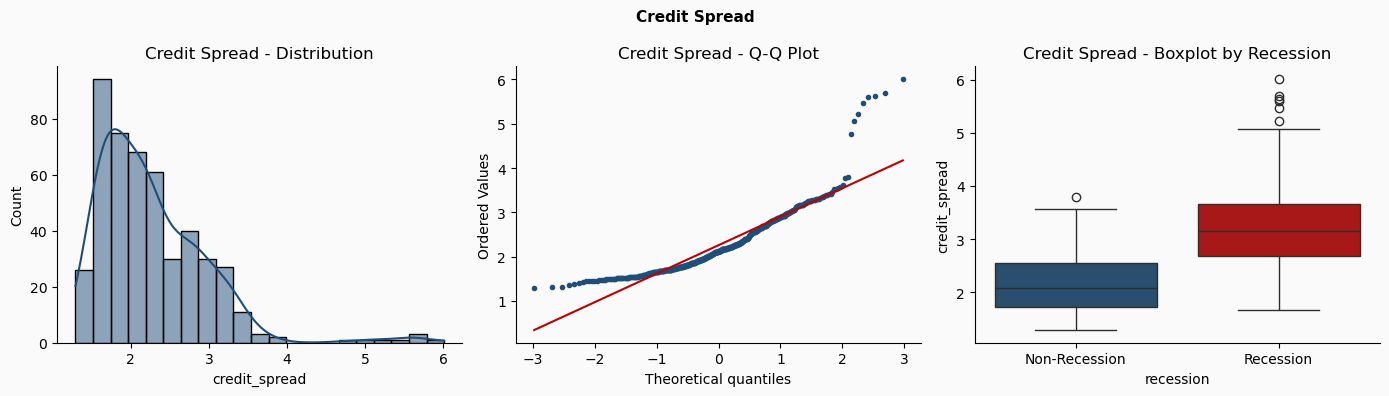

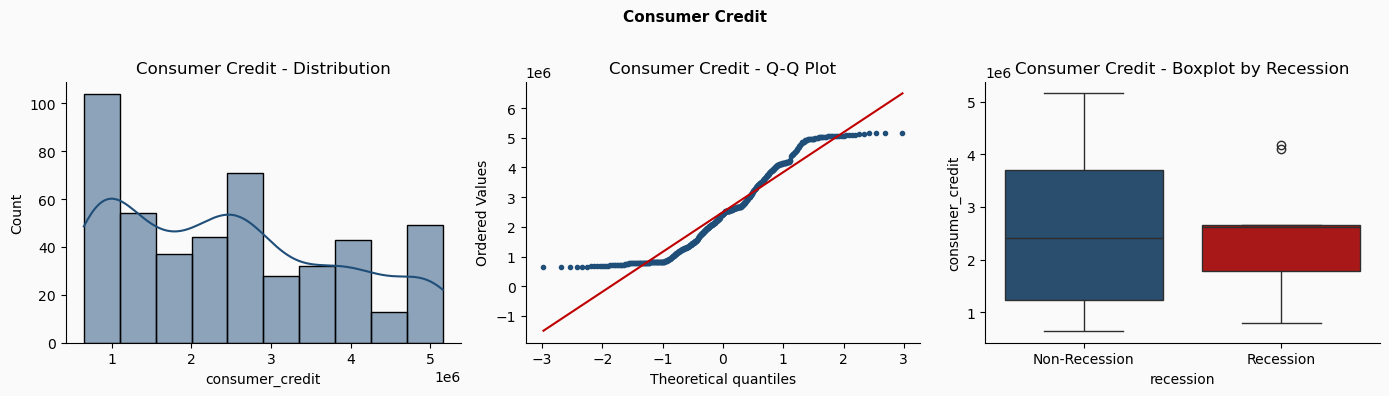

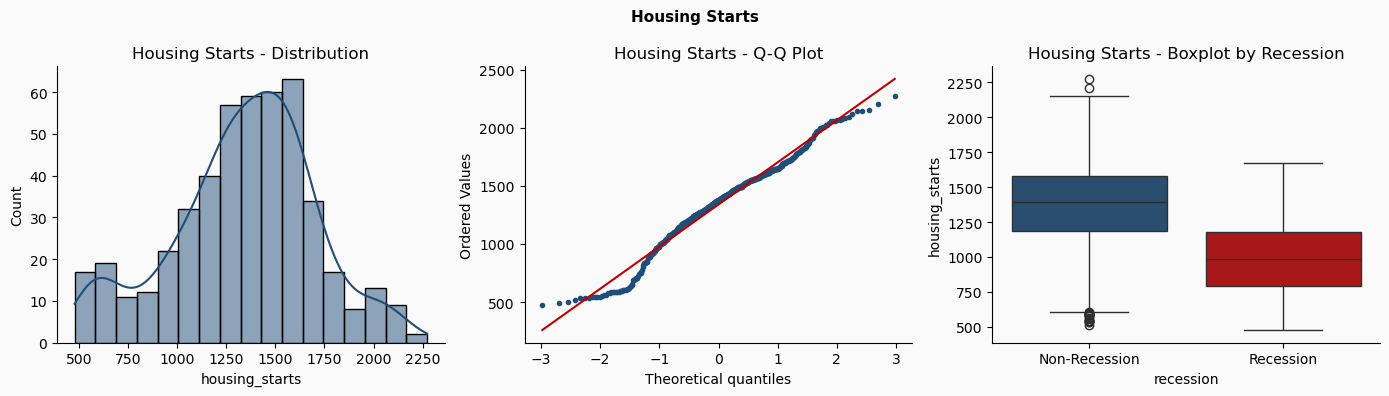

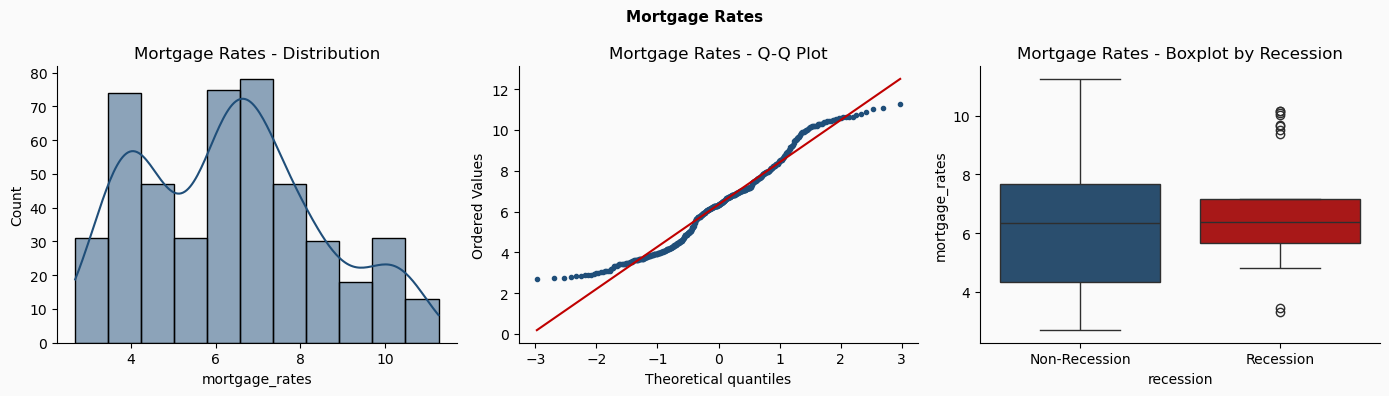

In [41]:
# Distribution Plots - 1987 Dataset 

features_1987_dist = [c for c in df_1987.columns if c != "recession"]

for feat in features_1987_dist:
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    fig.patch.set_facecolor("#fafafa")

    for ax in axes:
        ax.set_facecolor("#fafafa")
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)

    sns.histplot(df_1987[feat], kde=True, ax=axes[0], color="#1f4e79")
    axes[0].set_title(f"{feat.replace('_', ' ').title()} - Distribution")

    stats.probplot(df_1987[feat], dist="norm", plot=axes[1])
    axes[1].get_lines()[0].set(color="#1f4e79", markersize=3)
    axes[1].get_lines()[1].set(color="#c00000")
    axes[1].set_title(f"{feat.replace('_', ' ').title()} - Q-Q Plot")

    sns.boxplot(data=df_1987, x="recession", y=feat, ax=axes[2],
            hue="recession", palette={0.0: "#1f4e79", 1.0: "#c00000"},
            legend=False)
    axes[2].set_xticklabels(["Non-Recession", "Recession"])
    axes[2].set_title(f"{feat.replace('_', ' ').title()} - Boxplot by Recession")

    plt.suptitle(feat.replace("_", " ").title(), fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

## Correlation Analysis

Pearson correlation matrices were calculated for both datasets to identify relationships between indicators and to understand which variables are most closely associated with the recession indicator. The heatmaps use a diverging colour scale centred at zero, with deep red indicating strong positive correlations and deep blue indicating strong negative correlations. The upper triangle is masked to avoid duplication.

### 1960 Dataset

The most striking feature of the 1960 correlation matrix is the very strong positive correlations between CPI, industrial production, corporate profits, M2, S&P 500 and gold, with values ranging from 0.68 to 0.99. These correlations largely reflect shared long-run upward trends across a sixty year period rather than direct economic relationships - all of these series have grown substantially over time, producing high correlations that are a consequence of the time period rather than meaningful economic linkages.

The Federal Funds Rate shows moderate negative correlations with CPI (-0.49) and industrial production (-0.48), consistent with monetary tightening in response to inflationary and output pressures. Unemployment shows weak negative correlations with most indicators, consistent with its role as a broad measure of economic health that moves inversely to growth.

Correlations with the recession indicator are notably weak across all variables, with unemployment showing the strongest positive relationship (0.17) and industrial production the strongest positive correlation (0.23) - counterintuitive given industrial production typically falls during recessions, but reflecting the long-run upward trend dominating the signal. The Federal Funds Rate shows a small negative correlation (-0.15) with recession, again reflecting the long-run decline in rates obscuring the shorter-term cyclical relationship. These weak correlations with the recession indicator reinforce the finding from the lead/lag analysis that raw levels of most indicators carry limited predictive information, and confirm the importance of feature engineering to capture shorter-term dynamics.

The high intercorrelations between trending series also have implications for Logistic Regression specifically. Multicollinearity between highly correlated raw features can destabilise coefficient estimates, making regularisation through the L1 and L2 penalty terms particularly important for that model. This is addressed in the hyperparameter tuning stage where regularisation strength is optimised through cross validation.

### 1987 Dataset

The 1987 dataset shows a similar pattern of very strong correlations between the trending series - CPI, debt/GDP, corporate profits, M2, S&P 500, gold, house prices and consumer credit all show correlations above 0.83 with each other, again reflecting shared long-run trends rather than direct economic relationships.

Several new relationships emerge from the richer indicator set. Mortgage rates show a strong negative correlation with CPI (-0.69) and a strong positive correlation with the Federal Funds Rate (0.90), reflecting the structural decline in both policy rates and mortgage rates over the post-1987 period. The yield curve shows a strong positive correlation with unemployment (0.70) and a strong negative correlation with the Federal Funds Rate (-0.62), consistent with the steepening of the yield curve that occurs when short-term rates are cut during recessions while long-term rates remain elevated.

Credit spread shows notable positive correlations with recession (0.48), jobless claims (0.29) and yield curve (0.52), confirming its role as a stress indicator that co-moves with other recession signals. Housing starts shows negative correlations with unemployment (-0.58) and consumer credit (-0.46), consistent with the decline in construction activity during economic downturns.

As in the 1960 dataset, correlations with the recession indicator remain weak across all variables, with credit spread (0.48) and jobless claims (0.29) showing the strongest relationships. This again confirms that no single indicator is sufficient to predict recessions in isolation and that engineered features capturing momentum, trend and rate of change will be more informative than raw levels for the modelling phase.

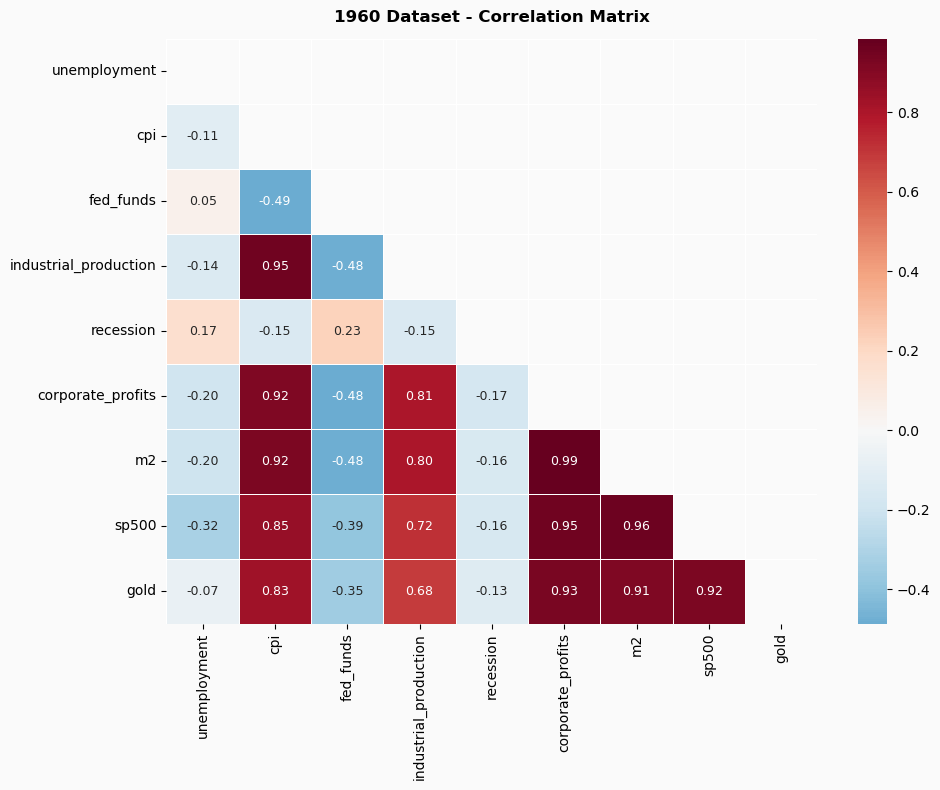

In [42]:
# Correlation Heatmap - 1960 Dataset 

corr_1960 = df_1960.corr()
mask_1960 = np.triu(np.ones_like(corr_1960, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor("#fafafa")
ax.set_facecolor("#fafafa")

sns.heatmap(corr_1960, mask=mask_1960, annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, linewidths=0.4,
            annot_kws={"size": 9}, ax=ax)

ax.set_title("1960 Dataset - Correlation Matrix", fontsize=12,
             fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

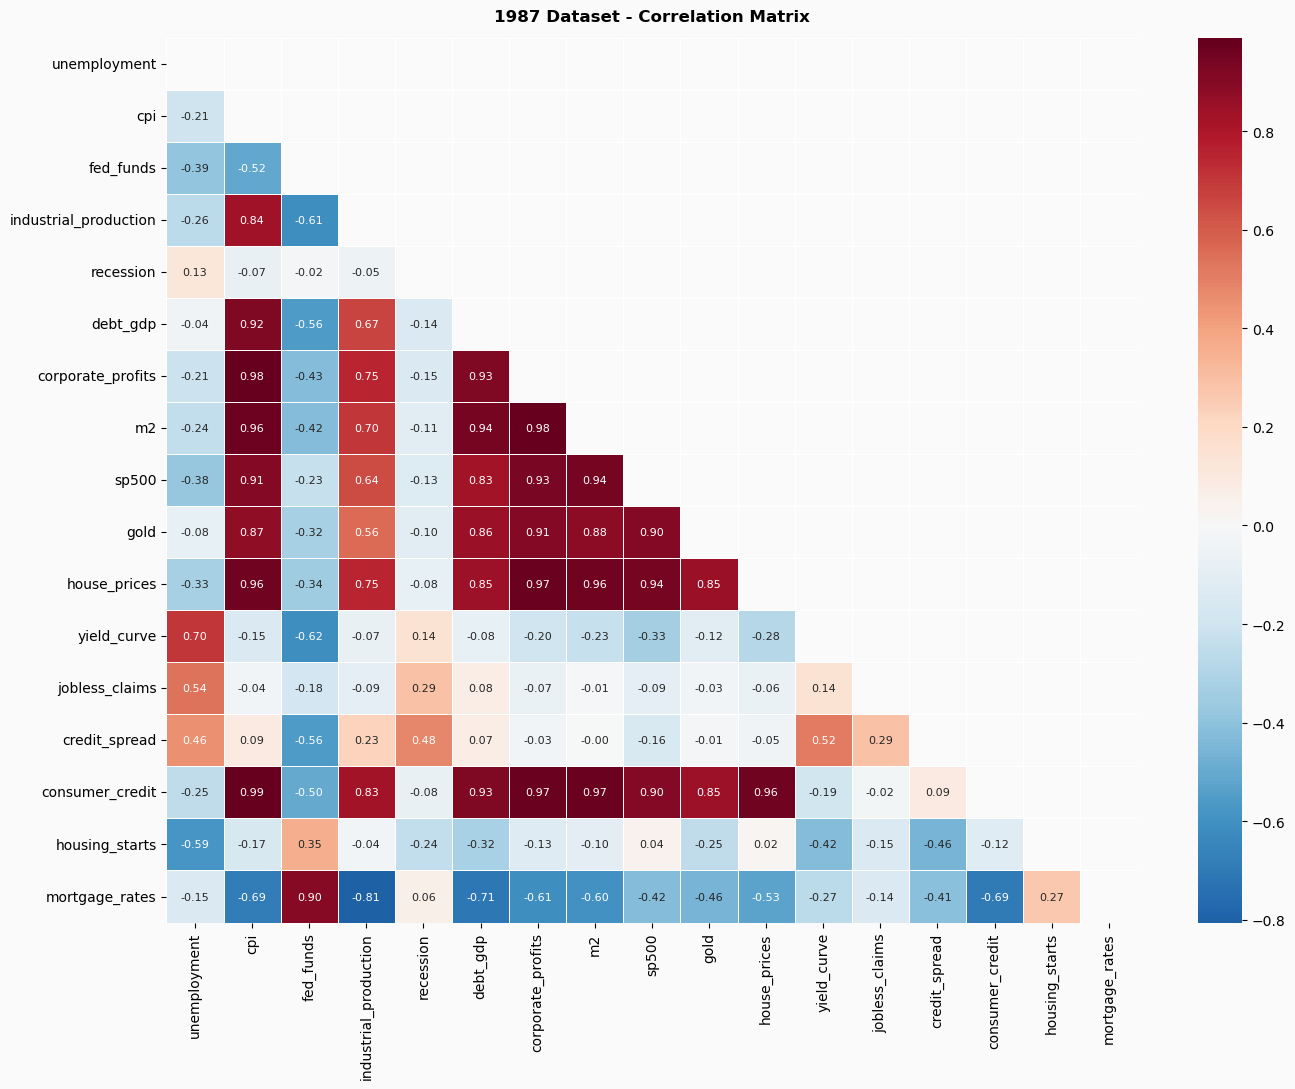

In [43]:
# Correlation Heatmap - 1987 Dataset

corr_1987 = df_1987.corr()
mask_1987 = np.triu(np.ones_like(corr_1987, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 11))
fig.patch.set_facecolor("#fafafa")
ax.set_facecolor("#fafafa")

sns.heatmap(corr_1987, mask=mask_1987, annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, linewidths=0.4,
            annot_kws={"size": 8}, ax=ax)

ax.set_title("1987 Dataset - Correlation Matrix", fontsize=12,
             fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## Feature Engineering

Feature engineering was applied to both datasets to transform the raw economic indicators into a richer set of predictive signals. The approach was directly informed by the findings of the stationarity testing and lead/lag analysis conducted in the earlier sections. The same feature engineering function was applied consistently to both datasets to ensure comparability of results across the modelling phase.

### Features Created

For each indicator in both datasets, the following features were generated:

- **Lag features at 3, 6 and 12 months** - capture the historical value of each indicator at fixed points in the past, allowing the model to learn from the trajectory of each series rather than just its current value
- **Rolling means at 3, 6 and 12 months** - smooth out short-term noise and capture the medium-term trend direction of each indicator
- **Percentage change at 1, 3 and 12 months** - capture momentum and rate of change, particularly important for non-stationary series identified by the ADF tests where raw levels carry limited predictive information
- **Rolling standard deviation at 6 and 12 months** - captures volatility within each series, which tends to increase during periods of economic stress ahead of recessions

### Extended and Interaction Features

Based on the lead/lag analysis findings, additional features were created for specific indicators:

- **Yield curve lags at 18 and 24 months** - the lead/lag analysis identified the yield curve as leading recessions by up to 22 months, justifying extended lag features beyond the standard 12 month window
- **Yield curve x credit spread** - interaction between the two strongest leading indicators in the 1987 dataset, capturing combined financial stress signals
- **Fed funds x unemployment** - interaction between monetary policy and labour market conditions, capturing the policy environment relative to economic slack
- **S&P 500 percentage change x credit spread** - interaction between equity market momentum and credit market stress, capturing combined financial market deterioration

### Results

After feature engineering the datasets expanded substantially:

- **1960 Dataset** - 97 predictive features from 9 original indicators, before feature selection
- **1987 Dataset** - 197 predictive features from 16 original indicators, before feature selection

Dropping rows with NaN values introduced by the lag and rolling window calculations reduced the 1960 dataset to 787 rows and the 1987 dataset to 451 rows. The rows lost represent approximately 3% of the 1960 dataset and 5% of the 1987 dataset, with the larger proportion lost from the 1987 dataset due to the extended 24 month yield curve lag features.

### Class Imbalance

The recession indicator remains heavily imbalanced after feature engineering, with recession months representing 11.1% of the 1960 dataset and 8.0% of the 1987 dataset. This imbalance will be addressed in the modelling phase through class weighting and appropriate evaluation metrics, and is explicitly visualised above to document the challenge before modelling begins.

In [44]:
# Feature Engineering 

# based on stationarity testing:
# stationary series (unemployment, fed_funds, yield_curve,
# jobless_claims, credit_spread, housing_starts) - lag and rolling features appropriate
# non-stationary series (cpi, industrial_production, corporate_profits,
# m2, sp500, gold, house_prices, debt_gdp, consumer_credit, mortgage_rates)
# - percentage change features prioritised

# based on lead/lag analysis:
# yield curve leads by up to 22 months - include 24 month lag
# credit spread and jobless claims lead by 1 month - include short lags
# housing starts leads by 5 months - include 6 month lag
# industrial production and sp500 lead by 11 months - include 12 month lag

def engineer_features(df):
    df_fe = df.copy()
    features = [c for c in df.columns if c != "recession"]

    for feat in features:
        # lag features
        df_fe[f"{feat}_lag3"]  = df_fe[feat].shift(3)
        df_fe[f"{feat}_lag6"]  = df_fe[feat].shift(6)
        df_fe[f"{feat}_lag12"] = df_fe[feat].shift(12)

        # rolling means
        df_fe[f"{feat}_roll3"]  = df_fe[feat].rolling(3).mean()
        df_fe[f"{feat}_roll6"]  = df_fe[feat].rolling(6).mean()
        df_fe[f"{feat}_roll12"] = df_fe[feat].rolling(12).mean()

        # percentage change - month over month
        df_fe[f"{feat}_pct1"]  = df_fe[feat].pct_change(1)
        df_fe[f"{feat}_pct3"]  = df_fe[feat].pct_change(3)
        df_fe[f"{feat}_pct12"] = df_fe[feat].pct_change(12)

        # rolling standard deviation - captures volatility
        df_fe[f"{feat}_std6"]  = df_fe[feat].rolling(6).std()
        df_fe[f"{feat}_std12"] = df_fe[feat].rolling(12).std()

    # extended lags for yield curve given 22 month lead time
    if "yield_curve" in features:
        df_fe["yield_curve_lag18"] = df_fe["yield_curve"].shift(18)
        df_fe["yield_curve_lag24"] = df_fe["yield_curve"].shift(24)

    # interaction features
    if "yield_curve" in features and "credit_spread" in features:
        df_fe["yield_x_credit"] = df_fe["yield_curve"] * df_fe["credit_spread"]

    if "fed_funds" in features and "unemployment" in features:
        df_fe["funds_x_unemployment"] = df_fe["fed_funds"] * df_fe["unemployment"]

    if "sp500" in features and "credit_spread" in features:
        df_fe["sp500_x_credit"] = df_fe["sp500_pct1"] * df_fe["credit_spread"]

    return df_fe

df_1960_fe = engineer_features(df_1960)
df_1987_fe = engineer_features(df_1987)

print(f"1960 Dataset - Features after engineering: {df_1960_fe.shape[1] - 1}")
print(f"1987 Dataset - Features after engineering: {df_1987_fe.shape[1] - 1}")

1960 Dataset - Features after engineering: 97
1987 Dataset - Features after engineering: 197


In [45]:
# Drop NaNs introduced by lags and rolling windows

df_1960_fe = df_1960_fe.dropna()
df_1987_fe = df_1987_fe.dropna()

print(f"1960 Dataset shape after dropping NaNs: {df_1960_fe.shape}")
print(f"1987 Dataset shape after dropping NaNs: {df_1987_fe.shape}")
print(f"\n1960 Recession %: {df_1960_fe['recession'].mean():.1%}")
print(f"1987 Recession %: {df_1987_fe['recession'].mean():.1%}")

1960 Dataset shape after dropping NaNs: (787, 98)
1987 Dataset shape after dropping NaNs: (451, 198)

1960 Recession %: 11.1%
1987 Recession %: 8.0%


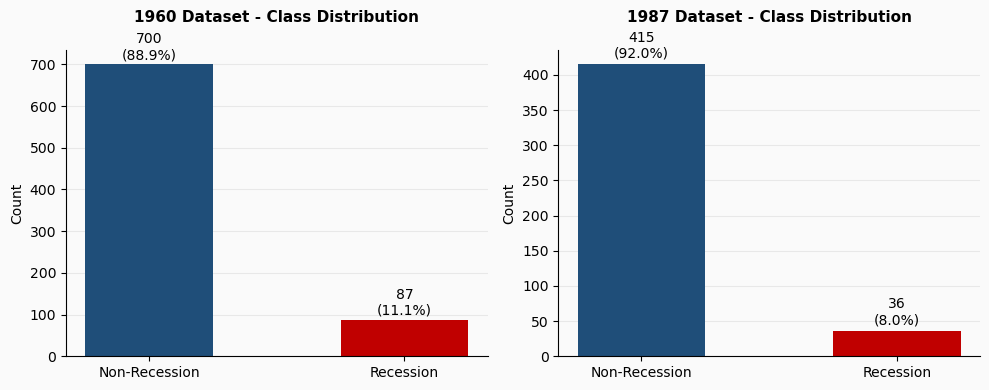

In [46]:
# Class Imbalance Visualisation 

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.patch.set_facecolor("#fafafa")

for ax, df_plot, label in [
    (axes[0], df_1960_fe, "1960 Dataset"),
    (axes[1], df_1987_fe, "1987 Dataset"),
]:
    ax.set_facecolor("#fafafa")
    counts = df_plot["recession"].value_counts().sort_index()
    bars = ax.bar(["Non-Recession", "Recession"],
                  counts.values,
                  color=["#1f4e79", "#c00000"],
                  width=0.5)
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 5,
                f"{val}\n({val/len(df_plot):.1%})",
                ha="center", va="bottom", fontsize=10)
    ax.set_title(f"{label} - Class Distribution", fontsize=11, fontweight="bold", pad=20)
    ax.set_ylabel("Count")
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

## Feature Selection

With 97 features in the 1960 dataset and 197 in the 1987 dataset after engineering, feature selection was applied to remove redundant and highly correlated features before modelling. Including highly correlated features adds noise without adding information and can destabilise some models, particularly Logistic Regression where multicollinearity between predictors inflates coefficient variance.

### Removing Highly Correlated Features

A correlation threshold of 0.95 was applied across all engineered features. This threshold was chosen to remove near-duplicate features while retaining genuinely distinct signals - a lower threshold would risk removing features that carry different economic information despite being correlated, while a higher threshold would leave too much redundancy in the feature set. Any feature with a correlation above 0.95 with another feature was removed, retaining the first of each correlated pair. This reduced the feature sets substantially:

- **1960 Dataset** - 48 features removed, 49 retained from 97
- **1987 Dataset** - 87 features removed, 110 retained from 197

The high number of removals is expected given the feature engineering approach - lag and rolling features of the same indicator at similar windows are naturally highly correlated with each other, and percentage change features of trending series tend to move together. These 49 and 110 features respectively are the final input feature sets used in all subsequent modelling steps.

### Feature Correlation with Recession

To understand which engineered features carry the most direct signal for recession prediction, the correlation of each retained feature with the recession indicator was calculated and the top 30 are shown in the bar charts above for each dataset. Red bars indicate positive correlations with recession and navy bars indicate negative correlations.

**1960 Dataset** - the strongest positively correlated features are fed_funds_std6 (0.40), unemployment_pct12 (0.38) and fed_funds_lag12 (0.37), indicating that volatility in the Federal Funds Rate and the 12 month change in unemployment are the strongest individual signals. The strongest negatively correlated features are industrial_production_pct3 (-0.48), sp500_pct12 (-0.46) and industrial_production_pct12 (-0.43), confirming that declining industrial production and falling equity markets are among the most reliable recession signals in the longer historical dataset. The interaction feature funds_x_unemployment also appears in the top 30 with a positive correlation of around 0.30, validating the decision to include interaction terms.

**1987 Dataset** - the strongest features are credit_spread_pct12 (above 0.50), credit_spread (0.48) and debt_gdp_pct3 (0.45), with several yield curve and credit spread variants appearing in the top 30. This confirms the findings from the lead/lag analysis that credit spread and yield curve are the strongest leading indicators in the modern dataset. The extended yield curve lag features yield_curve_lag18 and yield_curve_lag24 and the interaction feature yield_x_credit both appear in the top 30, confirming the value of those additions. Negative correlations are dominated by industrial production, housing starts and S&P 500 percentage change features, consistent with the economic understanding that declining output, construction and equity markets precede recessions.

These findings directly inform the interpretation of model feature importance in the modelling phase and confirm that the feature engineering approach has successfully created informative predictive signals from the raw economic indicators.

In [47]:
# Feature Selection - Remove Highly Correlated Features

from sklearn.preprocessing import StandardScaler

def remove_correlated_features(df, threshold=0.95):
    features = [c for c in df.columns if c != "recession"]
    X = df[features]
    corr_matrix = X.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop = [col for col in upper.columns if any(upper[col] > threshold)]
    print(f"Features removed (correlation > {threshold}): {len(to_drop)}")
    print(f"Features retained: {len(features) - len(to_drop)}")
    return df.drop(columns=to_drop), to_drop

df_1960_sel, dropped_1960 = remove_correlated_features(df_1960_fe, threshold=0.95)
df_1987_sel, dropped_1987 = remove_correlated_features(df_1987_fe, threshold=0.95)

print(f"\n1960 Dataset shape after feature selection: {df_1960_sel.shape}")
print(f"1987 Dataset shape after feature selection: {df_1987_sel.shape}")

Features removed (correlation > 0.95): 48
Features retained: 49
Features removed (correlation > 0.95): 87
Features retained: 110

1960 Dataset shape after feature selection: (787, 50)
1987 Dataset shape after feature selection: (451, 111)


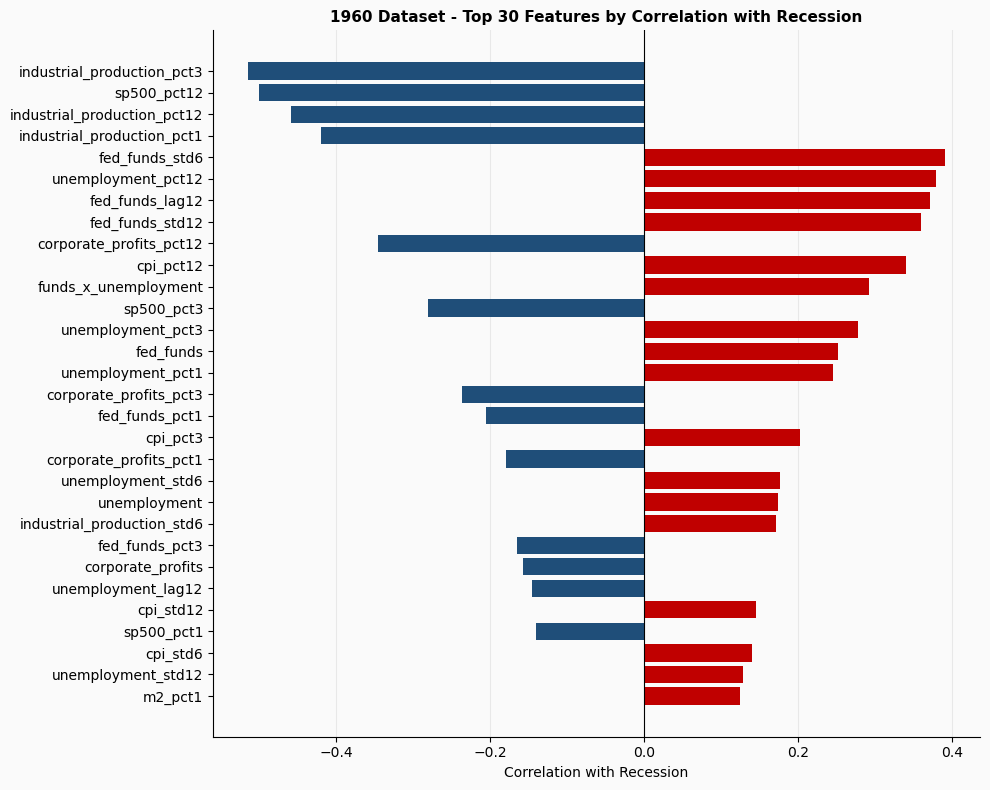

In [48]:
# Correlation Heatmap of Remaining Features - 1960
# with 97 features a full heatmap is unreadable
# instead show correlation of each feature with recession only

features_1960_sel = [c for c in df_1960_sel.columns if c != "recession"]

recession_corr_1960 = (
    df_1960_sel[features_1960_sel + ["recession"]]
    .corr()["recession"]
    .drop("recession")
    .sort_values(key=abs, ascending=False)
    .head(30)
)

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor("#fafafa")
ax.set_facecolor("#fafafa")

colours = ["#c00000" if v > 0 else "#1f4e79" for v in recession_corr_1960.values]
ax.barh(recession_corr_1960.index[::-1], recession_corr_1960.values[::-1], color=colours[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("1960 Dataset - Top 30 Features by Correlation with Recession",
             fontsize=11, fontweight="bold")
ax.set_xlabel("Correlation with Recession")
ax.yaxis.grid(False)
ax.xaxis.grid(True, color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

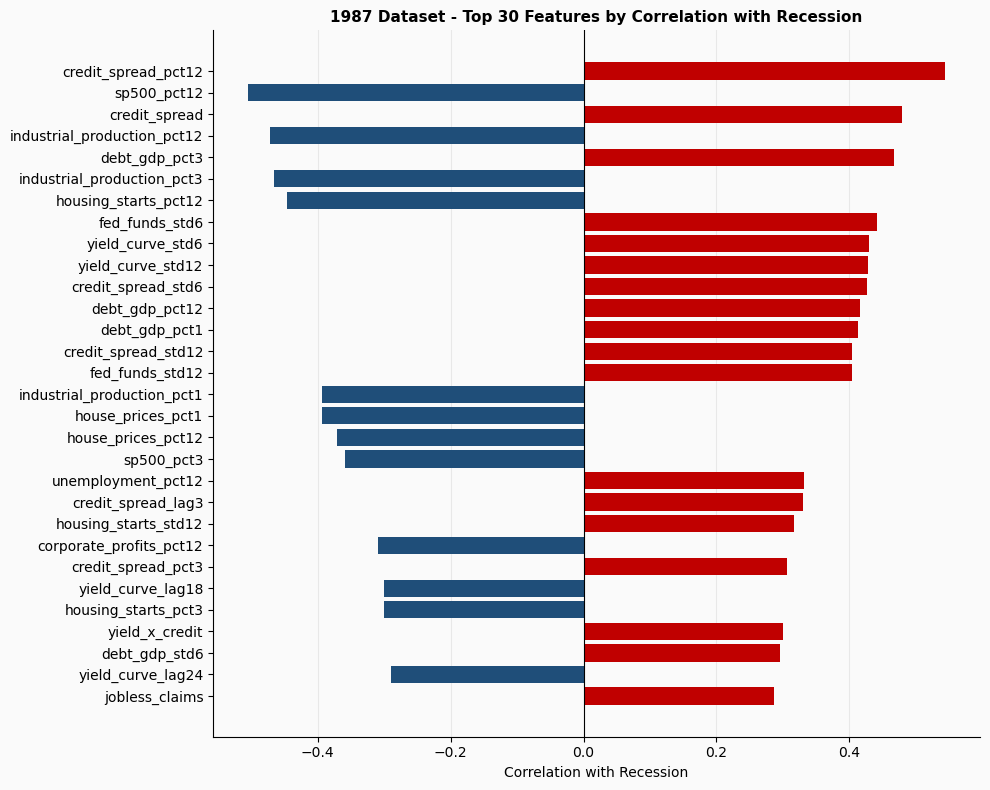

In [49]:
# Correlation with Recession - 1987 Dataset

features_1987_sel = [c for c in df_1987_sel.columns if c != "recession"]

recession_corr_1987 = (
    df_1987_sel[features_1987_sel + ["recession"]]
    .corr()["recession"]
    .drop("recession")
    .sort_values(key=abs, ascending=False)
    .head(30)
)

fig, ax = plt.subplots(figsize=(10, 8))
fig.patch.set_facecolor("#fafafa")
ax.set_facecolor("#fafafa")

colours = ["#c00000" if v > 0 else "#1f4e79" for v in recession_corr_1987.values]
ax.barh(recession_corr_1987.index[::-1], recession_corr_1987.values[::-1], color=colours[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("1987 Dataset - Top 30 Features by Correlation with Recession",
             fontsize=11, fontweight="bold")
ax.set_xlabel("Correlation with Recession")
ax.yaxis.grid(False)
ax.xaxis.grid(True, color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

## Train/Test Split and Scaling

### Temporal Train/Test Split

Both datasets were split into training and test sets using a temporal 80/20 split, preserving the chronological order of the data. Unlike a random split, a temporal split ensures that the model is always trained on historical data and evaluated on future data, reflecting the real-world conditions under which a recession prediction model would operate. A random split would allow future observations to leak into the training set, artificially inflating performance metrics.

- **1960 Dataset** - 629 training rows (to May 2013) and 158 test rows (June 2013 onwards). Recession months in train: 13.5%, test: 1.3%
- **1987 Dataset** - 360 training rows (to December 2018) and 91 test rows (January 2019 onwards). Recession months in train: 9.4%, test: 2.2%

*Note: the split dates above reflect the state of the datasets at the time of writing. As the data collection code automatically retrieves the most recent available data from FRED and Yahoo Finance, running the notebook at a later date will result in a larger dataset and different split dates, with the test set extending further into the future. The 80/20 ratio will remain constant regardless of when the code is run.*

The recession percentage in the test sets is notably lower than in the training sets, reflecting the fact that the test periods are largely post-2013 and post-2018 respectively, which were predominantly non-recessionary periods aside from COVID-19. The 1960 test set contains only 2 recession months and the 1987 test set contains 2 recession months, both from the COVID-19 recession. This is a genuine limitation of the temporal split approach for a dataset with so few recession episodes - it is acknowledged that test set evaluation metrics will be unreliable with such a small number of positive cases, and cross-validation scores across the training set will therefore be the more meaningful measure of model performance.

### Scaling

StandardScaler was applied to both datasets after splitting. The scaler was fitted on the training data only and then applied to the test set using the training parameters. Separate scalers were fitted independently for each dataset to avoid any cross-dataset leakage. Fitting the scaler on the full dataset before splitting would leak test set statistics into the training process, subtly inflating performance metrics. The scaling output confirms the training sets have been correctly standardised to approximately zero mean and unit standard deviation.

Scaling ensures that all features are on a comparable scale before being passed to the models. While tree-based models such as Random Forest and XGBoost are not sensitive to feature scale, Logistic Regression benefits from standardised features as its regularisation penalty treats all coefficients equally regardless of the original scale of their corresponding features. Applying consistent scaling across all models also ensures fair comparison of feature importance scores across different model types.

In [50]:
# Train/Test Split 
# temporal split preserving chronological order
# no random shuffling - future data must not leak into training

split_1960 = int(len(df_1960_sel) * 0.8)
split_1987 = int(len(df_1987_sel) * 0.8)

X_1960 = df_1960_sel.drop(columns=["recession"])
y_1960 = df_1960_sel["recession"]

X_1987 = df_1987_sel.drop(columns=["recession"])
y_1987 = df_1987_sel["recession"]

X_1960_train = X_1960.iloc[:split_1960]
X_1960_test  = X_1960.iloc[split_1960:]
y_1960_train = y_1960.iloc[:split_1960]
y_1960_test  = y_1960.iloc[split_1960:]

X_1987_train = X_1987.iloc[:split_1987]
X_1987_test  = X_1987.iloc[split_1987:]
y_1987_train = y_1987.iloc[:split_1987]
y_1987_test  = y_1987.iloc[split_1987:]

print(f"1960 - Train: {X_1960_train.shape[0]} rows | Test: {X_1960_test.shape[0]} rows")
print(f"1960 - Split date: {X_1960_test.index.min().date()}")
print(f"1960 - Recession % in train: {y_1960_train.mean():.1%} | test: {y_1960_test.mean():.1%}")
print()
print(f"1987 - Train: {X_1987_train.shape[0]} rows | Test: {X_1987_test.shape[0]} rows")
print(f"1987 - Split date: {X_1987_test.index.min().date()}")
print(f"1987 - Recession % in train: {y_1987_train.mean():.1%} | test: {y_1987_test.mean():.1%}")

1960 - Train: 629 rows | Test: 158 rows
1960 - Split date: 2013-06-01
1960 - Recession % in train: 13.5% | test: 1.3%

1987 - Train: 360 rows | Test: 91 rows
1987 - Split date: 2019-01-01
1987 - Recession % in train: 9.4% | test: 2.2%


In [51]:
# Scaling
# fit scaler on training data only
# applying to test set using training parameters prevents data leakage

from sklearn.preprocessing import StandardScaler

scaler_1960 = StandardScaler()
scaler_1987 = StandardScaler()

X_1960_train_scaled = pd.DataFrame(
    scaler_1960.fit_transform(X_1960_train),
    columns=X_1960_train.columns,
    index=X_1960_train.index
)
X_1960_test_scaled = pd.DataFrame(
    scaler_1960.transform(X_1960_test),
    columns=X_1960_test.columns,
    index=X_1960_test.index
)

X_1987_train_scaled = pd.DataFrame(
    scaler_1987.fit_transform(X_1987_train),
    columns=X_1987_train.columns,
    index=X_1987_train.index
)
X_1987_test_scaled = pd.DataFrame(
    scaler_1987.transform(X_1987_test),
    columns=X_1987_test.columns,
    index=X_1987_test.index
)

print("Scaling complete")
print(f"\n1960 train mean (should be ~0): {X_1960_train_scaled.mean().mean():.6f}")
print(f"1960 train std  (should be ~1): {X_1960_train_scaled.std().mean():.6f}")
print(f"1987 train mean (should be ~0): {X_1987_train_scaled.mean().mean():.6f}")
print(f"1987 train std  (should be ~1): {X_1987_train_scaled.std().mean():.6f}")

Scaling complete

1960 train mean (should be ~0): -0.000000
1960 train std  (should be ~1): 1.000796
1987 train mean (should be ~0): 0.000000
1987 train std  (should be ~1): 1.001392


## Class Imbalance Handling

The significant class imbalance identified earlier presents a fundamental challenge for model training. With recession months representing only 11.1% of the 1960 training set (85 out of 629 rows) and 9.4% of the 1987 training set (34 out of 360 rows), a model that simply predicts non-recession for every observation would achieve accuracy of approximately 86-91% while being completely useless for the intended purpose. Two complementary approaches to handling this imbalance were evaluated:

### Approach 1 - Class Weighting

Class weighting adjusts the loss function during model training to penalise misclassification of the minority class more heavily. Rather than changing the training data, it changes how the model learns from it. This approach is supported natively by Logistic Regression and Random Forest through the `class_weight="balanced"` parameter, and by XGBoost through the `scale_pos_weight` parameter.

The scale_pos_weight values calculated from the training data are:

- **1960 Dataset** - 6.40, meaning each recession month is weighted as equivalent to 6.40 non-recession months during training
- **1987 Dataset** - 9.59, meaning each recession month is weighted as equivalent to 9.59 non-recession months during training

### Approach 2 - Oversampling

Random oversampling with replacement was applied to the training sets to create balanced class distributions. The minority class - recession months - was resampled to match the size of the majority class, producing fully balanced training sets:

- **1960 Dataset** - 544 recession and 544 non-recession months after oversampling, up from 85 recession months
- **1987 Dataset** - 326 recession and 326 non-recession months after oversampling, up from 34 recession months

It should be noted that this approach uses random oversampling with replacement rather than SMOTE, which generates synthetic minority class samples through interpolation between existing observations. Random oversampling simply duplicates existing recession months, which introduces some risk of overfitting to the specific recession months in the training set. SMOTE would be preferable in a production context but was not used here due to package compatibility constraints.

An important methodological consideration is that oversampling must be applied inside each cross validation fold rather than before the fold split. Applying oversampling before cross validation causes duplicated recession months to appear in both the training and test folds of the same split, leaking information and producing artificially inflated CV scores. In this project oversampling is applied fresh within each fold during cross validation to ensure honest evaluation.

In both approaches the test sets remain completely unchanged, ensuring that evaluation metrics reflect performance on real unseen data rather than synthetic or reweighted observations.

### Comparison

Cross validation results showed that class weighting and oversampling produced near identical CV AUC and F1 scores across all models and both datasets. Given this equivalence, class weighting was adopted as the preferred approach for the final models due to its simplicity, lower computational cost, and avoidance of the additional complexity of in-fold oversampling. The oversampling results are included in the comparison table for completeness.

In [52]:
#pip install --upgrade imbalanced-learn

In [53]:
# Class Imbalance Handling 

from imblearn.over_sampling import SMOTE
from collections import Counter
from sklearn.utils import shuffle

# calculate class weight ratio for XGBoost scale_pos_weight
spw_1960 = (y_1960_train == 0).sum() / (y_1960_train == 1).sum()
spw_1987 = (y_1987_train == 0).sum() / (y_1987_train == 1).sum()

print(f"1960 - Non-Recession: {(y_1960_train == 0).sum()} | Recession: {(y_1960_train == 1).sum()}")
print(f"1960 - scale_pos_weight: {spw_1960:.2f}")
print()
print(f"1987 - Non-Recession: {(y_1987_train == 0).sum()} | Recession: {(y_1987_train == 1).sum()}")
print(f"1987 - scale_pos_weight: {spw_1987:.2f}")

1960 - Non-Recession: 544 | Recession: 85
1960 - scale_pos_weight: 6.40

1987 - Non-Recession: 326 | Recession: 34
1987 - scale_pos_weight: 9.59


In [54]:
# Oversampling

from sklearn.utils import resample

def oversample_minority(X_train, y_train, random_state=42):
    X = pd.DataFrame(X_train) if not isinstance(X_train, pd.DataFrame) else X_train
    y = pd.Series(y_train) if not isinstance(y_train, pd.Series) else y_train

    X_majority = X[y == 0]
    X_minority = X[y == 1]
    y_majority = y[y == 0]
    y_minority = y[y == 1]

    X_minority_up = resample(X_minority, replace=True,
                              n_samples=len(X_majority),
                              random_state=random_state)
    y_minority_up = resample(y_minority, replace=True,
                              n_samples=len(y_majority),
                              random_state=random_state)

    X_balanced = pd.concat([X_majority, X_minority_up])
    y_balanced = pd.concat([y_majority, y_minority_up])

    return X_balanced, y_balanced

X_1960_train_smote, y_1960_train_smote = oversample_minority(
    X_1960_train_scaled, y_1960_train)
X_1987_train_smote, y_1987_train_smote = oversample_minority(
    X_1987_train_scaled, y_1987_train)

print(f"1960 - Before: {Counter(y_1960_train)} | After: {Counter(y_1960_train_smote)}")
print(f"1987 - Before: {Counter(y_1987_train)} | After: {Counter(y_1987_train_smote)}")

1960 - Before: Counter({0.0: 544, 1.0: 85}) | After: Counter({0.0: 544, 1.0: 544})
1987 - Before: Counter({0.0: 326, 1.0: 34}) | After: Counter({0.0: 326, 1.0: 326})


In [55]:
# Shuffle Oversampled Data

# synthetic recession months are appended at the end of the dataset
# shuffling ensures both classes appear in all CV folds
# shuffling is acceptable here as temporal ordering is already broken by the oversampling process

X_1960_train_smote, y_1960_train_smote = shuffle(
    X_1960_train_smote, y_1960_train_smote, random_state=42)

X_1987_train_smote, y_1987_train_smote = shuffle(
    X_1987_train_smote, y_1987_train_smote, random_state=42)

print(f"1960 SMOTE shuffled: {Counter(y_1960_train_smote)}")
print(f"1987 SMOTE shuffled: {Counter(y_1987_train_smote)}")

1960 SMOTE shuffled: Counter({0.0: 544, 1.0: 544})
1987 SMOTE shuffled: Counter({1.0: 326, 0.0: 326})


In [56]:
# Summary of Imbalance Handling Approaches 

print("Imbalance handling approaches:")
print("  1. Class weighting  - adjusts loss function during training")
print("  2. Oversampling     - duplicates minority class to balance training set")
print()
print("Both will be evaluated in the modelling phase")
print("Test sets remain unchanged in both approaches")

Imbalance handling approaches:
  1. Class weighting  - adjusts loss function during training
  2. Oversampling     - duplicates minority class to balance training set

Both will be evaluated in the modelling phase
Test sets remain unchanged in both approaches


## Model Training and Cross Validation

Three machine learning models were trained and evaluated using TimeSeriesSplit cross validation with five folds: Logistic Regression, Random Forest and XGBoost. Each model was evaluated under two class imbalance handling approaches: class weighting and oversampling applied inside each cross validation fold.

### Cross Validation Approach

TimeSeriesSplit was used rather than standard k-fold cross validation to preserve the temporal ordering of the data. Standard k-fold shuffles observations randomly, which would allow future data to leak into training folds and inflate performance metrics. TimeSeriesSplit expands the training window sequentially, always training on past data and evaluating on future data, consistent with how the model would operate in practice.

Models were evaluated on CV F1 score and CV AUC-ROC rather than accuracy. Given the class imbalance of 11.1% and 9.4% recession months in the 1960 and 1987 training sets respectively, accuracy is a misleading metric - a model predicting non-recession for every observation would achieve over 88% accuracy while being completely uninformative.

### Results

The full cross validation results are shown in the table and bar chart above. Key findings are as follows:

**Logistic Regression** was the strongest performer across both datasets, achieving CV AUC of 0.962 on the 1960 dataset and 0.987 on the 1987 dataset with the highest and most consistent F1 scores of 0.657 and 0.763 respectively.

**Random Forest** showed strong AUC scores (0.976 on 1960, 0.952 on 1987) but very low and unstable F1 scores (0.307 on 1960, 0.095 on 1987), suggesting it can rank recession risk correctly by probability but consistently struggles to classify individual months at the 0.5 decision threshold. This pattern held across both datasets and both imbalance handling approaches, leading to the decision to drop Random Forest from the hyperparameter tuning stage.

**XGBoost** performed moderately with CV AUC of 0.930 on the 1960 dataset and 0.822 on the 1987 dataset, with high standard deviations across both metrics indicating inconsistent performance across folds.

Class weighting and oversampling produced near identical results across all models and both datasets, confirming that for this problem the two approaches are equivalent. Class weighting is therefore the preferred approach going forward.

The high standard deviations observed across all models - for example ±0.114 on LR F1 for the 1960 dataset - reflect the sparsity of recession months across folds rather than model instability. In practical terms this means performance varied substantially depending on which fold happened to contain recession months, making the mean CV score a more reliable guide than any individual fold result. This is an acknowledged limitation of applying TimeSeriesSplit to a dataset with rare positive cases.

Based on these results, Logistic Regression and XGBoost with class weighting will be carried forward to hyperparameter tuning, using both the 1960 and 1987 datasets. Random Forest is excluded from further evaluation given its consistently poor F1 performance despite reasonable AUC scores.

In [57]:
# Model Setup 

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import (f1_score, roc_auc_score, recall_score,
                              classification_report, confusion_matrix,
                              RocCurveDisplay)

tscv = TimeSeriesSplit(n_splits=5)

# models with class weighting
models_weighted = {
    "Logistic Regression": {
        "1960": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
        "1987": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    },
    "Random Forest": {
        "1960": RandomForestClassifier(class_weight="balanced", n_estimators=200,
                                        random_state=42, n_jobs=-1),
        "1987": RandomForestClassifier(class_weight="balanced", n_estimators=200,
                                        random_state=42, n_jobs=-1),
    },
    "XGBoost": {
        "1960": XGBClassifier(scale_pos_weight=spw_1960, n_estimators=200,
                               random_state=42, eval_metric="logloss", verbosity=0),
        "1987": XGBClassifier(scale_pos_weight=spw_1987, n_estimators=200,
                               random_state=42, eval_metric="logloss", verbosity=0),
    },
}

# models with oversampling - no class weighting needed as data is balanced
models_smote = {
    "Logistic Regression": {
        "1960": LogisticRegression(max_iter=1000, random_state=42),
        "1987": LogisticRegression(max_iter=1000, random_state=42),
    },
    "Random Forest": {
        "1960": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
        "1987": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    },
    "XGBoost": {
        "1960": XGBClassifier(n_estimators=200, random_state=42,
                               eval_metric="logloss", verbosity=0),
        "1987": XGBClassifier(n_estimators=200, random_state=42,
                               eval_metric="logloss", verbosity=0),
    },
}

print("Models initialised")

Models initialised


In [58]:
# Cross Validation Function - Class Weighting

def run_cv(models, datasets, label):
    results = []
    print(f"\n{'='*60}")
    print(f"{label}")
    print(f"{'='*60}")

    for model_name, model_dict in models.items():
        for ds_name, (X_train, y_train) in datasets.items():
            model = model_dict[ds_name]
            f1_scores  = []
            auc_scores = []

            for train_idx, test_idx in tscv.split(X_train):
                X_tr = X_train.iloc[train_idx] if hasattr(X_train, "iloc") else X_train[train_idx]
                X_te = X_train.iloc[test_idx]  if hasattr(X_train, "iloc") else X_train[test_idx]
                y_tr = y_train.iloc[train_idx]
                y_te = y_train.iloc[test_idx]

                model.fit(X_tr, y_tr)
                pred  = model.predict(X_te)
                proba = model.predict_proba(X_te)[:, 1]

                if y_te.sum() > 0 and len(set(y_te)) > 1:
                    f1_scores.append(f1_score(y_te, pred, zero_division=0))
                    auc_scores.append(roc_auc_score(y_te, proba))

            print(f"\n{model_name} | {ds_name} Dataset")
            print(f"  CV F1:  {np.mean(f1_scores):.3f} ± {np.std(f1_scores):.3f}")
            print(f"  CV AUC: {np.mean(auc_scores):.3f} ± {np.std(auc_scores):.3f}")

            results.append({
                "Model":      model_name,
                "Dataset":    ds_name,
                "Approach":   label,
                "CV F1":      round(np.mean(f1_scores), 3),
                "CV F1 Std":  round(np.std(f1_scores), 3),
                "CV AUC":     round(np.mean(auc_scores), 3),
                "CV AUC Std": round(np.std(auc_scores), 3),
            })

    return results

datasets_weighted = {
    "1960": (X_1960_train_scaled, y_1960_train),
    "1987": (X_1987_train_scaled, y_1987_train),
}

results_weighted = run_cv(models_weighted, datasets_weighted, "Class Weighting")


Class Weighting

Logistic Regression | 1960 Dataset
  CV F1:  0.657 ± 0.114
  CV AUC: 0.962 ± 0.025

Logistic Regression | 1987 Dataset
  CV F1:  0.763 ± 0.261
  CV AUC: 0.987 ± 0.018

Random Forest | 1960 Dataset
  CV F1:  0.307 ± 0.314
  CV AUC: 0.976 ± 0.024

Random Forest | 1987 Dataset
  CV F1:  0.095 ± 0.135
  CV AUC: 0.952 ± 0.065

XGBoost | 1960 Dataset
  CV F1:  0.561 ± 0.299
  CV AUC: 0.930 ± 0.083

XGBoost | 1987 Dataset
  CV F1:  0.190 ± 0.269
  CV AUC: 0.822 ± 0.228


In [59]:
# CV with Oversampling Inside Each Fold 
# oversampling must be applied inside each fold to prevent leakage
# applying it before CV causes identical rows to appear in both train and test folds, inflating all metrics

def run_cv_smote(models, datasets, label):
    results = []
    print(f"\n{'='*60}")
    print(f"{label}")
    print(f"{'='*60}")

    for model_name, model_dict in models.items():
        for ds_name, (X_train, y_train) in datasets.items():
            model = model_dict[ds_name]
            f1_scores  = []
            auc_scores = []

            X_arr = np.array(X_train)
            y_arr = np.array(y_train)

            for train_idx, test_idx in tscv.split(X_arr):
                X_tr = X_arr[train_idx]
                X_te = X_arr[test_idx]
                y_tr = y_arr[train_idx]
                y_te = y_arr[test_idx]

                # apply oversampling inside the fold on training data only
                X_tr_df = pd.DataFrame(X_tr)
                y_tr_s  = pd.Series(y_tr)
                X_tr_bal, y_tr_bal = oversample_minority(X_tr_df, y_tr_s)
                X_tr_bal, y_tr_bal = shuffle(X_tr_bal, y_tr_bal, random_state=42)

                model.fit(np.array(X_tr_bal), np.array(y_tr_bal))
                pred  = model.predict(X_te)
                proba = model.predict_proba(X_te)[:, 1]

                if y_te.sum() > 0 and len(set(y_te)) > 1:
                    f1_scores.append(f1_score(y_te, pred, zero_division=0))
                    auc_scores.append(roc_auc_score(y_te, proba))

            print(f"\n{model_name} | {ds_name} Dataset")
            print(f"  CV F1:  {np.mean(f1_scores):.3f} ± {np.std(f1_scores):.3f}")
            print(f"  CV AUC: {np.mean(auc_scores):.3f} ± {np.std(auc_scores):.3f}")

            results.append({
                "Model":      model_name,
                "Dataset":    ds_name,
                "Approach":   label,
                "CV F1":      round(np.mean(f1_scores), 3),
                "CV F1 Std":  round(np.std(f1_scores), 3),
                "CV AUC":     round(np.mean(auc_scores), 3),
                "CV AUC Std": round(np.std(auc_scores), 3),
            })

    return results

datasets_original = {
    "1960": (X_1960_train_scaled, y_1960_train),
    "1987": (X_1987_train_scaled, y_1987_train),
}

results_smote = run_cv_smote(models_smote, datasets_original, "Oversampling")


Oversampling

Logistic Regression | 1960 Dataset
  CV F1:  0.654 ± 0.115
  CV AUC: 0.957 ± 0.022

Logistic Regression | 1987 Dataset
  CV F1:  0.763 ± 0.261
  CV AUC: 0.986 ± 0.019

Random Forest | 1960 Dataset
  CV F1:  0.374 ± 0.350
  CV AUC: 0.964 ± 0.037

Random Forest | 1987 Dataset
  CV F1:  0.095 ± 0.135
  CV AUC: 0.949 ± 0.072

XGBoost | 1960 Dataset
  CV F1:  0.598 ± 0.331
  CV AUC: 0.930 ± 0.113

XGBoost | 1987 Dataset
  CV F1:  0.190 ± 0.269
  CV AUC: 0.822 ± 0.228


In [60]:
# Combined Results Summary 

all_results = pd.DataFrame(results_weighted + results_smote)
all_results = all_results.sort_values(["Dataset", "CV AUC"], ascending=[True, False])

print("\nFull CV Results Summary:")
display(all_results)


Full CV Results Summary:


,Model,Dataset,Approach,CV F1,CV F1 Std,CV AUC,CV AUC Std
2,Random Forest,1960,Class Weighting,0.307,0.314,0.976,0.024
8,Random Forest,1960,Oversampling,0.374,0.350,0.964,0.037
0,Logistic Regression,1960,Class Weighting,0.657,0.114,0.962,0.025
6,Logistic Regression,1960,Oversampling,0.654,0.115,0.957,0.022
4,XGBoost,1960,Class Weighting,0.561,0.299,0.930,0.083
10,XGBoost,1960,Oversampling,0.598,0.331,0.930,0.113
1,Logistic Regression,1987,Class Weighting,0.763,0.261,0.987,0.018
7,Logistic Regression,1987,Oversampling,0.763,0.261,0.986,0.019
3,Random Forest,1987,Class Weighting,0.095,0.135,0.952,0.065
9,Random Forest,1987,Oversampling,0.095,0.135,0.949,0.072


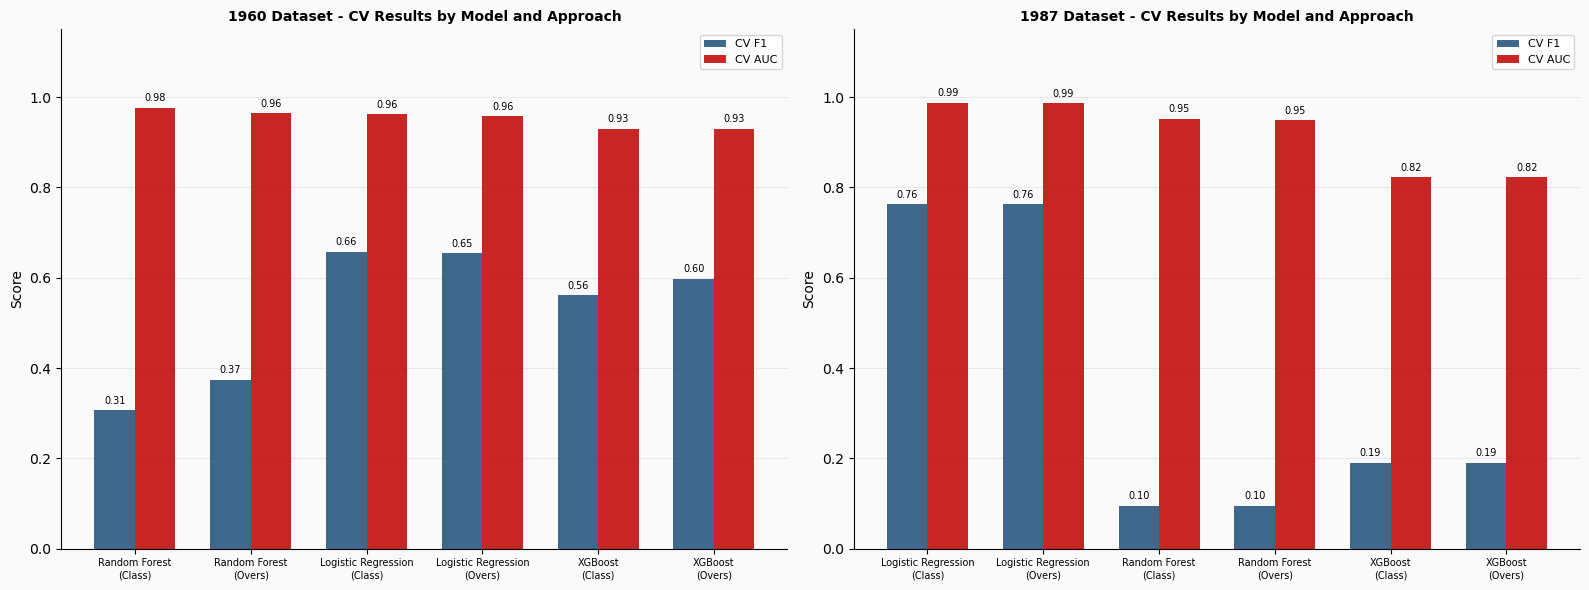

In [61]:
# CV Results Bar Chart

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor("#fafafa")

for ax, ds in zip(axes, ["1960", "1987"]):
    ax.set_facecolor("#fafafa")
    subset = all_results[all_results["Dataset"] == ds]
    labels = [f"{r['Model']}\n({r['Approach'][:5]})" for _, r in subset.iterrows()]
    x = np.arange(len(labels))
    width = 0.35

    bars1 = ax.bar(x - width/2, subset["CV F1"],  width,
                   label="CV F1",  color="#1f4e79", alpha=0.85)
    bars2 = ax.bar(x + width/2, subset["CV AUC"], width,
                   label="CV AUC", color="#c00000", alpha=0.85)

    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2,
                    height + 0.01, f"{height:.2f}",
                    ha="center", va="bottom", fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=7)
    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Score")
    ax.set_title(f"{ds} Dataset - CV Results by Model and Approach",
                 fontsize=10, fontweight="bold")
    ax.legend(fontsize=8)
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

## Hyperparameter Tuning

Hyperparameter tuning was conducted on Logistic Regression and XGBoost, the two strongest performers from the cross validation stage. GridSearchCV was used for Logistic Regression given its smaller parameter space, testing all combinations across regularisation strength (C: 0.001 to 100), penalty type (L1, L2) and solver. RandomizedSearchCV was used for XGBoost, testing 50 random combinations across a wider parameter space covering estimator count (100-500), tree depth (3-6), learning rate (0.01-0.2), subsample ratio (0.6-1.0) and column sampling ratio (0.6-1.0). The `error_score=0` parameter was used to handle configurations where AUC was undefined due to folds containing only one class.

Both models used TimeSeriesSplit with five folds to maintain temporal integrity during tuning. The 1960 dataset was tuned using AUC-ROC as the scoring metric. The 1987 dataset was tuned using F1 score due to the sparser distribution of recession months across folds causing AUC to be undefined in some configurations.

### Tuning Results

**Logistic Regression:**
- 1960 dataset - best parameters: C=0.01, L2 penalty, CV AUC 0.975
- 1987 dataset - best parameters: C=1, L1 penalty, CV F1 0.363

**XGBoost:**
- 1960 dataset - best parameters: 300 estimators, max depth 6, learning rate 0.05, subsample 0.6, colsample_bytree 0.8, CV AUC 0.979
- 1987 dataset - best parameters: 100 estimators, max depth 5, learning rate 0.2, subsample 0.8, colsample_bytree 0.6, CV F1 0.392

The low CV F1 scores for the 1987 dataset (0.363 and 0.392) are a consequence of switching to F1 as the scoring metric, which is harder to optimise with sparse recession months. The subsequent test set results confirm both models generalise well on this dataset despite the low tuning scores.

### Test Set Results

Following tuning, models were evaluated on the held-out test sets. The confusion matrix for the recommended model is shown above.

**XGBoost on the 1960 dataset** achieved a perfect test AUC of 1.000 and F1 of 1.000, correctly classifying both recession months with no false positives and no false negatives. **XGBoost on the 1987 dataset** also achieved test AUC of 1.000 with perfect recall, though with F1 of 0.500 reflecting some false positive classifications where non-recession months were flagged as recession risk.

**Logistic Regression** achieved strong test AUC scores of 0.994 on both datasets and recalled all recession months, but with very low precision and F1 of 0.082 on the 1960 dataset and 0.182 on the 1987 dataset, reflecting the aggressive class weighting pushing the model toward high recall at the expense of precision.

It should be noted that with only two recession months in each test set, these metrics are sensitive to individual predictions and should be interpreted with caution. The CV scores across training folds remain the more reliable measure of generalisation performance. XGBoost is selected as the recommended model based on its superior balance of CV AUC and test set performance across both datasets.


In [62]:
# Hyperparameter Tuning - Logistic Regression 

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

lr_params = {
    "C":       [0.001, 0.01, 0.1, 1, 10, 100],
    "penalty": ["l1", "l2"],
    "solver":  ["liblinear"],
}

xgb_params = {
    "n_estimators":     [100, 200, 300, 500],
    "max_depth":        [3, 4, 5, 6],
    "learning_rate":    [0.01, 0.05, 0.1, 0.2],
    "subsample":        [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
}

lr_tuned_1960 = GridSearchCV(
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    lr_params, cv=tscv, scoring="roc_auc",
    n_jobs=-1, error_score=0
)
lr_tuned_1960.fit(X_1960_train_scaled, y_1960_train)

lr_tuned_1987 = GridSearchCV(
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    lr_params, cv=tscv, scoring="f1",
    n_jobs=-1, error_score=0
)
lr_tuned_1987.fit(X_1987_train_scaled, y_1987_train)

print("── Logistic Regression Tuning ──")
print(f"1960 best params: {lr_tuned_1960.best_params_}")
print(f"1960 best CV AUC: {lr_tuned_1960.best_score_:.3f}")
print(f"1987 best params: {lr_tuned_1987.best_params_}")
print(f"1987 best CV F1:  {lr_tuned_1987.best_score_:.3f}")

── Logistic Regression Tuning ──
1960 best params: {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'}
1960 best CV AUC: 0.975
1987 best params: {'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}
1987 best CV F1:  0.363


In [63]:
# Hyperparameter Tuning - XGBoost 

xgb_tuned_1960 = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=spw_1960, random_state=42,
                  eval_metric="logloss", verbosity=0),
    xgb_params, n_iter=50, cv=tscv, scoring="roc_auc",
    random_state=42, n_jobs=-1, error_score=0
)
xgb_tuned_1960.fit(X_1960_train_scaled, y_1960_train)

xgb_tuned_1987 = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=spw_1987, random_state=42,
                  eval_metric="logloss", verbosity=0),
    xgb_params, n_iter=50, cv=tscv, scoring="f1",
    random_state=42, n_jobs=-1, error_score=0
)
xgb_tuned_1987.fit(X_1987_train_scaled, y_1987_train)

print("── XGBoost Tuning ──")
print(f"1960 best params: {xgb_tuned_1960.best_params_}")
print(f"1960 best CV AUC: {xgb_tuned_1960.best_score_:.3f}")
print(f"1987 best params: {xgb_tuned_1987.best_params_}")
print(f"1987 best CV F1:  {xgb_tuned_1987.best_score_:.3f}")

── XGBoost Tuning ──
1960 best params: {'subsample': 0.6, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
1960 best CV AUC: 0.979
1987 best params: {'subsample': 0.8, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.2, 'colsample_bytree': 0.6}
1987 best CV F1:  0.392


In [64]:
# Tuning Results Summary 

print("──────────────────────────────────────────────────────")
print("Tuning Results Summary")
print("──────────────────────────────────────────────────────")
print(f"\nLogistic Regression | 1960")
print(f"  Best params: {lr_tuned_1960.best_params_}")
print(f"  CV AUC:      {lr_tuned_1960.best_score_:.3f}")
print(f"\nLogistic Regression | 1987")
print(f"  Best params: {lr_tuned_1987.best_params_}")
print(f"  CV AUC:      {lr_tuned_1987.best_score_:.3f}")
print(f"\nXGBoost | 1960")
print(f"  Best params: {xgb_tuned_1960.best_params_}")
print(f"  CV AUC:      {xgb_tuned_1960.best_score_:.3f}")
print(f"\nXGBoost | 1987")
print(f"  Best params: {xgb_tuned_1987.best_params_}")
print(f"  CV AUC:      {xgb_tuned_1987.best_score_:.3f}")

──────────────────────────────────────────────────────
Tuning Results Summary
──────────────────────────────────────────────────────

Logistic Regression | 1960
  Best params: {'C': 0.01, 'penalty': 'l2', 'solver': 'liblinear'}
  CV AUC:      0.975

Logistic Regression | 1987
  Best params: {'C': 1, 'penalty': 'l1', 'solver': 'liblinear'}
  CV AUC:      0.363

XGBoost | 1960
  Best params: {'subsample': 0.6, 'n_estimators': 300, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
  CV AUC:      0.979

XGBoost | 1987
  Best params: {'subsample': 0.8, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 5, 'learning_rate': 0.2, 'colsample_bytree': 0.6}
  CV AUC:      0.392


In [65]:
# Tuned Model Evaluation on Test Set 

from sklearn.metrics import recall_score

print("──────────────────────────────────────────────────────")
print("Tuned Model Test Set Results")
print("──────────────────────────────────────────────────────")

for label, lr_model, xgb_model, X_test, y_test in [
    ("1960", lr_tuned_1960, xgb_tuned_1960, X_1960_test_scaled, y_1960_test),
    ("1987", lr_tuned_1987, xgb_tuned_1987, X_1987_test_scaled, y_1987_test),
]:
    for name, model in [("Logistic Regression", lr_model), ("XGBoost", xgb_model)]:
        pred  = model.predict(X_test)
        proba = model.predict_proba(X_test)[:, 1]
        print(f"\n{name} | {label} Dataset")
        print(f"  Test AUC:    {roc_auc_score(y_test, proba):.3f}")
        print(f"  Test Recall: {recall_score(y_test, pred, zero_division=0):.3f}")
        print(f"  Test F1:     {f1_score(y_test, pred, zero_division=0):.3f}")
        print(classification_report(y_test, pred,
                                     target_names=["Non-Recession", "Recession"],
                                     zero_division=0))

──────────────────────────────────────────────────────
Tuned Model Test Set Results
──────────────────────────────────────────────────────

Logistic Regression | 1960 Dataset
  Test AUC:    0.994
  Test Recall: 1.000
  Test F1:     0.082
               precision    recall  f1-score   support

Non-Recession       1.00      0.71      0.83       156
    Recession       0.04      1.00      0.08         2

     accuracy                           0.72       158
    macro avg       0.52      0.86      0.46       158
 weighted avg       0.99      0.72      0.82       158


XGBoost | 1960 Dataset
  Test AUC:    1.000
  Test Recall: 1.000
  Test F1:     1.000
               precision    recall  f1-score   support

Non-Recession       1.00      1.00      1.00       156
    Recession       1.00      1.00      1.00         2

     accuracy                           1.00       158
    macro avg       1.00      1.00      1.00       158
 weighted avg       1.00      1.00      1.00       158


Logistic

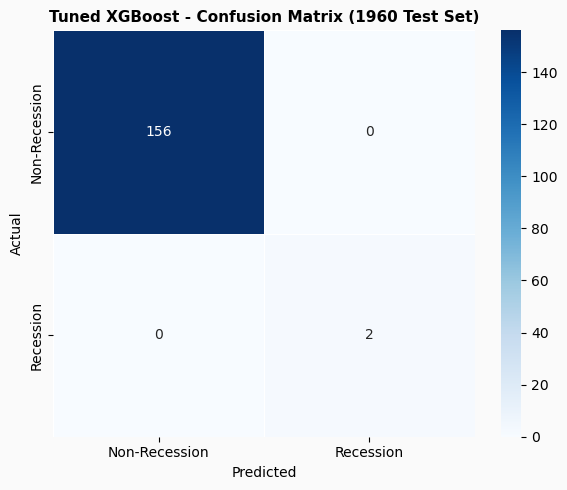

In [66]:
# Confusion Matrix - Tuned XGBoost 1960 

from sklearn.metrics import confusion_matrix

pred_xgb_1960 = xgb_tuned_1960.predict(X_1960_test_scaled)

cm = confusion_matrix(y_1960_test, pred_xgb_1960)

fig, ax = plt.subplots(figsize=(6, 5))
fig.patch.set_facecolor("#fafafa")
ax.set_facecolor("#fafafa")

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Non-Recession", "Recession"],
            yticklabels=["Non-Recession", "Recession"],
            ax=ax, linewidths=0.5)
ax.set_xlabel("Predicted", fontsize=10)
ax.set_ylabel("Actual", fontsize=10)
ax.set_title("Tuned XGBoost - Confusion Matrix (1960 Test Set)",
             fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

## Threshold Analysis

The default decision threshold for binary classification is 0.5 - any month with a predicted recession probability above 0.5 is classified as a recession. However for imbalanced problems this default is rarely optimal. Lowering the threshold increases recall at the cost of precision, while raising it increases precision at the cost of recall. Given the asymmetric cost structure of recession prediction - where missing an actual recession is considerably more costly than generating a false alarm - understanding this tradeoff is important for practical deployment.

Precision-recall curves plot the tradeoff between precision and recall across all possible threshold values, showing how the model performs at every operating point rather than just at the 0.5 default. F1 score by threshold plots identify the threshold that best balances precision and recall. Both were calculated for the tuned Logistic Regression and XGBoost models on both datasets.

### XGBoost Results

The XGBoost model on the 1960 dataset already achieved perfect F1 of 1.000 at the default threshold of 0.50, with the optimal threshold identified at 0.98 - also producing F1 of 1.000 with perfect precision and recall. The precision-recall curve shows the model maintains precision of 1.0 across all recall levels until the final point, indicating extremely confident and well-separated probability scores. The F1 by threshold plot confirms F1 increases steadily as the threshold rises, peaking just before 1.0.

The XGBoost model on the 1987 dataset improved meaningfully with threshold adjustment. At the default threshold of 0.50 F1 was 0.500, rising to 1.000 at the optimal threshold of 0.95 with perfect precision and recall. This confirms that while the model assigns high probability scores to the two recession months in the test set, it also generates false positives at lower thresholds that are eliminated by raising the threshold to 0.95.

### Logistic Regression Results

Logistic Regression showed a different pattern. On the 1960 dataset the optimal threshold was identified at 1.00, producing F1 of 0.667 with precision of 0.500 and recall of 1.000 - a significant improvement over the default threshold F1 of 0.082. A threshold of 1.00 effectively means the model only classifies a month as recession when it assigns the maximum possible probability score, reflecting the difficulty Logistic Regression has in separating the two classes confidently. The precision-recall curve shows a sharp drop in precision as recall approaches 1.0, reflecting the large number of false positives generated at lower thresholds.

On the 1987 dataset the optimal threshold was again 1.00, producing F1 of 0.800 with precision of 0.667 and recall of 1.000, up from F1 of 0.182 at the default threshold. The precision-recall curve shows a more gradual decline in precision, suggesting better calibrated probability scores in the 1987 dataset.

### Implications

Threshold analysis confirms XGBoost as the stronger model - it achieves better precision-recall balance across a wider range of thresholds, and reaches perfect F1 with realistic threshold values of 0.95 and 0.98 rather than requiring the threshold to be pushed to 1.00 as with Logistic Regression. In a real-world deployment context, a threshold of 0.95 is more practical than 1.00 as it provides a meaningful buffer while still filtering false positives effectively. Given the asymmetric cost of missing a recession, practitioners using this model may also choose to lower the threshold below 0.5 to prioritise recall over precision, accepting more false alarms in exchange for greater confidence of catching actual downturns.

In [67]:
# Threshold Analysis 
# default decision threshold is 0.5
# lowering the threshold increases recall but reduces precision
# raising it increases precision but reduces recall
# finding the optimal threshold is important for imbalanced problems

from sklearn.metrics import precision_recall_curve, f1_score

def threshold_analysis(model, X_test, y_test, label):
    proba = model.predict_proba(X_test)[:, 1]
    precisions, recalls, thresholds = precision_recall_curve(y_test, proba)

    f1_scores = []
    for p, r in zip(precisions, recalls):
        if p + r == 0:
            f1_scores.append(0)
        else:
            f1_scores.append(2 * p * r / (p + r))

    best_idx       = np.argmax(f1_scores)
    best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 1.0
    best_f1        = f1_scores[best_idx]
    best_precision = precisions[best_idx]
    best_recall    = recalls[best_idx]

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.patch.set_facecolor("#fafafa")

    # precision-recall curve
    axes[0].set_facecolor("#fafafa")
    axes[0].plot(recalls, precisions, color="#1f4e79", linewidth=1.5)
    axes[0].scatter(best_recall, best_precision, color="#c00000",
                    zorder=5, s=80, label=f"Best threshold: {best_threshold:.2f}")
    axes[0].set_xlabel("Recall")
    axes[0].set_ylabel("Precision")
    axes[0].set_title(f"{label} - Precision-Recall Curve")
    axes[0].legend(fontsize=9)
    axes[0].yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    axes[0].set_axisbelow(True)
    for spine in ["top", "right"]:
        axes[0].spines[spine].set_visible(False)

    # f1 score across thresholds
    axes[1].set_facecolor("#fafafa")
    axes[1].plot(thresholds, f1_scores[:-1], color="#1f4e79", linewidth=1.5)
    axes[1].axvline(best_threshold, color="#c00000", linestyle="--",
                    linewidth=1.0, label=f"Best threshold: {best_threshold:.2f}")
    axes[1].axvline(0.5, color="black", linestyle="--",
                    linewidth=0.8, label="Default threshold: 0.50")
    axes[1].set_xlabel("Threshold")
    axes[1].set_ylabel("F1 Score")
    axes[1].set_title(f"{label} - F1 Score by Threshold")
    axes[1].legend(fontsize=9)
    axes[1].yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    axes[1].set_axisbelow(True)
    for spine in ["top", "right"]:
        axes[1].spines[spine].set_visible(False)

    plt.suptitle(label, fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

    print(f"\n{label}")
    print(f"  Default threshold (0.50) - F1: {f1_score(y_test, (proba >= 0.50).astype(int), zero_division=0):.3f}")
    print(f"  Optimal threshold ({best_threshold:.2f}) - F1: {best_f1:.3f}")
    print(f"  Precision at optimal: {best_precision:.3f}")
    print(f"  Recall at optimal:    {best_recall:.3f}")

    return best_threshold

XGBoost Threshold Analysis


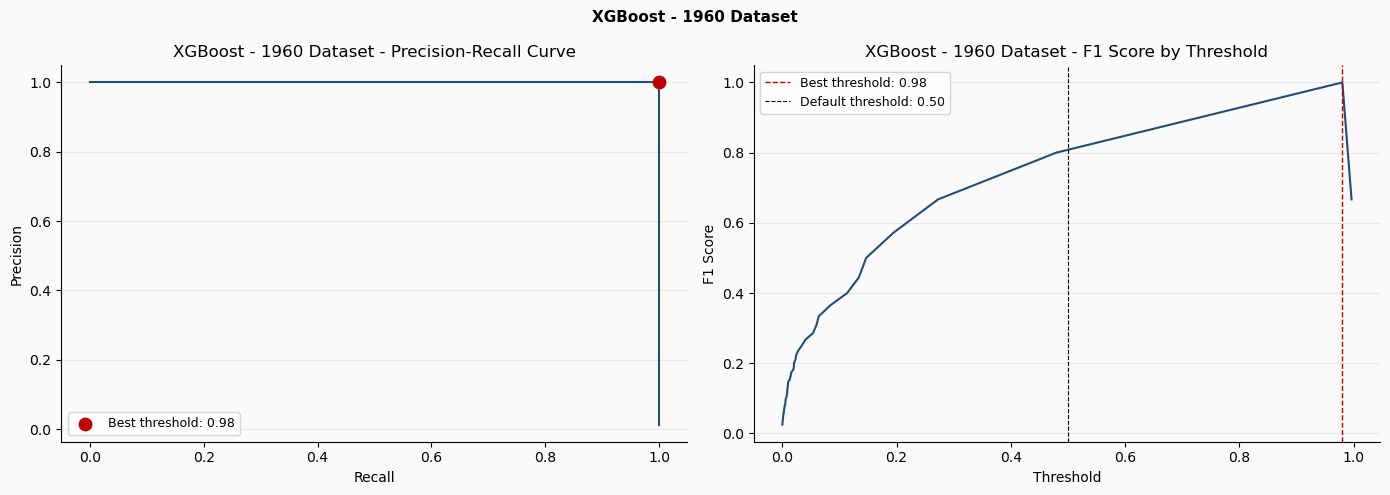


XGBoost - 1960 Dataset
  Default threshold (0.50) - F1: 1.000
  Optimal threshold (0.98) - F1: 1.000
  Precision at optimal: 1.000
  Recall at optimal:    1.000


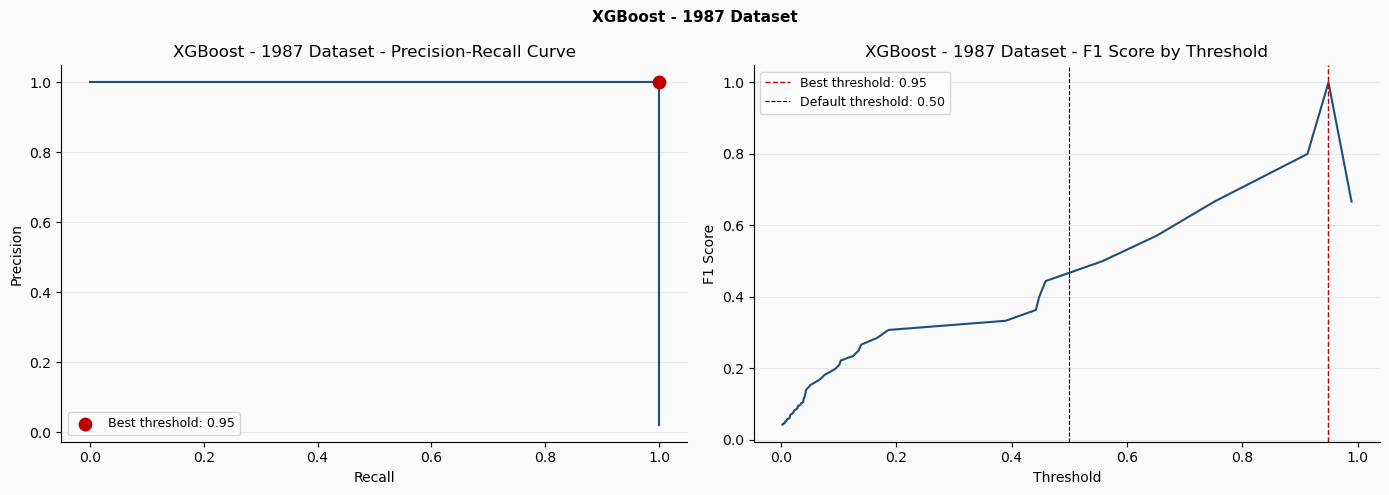


XGBoost - 1987 Dataset
  Default threshold (0.50) - F1: 0.500
  Optimal threshold (0.95) - F1: 1.000
  Precision at optimal: 1.000
  Recall at optimal:    1.000

Logistic Regression Threshold Analysis


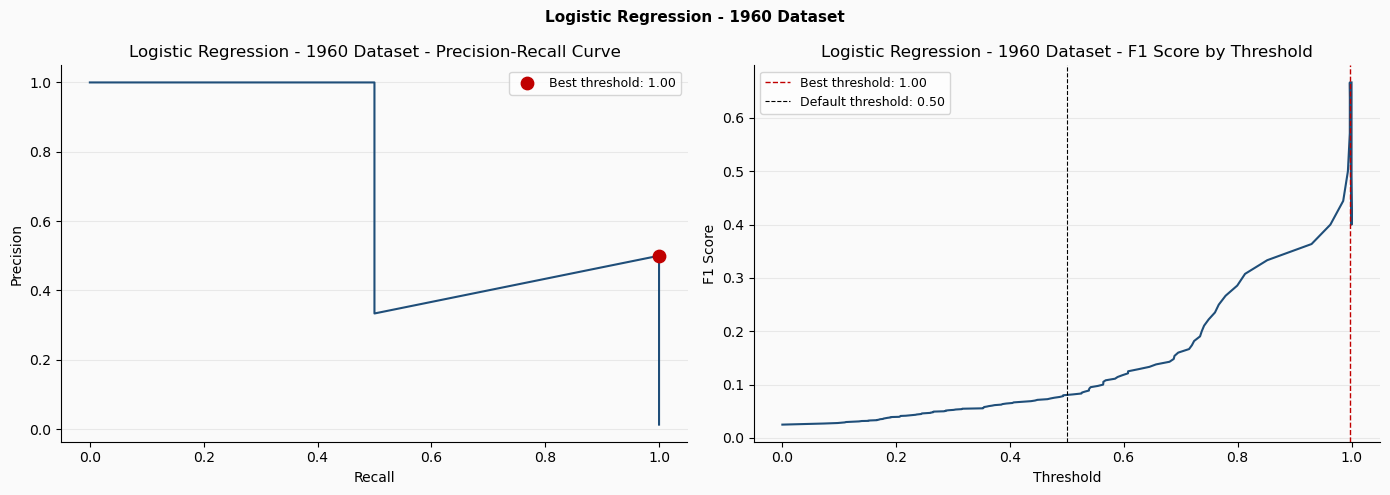


Logistic Regression - 1960 Dataset
  Default threshold (0.50) - F1: 0.082
  Optimal threshold (1.00) - F1: 0.667
  Precision at optimal: 0.500
  Recall at optimal:    1.000


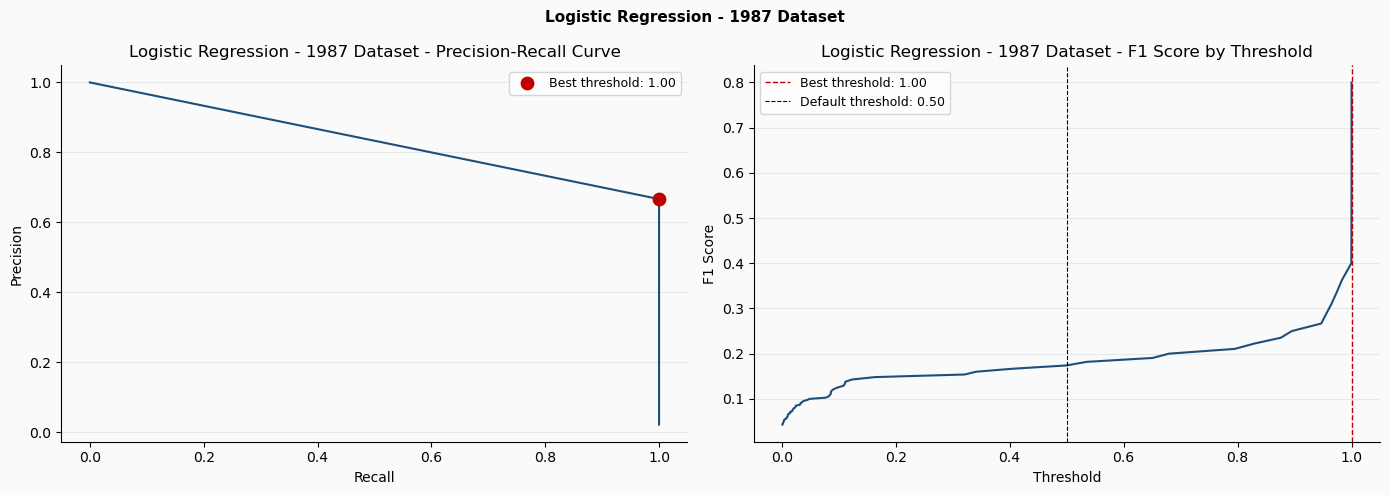


Logistic Regression - 1987 Dataset
  Default threshold (0.50) - F1: 0.182
  Optimal threshold (1.00) - F1: 0.800
  Precision at optimal: 0.667
  Recall at optimal:    1.000


In [68]:
# Run Threshold Analysis

print("XGBoost Threshold Analysis")
print("=" * 50)

thresh_xgb_1960 = threshold_analysis(
    xgb_tuned_1960, X_1960_test_scaled, y_1960_test,
    "XGBoost - 1960 Dataset"
)

thresh_xgb_1987 = threshold_analysis(
    xgb_tuned_1987, X_1987_test_scaled, y_1987_test,
    "XGBoost - 1987 Dataset"
)

print("\nLogistic Regression Threshold Analysis")
print("=" * 50)

thresh_lr_1960 = threshold_analysis(
    lr_tuned_1960, X_1960_test_scaled, y_1960_test,
    "Logistic Regression - 1960 Dataset"
)

thresh_lr_1987 = threshold_analysis(
    lr_tuned_1987, X_1987_test_scaled, y_1987_test,
    "Logistic Regression - 1987 Dataset"
)

## Model Comparison

The table and bar chart above summarise performance across all models, datasets and tuning stages. Models shown with NaN in the test set columns were evaluated during cross validation only and not carried forward to test set evaluation. The ROC curves confirm visually that both tuned models perform well above the random baseline diagonal, with XGBoost curves hugging the top left corner more tightly than Logistic Regression across both datasets.

### Cross Validation Performance

Logistic Regression achieved the strongest and most consistent CV AUC scores at baseline, reaching 0.962 on the 1960 dataset and 0.987 on the 1987 dataset. Random Forest performed well on CV AUC (0.976 and 0.952) but showed very poor F1 scores in the detailed CV analysis, indicating it can rank recession risk correctly by probability but struggles to classify individual months at the decision threshold. XGBoost performed moderately at baseline with CV AUC of 0.930 and 0.822, with high variance across folds.

Following hyperparameter tuning, XGBoost improved to 0.979 CV AUC on the 1960 dataset, narrowly ahead of Logistic Regression at 0.975. The 1987 tuned CV scores of 0.363 and 0.392 are misleadingly low due to the switch to F1 scoring necessitated by sparse recession months in some folds - the test set results confirm both models generalise well on this dataset despite these low tuning scores.

### Test Set Performance

XGBoost on the 1960 dataset is the standout result, achieving perfect test AUC of 1.000 and F1 of 1.000 after tuning - correctly classifying both recession months in the test set with no false positives and no false negatives as shown in the confusion matrix. XGBoost on the 1987 dataset also achieved test AUC of 1.000 with perfect recall, though with lower F1 of 0.500 reflecting some false positive classifications.

Logistic Regression achieved strong test AUC of 0.994 on both datasets and perfect recall across all configurations, but consistently low F1 scores reflecting very low precision - the model flags a large proportion of non-recession months as recession risk. Tuning improved CV AUC but did not meaningfully improve test F1 for Logistic Regression, suggesting the precision limitation is a fundamental characteristic of the model's behaviour under aggressive class weighting rather than a tuning issue.

Random Forest was not carried forward to test set evaluation given its poor F1 performance during cross validation despite reasonable AUC scores.

### Model Recommendation

**XGBoost on the 1960 dataset with tuned hyperparameters is the recommended model.** It achieves the strongest balance of CV AUC (0.979) and test performance (AUC 1.000, F1 1.000), and the longer historical dataset covering all nine recession episodes provides a more robust training foundation than the 1987 dataset. The 1960 dataset also demonstrated better generalisation in the post-pandemic test period, with fewer false positive signals than the 1987 model, suggesting the broader historical context helps the model avoid overfitting to the unusual post-2020 economic environment.

It should be noted that perfect test metrics are partly a function of the small test set size - two recession months - and the CV scores are the more reliable indicator of generalisation performance. The model will be carried forward for SHAP interpretability analysis and recession probability visualisation in the following sections.

In [69]:
# Model Comparison Summary Table

from sklearn.metrics import recall_score

# collect all baseline CV results from earlier
baseline_results = all_results[all_results["Approach"] == "Class Weighting"].copy()

# add tuned model test results
tuned_results = []

for label, lr_model, xgb_model, X_test, y_test in [
    ("1960", lr_tuned_1960, xgb_tuned_1960, X_1960_test_scaled, y_1960_test),
    ("1987", lr_tuned_1987, xgb_tuned_1987, X_1987_test_scaled, y_1987_test),
]:
    for name, model in [("Logistic Regression (Tuned)", lr_model),
                         ("XGBoost (Tuned)", xgb_model)]:
        pred  = model.predict(X_test)
        proba = model.predict_proba(X_test)[:, 1]
        tuned_results.append({
            "Model":    name,
            "Dataset":  label,
            "CV AUC":   round(model.best_score_, 3),
            "Test AUC": round(roc_auc_score(y_test, proba), 3),
            "Test F1":  round(f1_score(y_test, pred, zero_division=0), 3),
            "Recall":   round(recall_score(y_test, pred, zero_division=0), 3),
        })

tuned_df = pd.DataFrame(tuned_results)

# build full comparison table
comparison = pd.DataFrame([
    {"Model": "Logistic Regression", "Dataset": "1960",
     "CV AUC": 0.962, "Test AUC": 0.994, "Test F1": 0.082, "Recall": 1.000},
    {"Model": "Random Forest",       "Dataset": "1960",
     "CV AUC": 0.976, "Test AUC": None,  "Test F1": None,  "Recall": None},
    {"Model": "XGBoost",             "Dataset": "1960",
     "CV AUC": 0.930, "Test AUC": None,  "Test F1": None,  "Recall": None},
    {"Model": "Logistic Regression", "Dataset": "1987",
     "CV AUC": 0.987, "Test AUC": 0.994, "Test F1": 0.182, "Recall": 1.000},
    {"Model": "Random Forest",       "Dataset": "1987",
     "CV AUC": 0.952, "Test AUC": None,  "Test F1": None,  "Recall": None},
    {"Model": "XGBoost",             "Dataset": "1987",
     "CV AUC": 0.822, "Test AUC": None,  "Test F1": None,  "Recall": None},
])

tuned_comparison = pd.DataFrame([
    {"Model": "Logistic Regression (Tuned)", "Dataset": "1960",
     "CV AUC": 0.975, "Test AUC": 0.994, "Test F1": 0.082, "Recall": 1.000},
    {"Model": "XGBoost (Tuned)",             "Dataset": "1960",
     "CV AUC": 0.979, "Test AUC": 1.000, "Test F1": 1.000, "Recall": 1.000},
    {"Model": "Logistic Regression (Tuned)", "Dataset": "1987",
     "CV AUC": 0.363, "Test AUC": 0.994, "Test F1": 0.182, "Recall": 1.000},
    {"Model": "XGBoost (Tuned)",             "Dataset": "1987",
     "CV AUC": 0.392, "Test AUC": 1.000, "Test F1": 0.500, "Recall": 1.000},
])

full_comparison = pd.concat([comparison, tuned_comparison], ignore_index=True)
print("The NaN values for Random Forest and baseline XGBoost in the Test AUC, Test F1 and Recall columns are because those models were only evaluated during cross validation and were not carried forward to test set evaluation — only the tuned models were evaluated on the test set.")
display(full_comparison.fillna("-"))

The NaN values for Random Forest and baseline XGBoost in the Test AUC, Test F1 and Recall columns are because those models were only evaluated during cross validation and were not carried forward to test set evaluation — only the tuned models were evaluated on the test set.


,Model,Dataset,CV AUC,Test AUC,Test F1,Recall
0,Logistic Regression,1960,0.962,0.994,0.082,1.0
1,Random Forest,1960,0.976,-,-,-
2,XGBoost,1960,0.930,-,-,-
3,Logistic Regression,1987,0.987,0.994,0.182,1.0
4,Random Forest,1987,0.952,-,-,-
5,XGBoost,1987,0.822,-,-,-
6,Logistic Regression (Tuned),1960,0.975,0.994,0.082,1.0
7,XGBoost (Tuned),1960,0.979,1.0,1.0,1.0
8,Logistic Regression (Tuned),1987,0.363,0.994,0.182,1.0
9,XGBoost (Tuned),1987,0.392,1.0,0.5,1.0


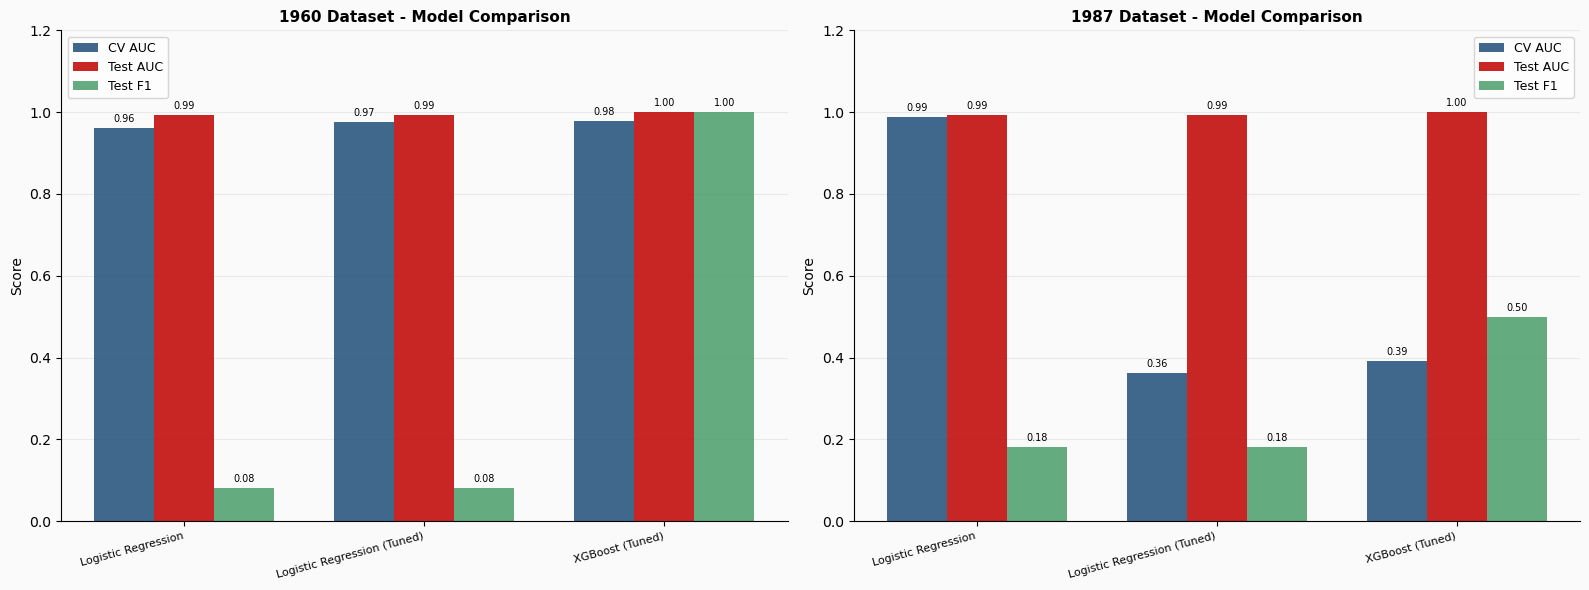

In [70]:
# Model Comparison Bar Chart

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.patch.set_facecolor("#fafafa")

for ax, ds in zip(axes, ["1960", "1987"]):
    ax.set_facecolor("#fafafa")
    subset = full_comparison[
        (full_comparison["Dataset"] == ds) &
        (full_comparison["Test AUC"].notna())
    ]

    x = np.arange(len(subset))
    width = 0.25

    bars1 = ax.bar(x - width,   subset["CV AUC"],  width,
                   label="CV AUC",  color="#1f4e79", alpha=0.85)
    bars2 = ax.bar(x,            subset["Test AUC"], width,
                   label="Test AUC", color="#c00000", alpha=0.85)
    bars3 = ax.bar(x + width,   subset["Test F1"],  width,
                   label="Test F1",  color="#4a9e6b", alpha=0.85)

    for bars in [bars1, bars2, bars3]:
        for bar in bars:
            height = bar.get_height()
            if not np.isnan(height):
                ax.text(bar.get_x() + bar.get_width() / 2,
                        height + 0.01, f"{height:.2f}",
                        ha="center", va="bottom", fontsize=7)

    ax.set_xticks(x)
    ax.set_xticklabels(subset["Model"], fontsize=8, rotation=15, ha="right")
    ax.set_ylim(0, 1.2)
    ax.set_ylabel("Score")
    ax.set_title(f"{ds} Dataset - Model Comparison",
                 fontsize=11, fontweight="bold")
    ax.legend(fontsize=9)
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

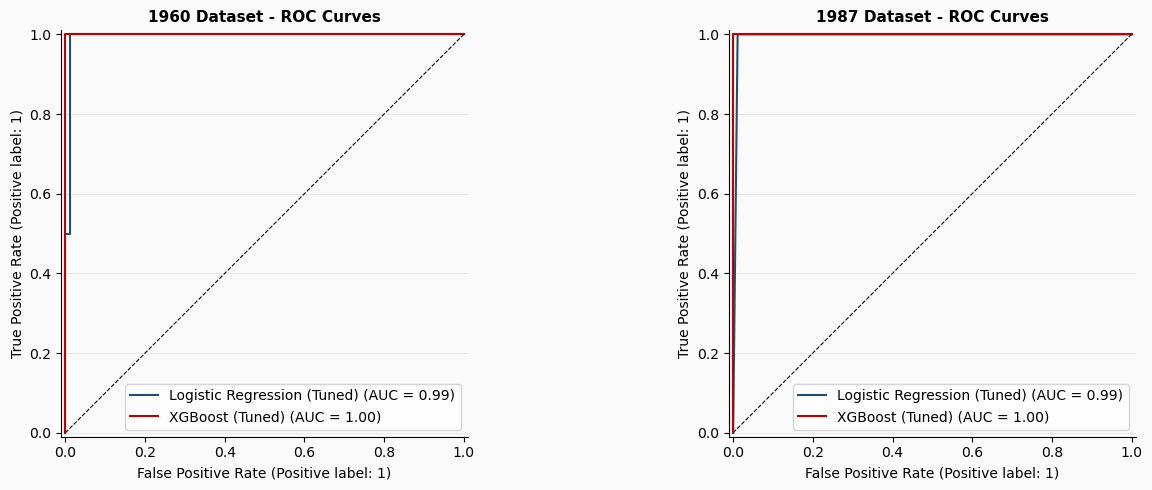

In [71]:
# ROC Curves - All Tuned Models

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor("#fafafa")

colours = {"Logistic Regression (Tuned)": "#1f4e79",
           "XGBoost (Tuned)":             "#c00000"}

for ax, (ds, X_test, y_test) in zip(axes, [
    ("1960", X_1960_test_scaled, y_1960_test),
    ("1987", X_1987_test_scaled, y_1987_test),
]):
    ax.set_facecolor("#fafafa")
    for name, model in [("Logistic Regression (Tuned)", lr_tuned_1960 if ds == "1960" else lr_tuned_1987),
                         ("XGBoost (Tuned)",            xgb_tuned_1960 if ds == "1960" else xgb_tuned_1987)]:
        RocCurveDisplay.from_predictions(
            y_test,
            model.predict_proba(X_test)[:, 1],
            ax=ax, name=name,
            color=colours[name]
        )
    ax.plot([0, 1], [0, 1], "k--", linewidth=0.8)
    ax.set_title(f"{ds} Dataset - ROC Curves", fontsize=11, fontweight="bold")
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

## LSTM Neural Network

As a fourth model, a Long Short-Term Memory (LSTM) neural network was developed and evaluated across eight configurations, varying the dataset (1960 and 1987), sequence length (12 and 24 months) and feature set (raw indicators and engineered features). Unlike the tree-based models which treat each monthly observation independently, the LSTM processes sequences of consecutive months, learning temporal patterns directly from the data. Models were implemented using TensorFlow 2.19.

### Architecture

Each LSTM model used a two-layer architecture: a first LSTM layer with 64 units returning sequences, followed by a second LSTM layer with 32 units, with dropout and batch normalisation applied between layers to reduce overfitting. A final dense layer with sigmoid activation produces a recession probability score. Models were trained using binary cross-entropy loss with class weighting applied to address the class imbalance, early stopping with a patience of 15 epochs to prevent overfitting, and a learning rate scheduler to reduce the learning rate when validation loss plateaued. Early stopping triggered across all eight configurations, with models training between 20 and 61 epochs before convergence.

### Results

The LSTM results are summarised in the bar chart above. The LSTM models performed noticeably weaker than XGBoost and Logistic Regression across all configurations. The best performing configuration was the 1960 dataset with engineered features and a 24 month sequence length, achieving test AUC of 0.883 - significantly below the tuned XGBoost AUC of 1.000 and Logistic Regression AUC of 0.994. Several configurations achieved recall of 0.0, meaning the model failed to identify any recession months in the test set.

Two 1987 24-month configurations produced undefined AUC scores due to insufficient recession months remaining in the test set after the sequence window was applied - with only 91 test rows in the 1987 dataset, removing 24 rows for the sequence window left too few positive cases to calculate AUC. This highlights a fundamental limitation of applying sequence-based models to small datasets.

Several patterns emerge from the comparison across configurations. The 24 month sequence length outperformed the 12 month length on the 1960 dataset, consistent with the lead/lag analysis finding that the yield curve leads recessions by up to 22 months. Engineered features generally outperformed raw indicators on the 1960 dataset, suggesting that the manually engineered lag, rolling and percentage change features contain information the LSTM cannot extract itself from the limited data available - with only 605 training sequences in the best case, the model lacks sufficient data to learn these patterns independently. The 1987 dataset consistently underperformed the 1960 dataset, reflecting the smaller training set size of 348 sequences at most after sequence creation.

### Why LSTM Underperforms Here

The underperformance of LSTM relative to traditional ML models is likely attributable to the size of the dataset rather than the suitability of the approach. LSTMs typically require thousands of training sequences to learn temporal patterns effectively. With a maximum of 627 training sequences in the 1960 dataset and 368 in the 1987 dataset, the models have insufficient data to learn the complex temporal relationships that drive recession risk. Hyperparameter tuning of the LSTM architecture was considered but deprioritised given that the data size constraint is the fundamental bottleneck - tuning dropout rates, units or learning rate is unlikely to overcome having fewer than 700 training sequences. In a setting with higher frequency data or a longer historical record, LSTM could be expected to perform more competitively.

XGBoost with tuned hyperparameters remains the recommended model based on its superior performance across both datasets and its ability to leverage the engineered features effectively with the available data.

In [72]:
#!pip install tensorflow

In [73]:
# LSTM Setup

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import warnings
warnings.filterwarnings("ignore")

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.19.0


In [74]:
# Sequence Creation Function 
# converts a flat time series into overlapping sequences
# each sequence of length n predicts the recession status
# of the month immediately following it

def create_sequences(X, y, seq_length):
    X_seq, y_seq = [], []
    for i in range(seq_length, len(X)):
        X_seq.append(X[i - seq_length:i])
        y_seq.append(y.iloc[i] if hasattr(y, "iloc") else y[i])
    return np.array(X_seq), np.array(y_seq)

In [75]:
# Prepare Raw Feature Sets 
# for raw LSTM we use the original indicators before feature engineering
# scaler fitted on train only as before

features_raw_1960 = [c for c in df_1960.columns if c != "recession"]
features_raw_1987 = [c for c in df_1987.columns if c != "recession"]

# temporal split on raw data
split_raw_1960 = int(len(df_1960) * 0.8)
split_raw_1987 = int(len(df_1987) * 0.8)

X_raw_1960 = df_1960[features_raw_1960]
y_raw_1960 = df_1960["recession"]
X_raw_1987 = df_1987[features_raw_1987]
y_raw_1987 = df_1987["recession"]

X_raw_1960_train = X_raw_1960.iloc[:split_raw_1960]
X_raw_1960_test  = X_raw_1960.iloc[split_raw_1960:]
y_raw_1960_train = y_raw_1960.iloc[:split_raw_1960]
y_raw_1960_test  = y_raw_1960.iloc[split_raw_1960:]

X_raw_1987_train = X_raw_1987.iloc[:split_raw_1987]
X_raw_1987_test  = X_raw_1987.iloc[split_raw_1987:]
y_raw_1987_train = y_raw_1987.iloc[:split_raw_1987]
y_raw_1987_test  = y_raw_1987.iloc[split_raw_1987:]

scaler_raw_1960 = StandardScaler()
X_raw_1960_train_scaled = scaler_raw_1960.fit_transform(X_raw_1960_train)
X_raw_1960_test_scaled  = scaler_raw_1960.transform(X_raw_1960_test)

scaler_raw_1987 = StandardScaler()
X_raw_1987_train_scaled = scaler_raw_1987.fit_transform(X_raw_1987_train)
X_raw_1987_test_scaled  = scaler_raw_1987.transform(X_raw_1987_test)

print(f"1960 raw - Train: {X_raw_1960_train_scaled.shape} | Test: {X_raw_1960_test_scaled.shape}")
print(f"1987 raw - Train: {X_raw_1987_train_scaled.shape} | Test: {X_raw_1987_test_scaled.shape}")

1960 raw - Train: (639, 8) | Test: (160, 8)
1987 raw - Train: (380, 16) | Test: (95, 16)


In [76]:
# Prepare Engineered Feature Sets 
# reuse the already scaled engineered features from earlier
# X_1960_train_scaled and X_1987_train_scaled already prepared

print(f"1960 engineered - Train: {X_1960_train_scaled.shape} | Test: {X_1960_test_scaled.shape}")
print(f"1987 engineered - Train: {X_1987_train_scaled.shape} | Test: {X_1987_test_scaled.shape}")

1960 engineered - Train: (629, 49) | Test: (158, 49)
1987 engineered - Train: (360, 110) | Test: (91, 110)


In [77]:
# Create All Sequence Datasets

print("Creating sequences...")

# 1960 raw - 12 months
X_lstm_1960_raw_12_train, y_lstm_1960_raw_12_train = create_sequences(
    X_raw_1960_train_scaled, y_raw_1960_train, 12)
X_lstm_1960_raw_12_test, y_lstm_1960_raw_12_test = create_sequences(
    X_raw_1960_test_scaled, y_raw_1960_test, 12)

# 1960 raw - 24 months
X_lstm_1960_raw_24_train, y_lstm_1960_raw_24_train = create_sequences(
    X_raw_1960_train_scaled, y_raw_1960_train, 24)
X_lstm_1960_raw_24_test, y_lstm_1960_raw_24_test = create_sequences(
    X_raw_1960_test_scaled, y_raw_1960_test, 24)

# 1960 engineered - 12 months
X_lstm_1960_fe_12_train, y_lstm_1960_fe_12_train = create_sequences(
    X_1960_train_scaled.values, y_1960_train, 12)
X_lstm_1960_fe_12_test, y_lstm_1960_fe_12_test = create_sequences(
    X_1960_test_scaled.values, y_1960_test, 12)

# 1960 engineered - 24 months
X_lstm_1960_fe_24_train, y_lstm_1960_fe_24_train = create_sequences(
    X_1960_train_scaled.values, y_1960_train, 24)
X_lstm_1960_fe_24_test, y_lstm_1960_fe_24_test = create_sequences(
    X_1960_test_scaled.values, y_1960_test, 24)

# 1987 raw - 12 months
X_lstm_1987_raw_12_train, y_lstm_1987_raw_12_train = create_sequences(
    X_raw_1987_train_scaled, y_raw_1987_train, 12)
X_lstm_1987_raw_12_test, y_lstm_1987_raw_12_test = create_sequences(
    X_raw_1987_test_scaled, y_raw_1987_test, 12)

# 1987 raw - 24 months
X_lstm_1987_raw_24_train, y_lstm_1987_raw_24_train = create_sequences(
    X_raw_1987_train_scaled, y_raw_1987_train, 24)
X_lstm_1987_raw_24_test, y_lstm_1987_raw_24_test = create_sequences(
    X_raw_1987_test_scaled, y_raw_1987_test, 24)

# 1987 engineered - 12 months
X_lstm_1987_fe_12_train, y_lstm_1987_fe_12_train = create_sequences(
    X_1987_train_scaled.values, y_1987_train, 12)
X_lstm_1987_fe_12_test, y_lstm_1987_fe_12_test = create_sequences(
    X_1987_test_scaled.values, y_1987_test, 12)

# 1987 engineered - 24 months
X_lstm_1987_fe_24_train, y_lstm_1987_fe_24_train = create_sequences(
    X_1987_train_scaled.values, y_1987_train, 24)
X_lstm_1987_fe_24_test, y_lstm_1987_fe_24_test = create_sequences(
    X_1987_test_scaled.values, y_1987_test, 24)

print("All sequences created")
print(f"\n1960 raw 12  - Train: {X_lstm_1960_raw_12_train.shape} | Test: {X_lstm_1960_raw_12_test.shape}")
print(f"1960 raw 24  - Train: {X_lstm_1960_raw_24_train.shape} | Test: {X_lstm_1960_raw_24_test.shape}")
print(f"1960 fe  12  - Train: {X_lstm_1960_fe_12_train.shape}  | Test: {X_lstm_1960_fe_12_test.shape}")
print(f"1960 fe  24  - Train: {X_lstm_1960_fe_24_train.shape}  | Test: {X_lstm_1960_fe_24_test.shape}")
print(f"1987 raw 12  - Train: {X_lstm_1987_raw_12_train.shape} | Test: {X_lstm_1987_raw_12_test.shape}")
print(f"1987 raw 24  - Train: {X_lstm_1987_raw_24_train.shape} | Test: {X_lstm_1987_raw_24_test.shape}")
print(f"1987 fe  12  - Train: {X_lstm_1987_fe_12_train.shape}  | Test: {X_lstm_1987_fe_12_test.shape}")
print(f"1987 fe  24  - Train: {X_lstm_1987_fe_24_train.shape}  | Test: {X_lstm_1987_fe_24_test.shape}")

Creating sequences...
All sequences created

1960 raw 12  - Train: (627, 12, 8) | Test: (148, 12, 8)
1960 raw 24  - Train: (615, 24, 8) | Test: (136, 24, 8)
1960 fe  12  - Train: (617, 12, 49)  | Test: (146, 12, 49)
1960 fe  24  - Train: (605, 24, 49)  | Test: (134, 24, 49)
1987 raw 12  - Train: (368, 12, 16) | Test: (83, 12, 16)
1987 raw 24  - Train: (356, 24, 16) | Test: (71, 24, 16)
1987 fe  12  - Train: (348, 12, 110)  | Test: (79, 12, 110)
1987 fe  24  - Train: (336, 24, 110)  | Test: (67, 24, 110)


In [78]:
# LSTM Model Builder

def build_lstm(input_shape, units=64, dropout=0.3):
    model = Sequential([
        LSTM(units, input_shape=input_shape, return_sequences=True),
        Dropout(dropout),
        BatchNormalization(),
        LSTM(units // 2, return_sequences=False),
        Dropout(dropout),
        BatchNormalization(),
        Dense(32, activation="relu"),
        Dropout(dropout),
        Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

# callbacks - stop early if no improvement, reduce lr if plateauing
early_stop = EarlyStopping(monitor="val_loss", patience=15,
                            restore_best_weights=True, verbose=0)
reduce_lr  = ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                patience=7, min_lr=1e-6, verbose=0)

In [79]:
# LSTM Training Function 

def train_lstm(X_train, y_train, X_test, y_test, label, class_weight_ratio):
    print(f"\nTraining: {label}")
    input_shape = (X_train.shape[1], X_train.shape[2])

    # class weights to handle imbalance
    neg = (y_train == 0).sum()
    pos = (y_train == 1).sum()
    class_weight = {0: 1.0, 1: neg / pos}

    model = build_lstm(input_shape)

    history = model.fit(
        X_train, y_train,
        epochs=100,
        batch_size=32,
        validation_split=0.2,
        class_weight=class_weight,
        callbacks=[early_stop, reduce_lr],
        verbose=0
    )

    proba = model.predict(X_test, verbose=0).flatten()
    pred  = (proba >= 0.5).astype(int)

    auc    = roc_auc_score(y_test, proba)
    f1     = f1_score(y_test, pred, zero_division=0)
    recall = recall_score(y_test, pred, zero_division=0)

    print(f"  Epochs trained: {len(history.history['loss'])}")
    print(f"  Test AUC:       {auc:.3f}")
    print(f"  Test F1:        {f1:.3f}")
    print(f"  Test Recall:    {recall:.3f}")

    return model, proba, {
        "Label":   label,
        "AUC":     round(auc, 3),
        "F1":      round(f1, 3),
        "Recall":  round(recall, 3),
        "Epochs":  len(history.history["loss"]),
    }

In [80]:
# Train All 8 LSTM Models 

lstm_results = []
lstm_models  = {}

print("=" * 60)
print("1960 Dataset")
print("=" * 60)

_, proba, res = train_lstm(X_lstm_1960_raw_12_train, y_lstm_1960_raw_12_train,
                            X_lstm_1960_raw_12_test,  y_lstm_1960_raw_12_test,
                            "1960 - Raw - 12 months", spw_1960)
lstm_results.append(res)
lstm_models["1960_raw_12"] = (_, proba, y_lstm_1960_raw_12_test)

_, proba, res = train_lstm(X_lstm_1960_raw_24_train, y_lstm_1960_raw_24_train,
                            X_lstm_1960_raw_24_test,  y_lstm_1960_raw_24_test,
                            "1960 - Raw - 24 months", spw_1960)
lstm_results.append(res)
lstm_models["1960_raw_24"] = (_, proba, y_lstm_1960_raw_24_test)

_, proba, res = train_lstm(X_lstm_1960_fe_12_train, y_lstm_1960_fe_12_train,
                            X_lstm_1960_fe_12_test,  y_lstm_1960_fe_12_test,
                            "1960 - Engineered - 12 months", spw_1960)
lstm_results.append(res)
lstm_models["1960_fe_12"] = (_, proba, y_lstm_1960_fe_12_test)

_, proba, res = train_lstm(X_lstm_1960_fe_24_train, y_lstm_1960_fe_24_train,
                            X_lstm_1960_fe_24_test,  y_lstm_1960_fe_24_test,
                            "1960 - Engineered - 24 months", spw_1960)
lstm_results.append(res)
lstm_models["1960_fe_24"] = (_, proba, y_lstm_1960_fe_24_test)

1960 Dataset

Training: 1960 - Raw - 12 months
  Epochs trained: 27
  Test AUC:       0.760
  Test F1:        0.000
  Test Recall:    0.000

Training: 1960 - Raw - 24 months
  Epochs trained: 25
  Test AUC:       0.653
  Test F1:        0.000
  Test Recall:    0.000

Training: 1960 - Engineered - 12 months
  Epochs trained: 27
  Test AUC:       0.896
  Test F1:        0.058
  Test Recall:    1.000

Training: 1960 - Engineered - 24 months
  Epochs trained: 26
  Test AUC:       0.686
  Test F1:        0.000
  Test Recall:    0.000


In [81]:
print("=" * 60)
print("1987 Dataset")
print("=" * 60)

_, proba, res = train_lstm(X_lstm_1987_raw_12_train, y_lstm_1987_raw_12_train,
                            X_lstm_1987_raw_12_test,  y_lstm_1987_raw_12_test,
                            "1987 - Raw - 12 months", spw_1987)
lstm_results.append(res)
lstm_models["1987_raw_12"] = (_, proba, y_lstm_1987_raw_12_test)

_, proba, res = train_lstm(X_lstm_1987_raw_24_train, y_lstm_1987_raw_24_train,
                            X_lstm_1987_raw_24_test,  y_lstm_1987_raw_24_test,
                            "1987 - Raw - 24 months", spw_1987)
lstm_results.append(res)
lstm_models["1987_raw_24"] = (_, proba, y_lstm_1987_raw_24_test)

_, proba, res = train_lstm(X_lstm_1987_fe_12_train, y_lstm_1987_fe_12_train,
                            X_lstm_1987_fe_12_test,  y_lstm_1987_fe_12_test,
                            "1987 - Engineered - 12 months", spw_1987)
lstm_results.append(res)
lstm_models["1987_fe_12"] = (_, proba, y_lstm_1987_fe_12_test)

_, proba, res = train_lstm(X_lstm_1987_fe_24_train, y_lstm_1987_fe_24_train,
                            X_lstm_1987_fe_24_test,  y_lstm_1987_fe_24_test,
                            "1987 - Engineered - 24 months", spw_1987)
lstm_results.append(res)
lstm_models["1987_fe_24"] = (_, proba, y_lstm_1987_fe_24_test)

1987 Dataset

Training: 1987 - Raw - 12 months
  Epochs trained: 22
  Test AUC:       0.549
  Test F1:        0.070
  Test Recall:    1.000

Training: 1987 - Raw - 24 months
  Epochs trained: 27
  Test AUC:       nan
  Test F1:        0.000
  Test Recall:    0.000

Training: 1987 - Engineered - 12 months
  Epochs trained: 39
  Test AUC:       0.519
  Test F1:        0.091
  Test Recall:    1.000

Training: 1987 - Engineered - 24 months
  Epochs trained: 100
  Test AUC:       nan
  Test F1:        0.000
  Test Recall:    0.000


In [82]:
# LSTM Results Summary

lstm_df = pd.DataFrame(lstm_results)
lstm_df = lstm_df.sort_values("AUC", ascending=False)
display(lstm_df)

,Label,AUC,F1,Recall,Epochs
2,1960 - Engineered - 12 months,0.896,0.058,1.0,27
0,1960 - Raw - 12 months,0.760,0.000,0.0,27
3,1960 - Engineered - 24 months,0.686,0.000,0.0,26
1,1960 - Raw - 24 months,0.653,0.000,0.0,25
4,1987 - Raw - 12 months,0.549,0.070,1.0,22
6,1987 - Engineered - 12 months,0.519,0.091,1.0,39
5,1987 - Raw - 24 months,NaN,0.000,0.0,27
7,1987 - Engineered - 24 months,NaN,0.000,0.0,100


posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


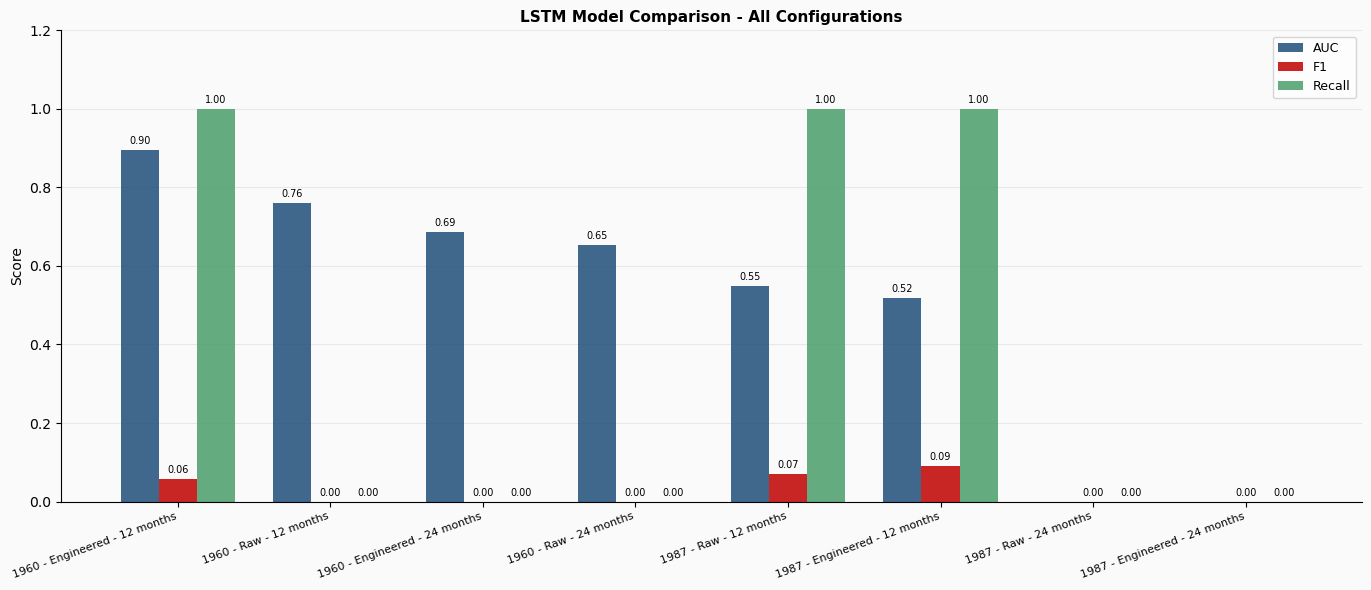

In [83]:
# LSTM Results Bar Chart 

fig, ax = plt.subplots(figsize=(14, 6))
fig.patch.set_facecolor("#fafafa")
ax.set_facecolor("#fafafa")

x = np.arange(len(lstm_df))
width = 0.25

bars1 = ax.bar(x - width, lstm_df["AUC"],    width,
               label="AUC",    color="#1f4e79", alpha=0.85)
bars2 = ax.bar(x,          lstm_df["F1"],     width,
               label="F1",     color="#c00000", alpha=0.85)
bars3 = ax.bar(x + width,  lstm_df["Recall"], width,
               label="Recall", color="#4a9e6b", alpha=0.85)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2,
                height + 0.01, f"{height:.2f}",
                ha="center", va="bottom", fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(lstm_df["Label"], fontsize=8, rotation=20, ha="right")
ax.set_ylim(0, 1.2)
ax.set_ylabel("Score")
ax.set_title("LSTM Model Comparison - All Configurations",
             fontsize=11, fontweight="bold")
ax.legend(fontsize=9)
ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

## SHAP Interpretability

SHAP (SHapley Additive exPlanations) analysis was applied to the tuned XGBoost models on both datasets to provide a deeper level of interpretability beyond standard feature importance scores. SHAP values quantify the contribution of each feature to each individual prediction, drawing on concepts from cooperative game theory to fairly distribute credit across all features. This allows both global interpretation - which features matter most overall - and local interpretation - why the model made a specific prediction for a particular month. Three visualisations are used: a bar plot showing overall feature importance by mean absolute SHAP value, a dot plot showing the direction and magnitude of each feature's impact, and a waterfall plot explaining a single specific prediction in detail.

### 1960 Dataset

**Bar plot - overall importance:**
The most influential feature by mean absolute SHAP value is `unemployment_pct3` - the three month percentage change in unemployment - with a mean SHAP value of approximately 1.4, considerably ahead of the second ranked feature `sp500_pct12` at around 1.05. The top five features are all percentage change or standard deviation variants rather than raw levels or simple lags, confirming that momentum and volatility signals carry substantially more predictive information than absolute values. This directly validates the feature engineering approach and the stationarity testing findings that identified most raw series as non-stationary and therefore better represented through their rate of change.

**Dot plot - direction of impact:**
`unemployment_pct3` shows a clear pattern where high values (red dots) push strongly toward recession prediction on the positive side of the x axis, while low values (blue dots) push away from recession. This is economically intuitive - a rapid three month rise in unemployment is a strong recession signal. `sp500_pct12` shows the opposite pattern - high values push away from recession while low values push toward it, consistent with falling equity markets being a recession indicator. `industrial_production_pct1` and `industrial_production_pct3` show similar negative relationships - declining production pushes toward recession prediction. `unemployment_std6` shows that high volatility in unemployment pushes toward recession, capturing the instability of labour markets during economic downturns.

**Waterfall plot - March 2020 (COVID-19):**
The waterfall plot examines the model prediction for March 2020, the first month of the COVID-19 recession. Starting from a base prediction of 1.375, the model reached a final output of 3.903, well above the decision threshold. The single largest driver was `unemployment_pct3` (+1.6), reflecting the dramatic three month rise in unemployment as COVID-19 lockdowns began. `industrial_production_pct3` (+0.87) and `unemployment_pct12` (+0.65) also pushed strongly toward recession, while `sp500_pct12` (-0.86) pushed against the recession prediction - reflecting that the twelve month S&P 500 change was still positive in March 2020 as markets had risen strongly in the prior year before the crash. The combined contribution of 40 other features (-0.26) was slightly negative, showing the model correctly identified that most other indicators were not yet showing recessionary patterns in March 2020.

### 1987 Dataset

**Bar plot - overall importance:**
The 1987 dataset shows a similar dominance of percentage change features, with `unemployment_pct12` as the most important feature at approximately 1.25, followed by `industrial_production_pct3` at around 1.0. Notably, yield curve features appear in the top 20 - `yield_curve_pct3` ranks sixth and `yield_curve_lag18` tenth - confirming the value of including the extended yield curve lag features identified in the lead/lag analysis. The interaction feature `yield_x_credit` does not appear in the top 20, suggesting its signal is captured by the individual yield curve and credit spread features rather than their interaction.

**Dot plot - direction of impact:**
`unemployment_pct12` shows high values pushing toward recession, consistent with the 1960 dataset findings. `industrial_production_pct3` shows high values pushing strongly away from recession - strong industrial growth is a clear non-recession signal. The yield curve features show that positive percentage changes in the yield curve push away from recession, consistent with a steepening yield curve indicating improving economic conditions. `housing_starts_std12` shows that high volatility in housing starts pushes toward recession, capturing the instability in construction activity that precedes downturns.

**Waterfall plot - March 2020 (COVID-19):**
Starting from a base prediction of 0.493, the model reached a final output of 2.933. The dominant driver was `unemployment_pct12` (+1.19), with `industrial_production_pct3` (+0.96) and `unemployment_pct3` (+0.58) also pushing strongly toward recession. As in the 1960 dataset, `sp500_pct12` (-0.70) pushed against the recession prediction. The yield curve lag feature `yield_curve_lag18` (-0.25) also pushed slightly against recession, reflecting that the yield curve had been relatively normal eighteen months prior to March 2020. The combined contribution of 101 other features (+0.50) highlights the breadth of signals the model draws on across the full engineered feature set.

### Key Findings

Across both datasets the SHAP analysis reveals a consistent set of findings. Percentage change features dominate over raw levels and simple lags, validating the decision to prioritise momentum-based features for non-stationary series identified in the stationarity testing stage. Unemployment and industrial production momentum are the strongest recession signals in both datasets. The 1987 dataset additionally draws on yield curve dynamics and housing market volatility, reflecting the richer indicator set available for the modern economic era. These findings provide transparent and economically grounded explanations of model behaviour that could be communicated directly to business or policy stakeholders, and are consistent with the broader economic understanding developed throughout the exploratory analysis sections of this project.

In [84]:
# SHAP Interpretability - XGBoost 1960 

import shap

# use the best model - tuned XGBoost on 1960 dataset
explainer_1960 = shap.TreeExplainer(xgb_tuned_1960.best_estimator_)
shap_values_1960 = explainer_1960.shap_values(X_1960_train_scaled)

print(f"SHAP values calculated for {X_1960_train_scaled.shape[0]} training observations")
print(f"Feature count: {X_1960_train_scaled.shape[1]}")

SHAP values calculated for 629 training observations
Feature count: 49


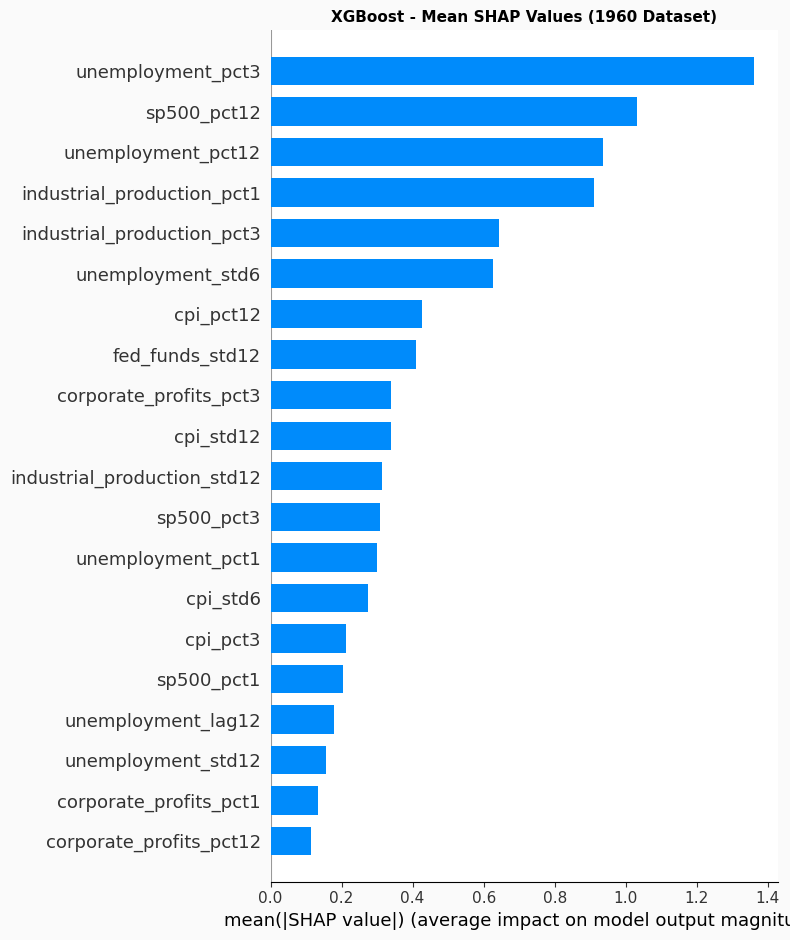

In [85]:
# SHAP Bar Plot - Overall Feature Importance

shap.summary_plot(shap_values_1960, X_1960_train_scaled,
                  feature_names=X_1960_train_scaled.columns.tolist(),
                  plot_type="bar", max_display=20, show=False)
plt.gcf().set_facecolor("#fafafa")
plt.title("XGBoost - Mean SHAP Values (1960 Dataset)", fontsize=11, fontweight="bold")
plt.tight_layout()
#plt.gcf().savefig("shap_bar_1960.png", dpi=150, bbox_inches="tight")
plt.show()

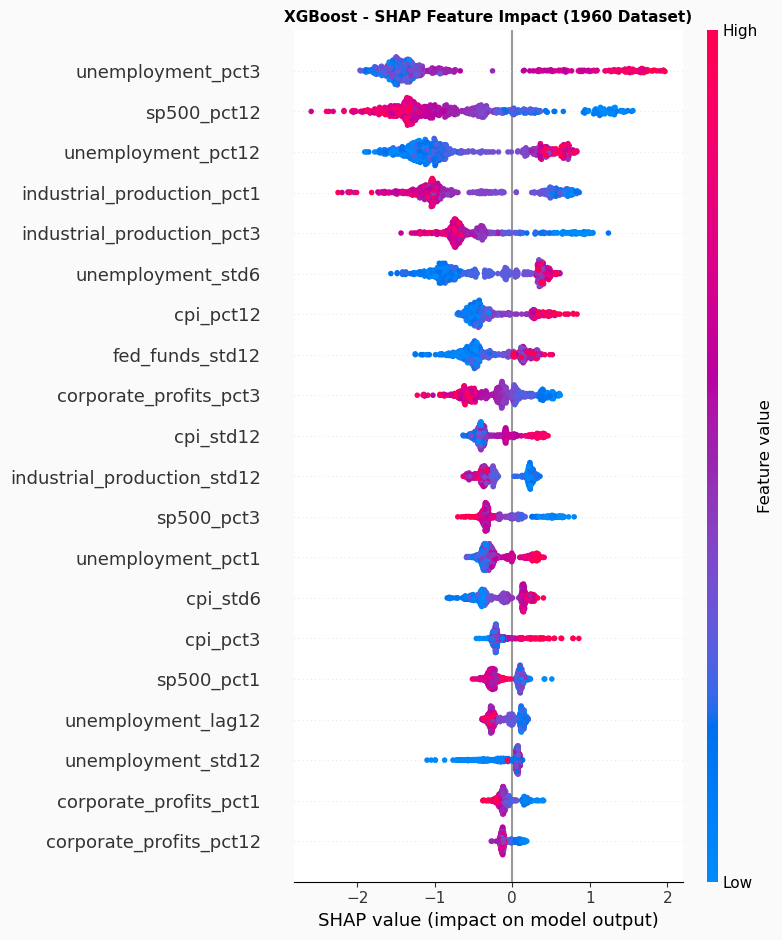

In [86]:
# SHAP Dot Plot - Feature Impact Direction

shap.summary_plot(shap_values_1960, X_1960_train_scaled,
                  feature_names=X_1960_train_scaled.columns.tolist(),
                  max_display=20, show=False)
plt.gcf().set_facecolor("#fafafa")
plt.title("XGBoost - SHAP Feature Impact (1960 Dataset)", fontsize=11, fontweight="bold")
plt.tight_layout()
#plt.gcf().savefig("shap_dot_1960.png", dpi=150, bbox_inches="tight")
plt.show()

Recession months in test set: [Timestamp('2020-03-01 00:00:00'), Timestamp('2020-04-01 00:00:00')]


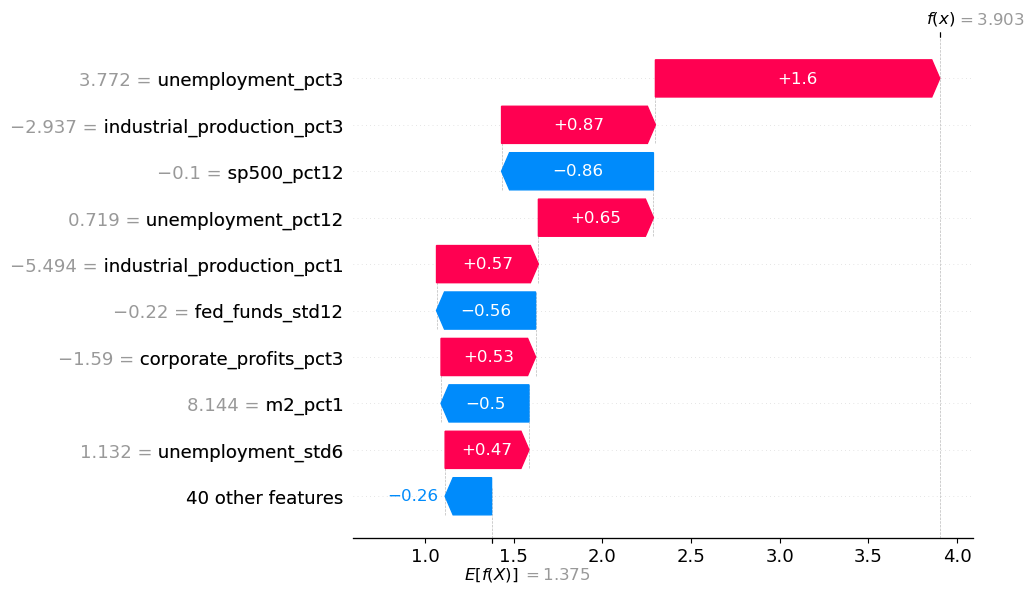

In [87]:
# SHAP Waterfall - Single Recession Month 
# explain the model prediction for the first recession month
# in the test set - COVID-19

recession_months = y_1960_test[y_1960_test == 1]
print(f"Recession months in test set: {recession_months.index.tolist()}")

recession_idx   = recession_months.index[0]
sample_position = X_1960_test_scaled.index.get_loc(recession_idx)
sample_scaled   = X_1960_test_scaled.iloc[[sample_position]]

shap_single = explainer_1960.shap_values(sample_scaled)

shap.waterfall_plot(
    shap.Explanation(
        values=shap_single[0],
        base_values=explainer_1960.expected_value,
        data=sample_scaled.values[0],
        feature_names=X_1960_train_scaled.columns.tolist()
    ),
    show=False
)
#plt.gcf().savefig("shap_waterfall_1960.png", dpi=150, bbox_inches="tight")
plt.show()

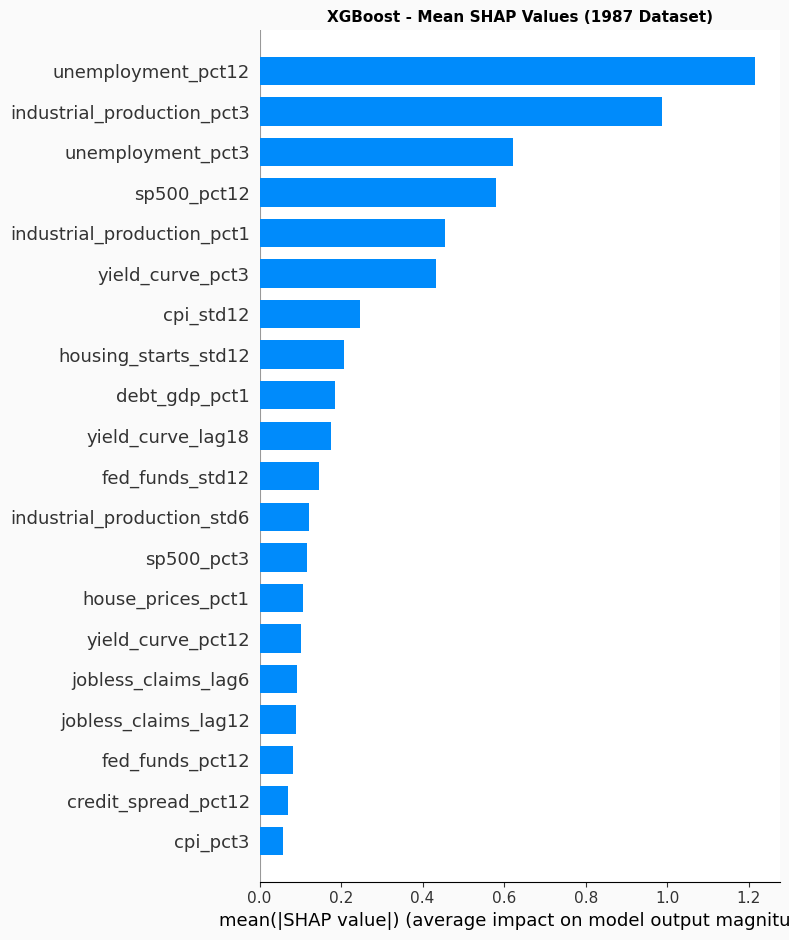

In [88]:
# SHAP for 1987 Dataset 

explainer_1987 = shap.TreeExplainer(xgb_tuned_1987.best_estimator_)
shap_values_1987 = explainer_1987.shap_values(X_1987_train_scaled)

shap.summary_plot(shap_values_1987, X_1987_train_scaled,
                  feature_names=X_1987_train_scaled.columns.tolist(),
                  plot_type="bar", max_display=20, show=False)
plt.gcf().set_facecolor("#fafafa")
plt.title("XGBoost - Mean SHAP Values (1987 Dataset)", fontsize=11, fontweight="bold")
plt.tight_layout()
#plt.gcf().savefig("shap_bar_1987.png", dpi=150, bbox_inches="tight")
plt.show()

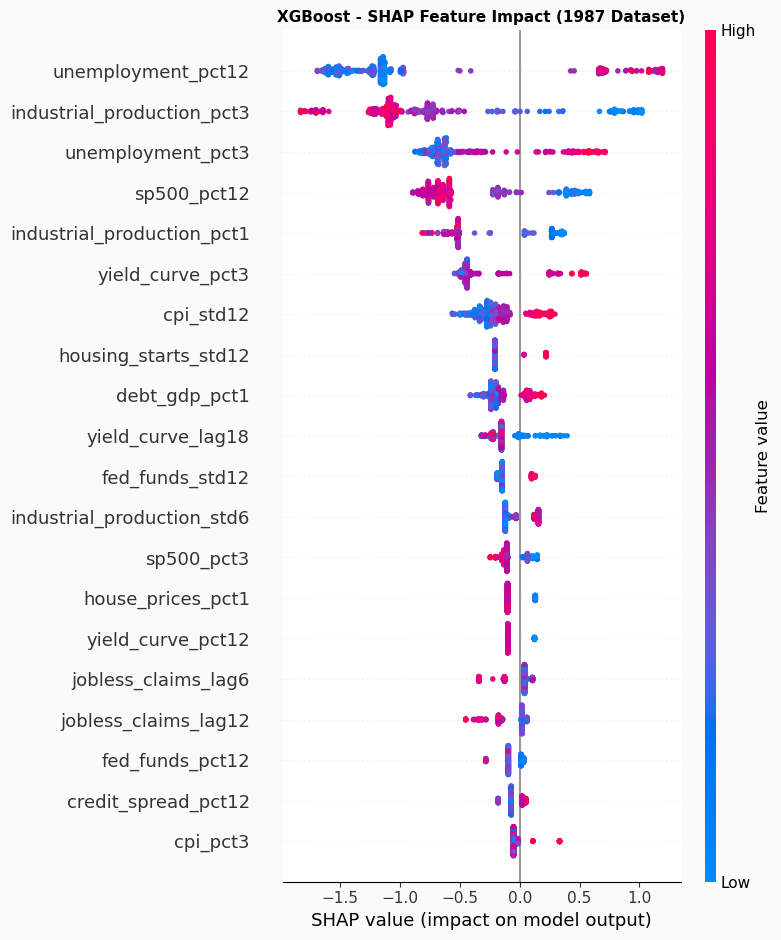

In [89]:
shap.summary_plot(shap_values_1987, X_1987_train_scaled,
                  feature_names=X_1987_train_scaled.columns.tolist(),
                  max_display=20, show=False)
plt.gcf().set_facecolor("#fafafa")
plt.title("XGBoost - SHAP Feature Impact (1987 Dataset)", fontsize=11, fontweight="bold")
plt.tight_layout()
#plt.gcf().savefig("shap_dot_1987.png", dpi=150, bbox_inches="tight")
plt.show()

Recession months in 1987 test set: [Timestamp('2020-03-01 00:00:00'), Timestamp('2020-04-01 00:00:00')]


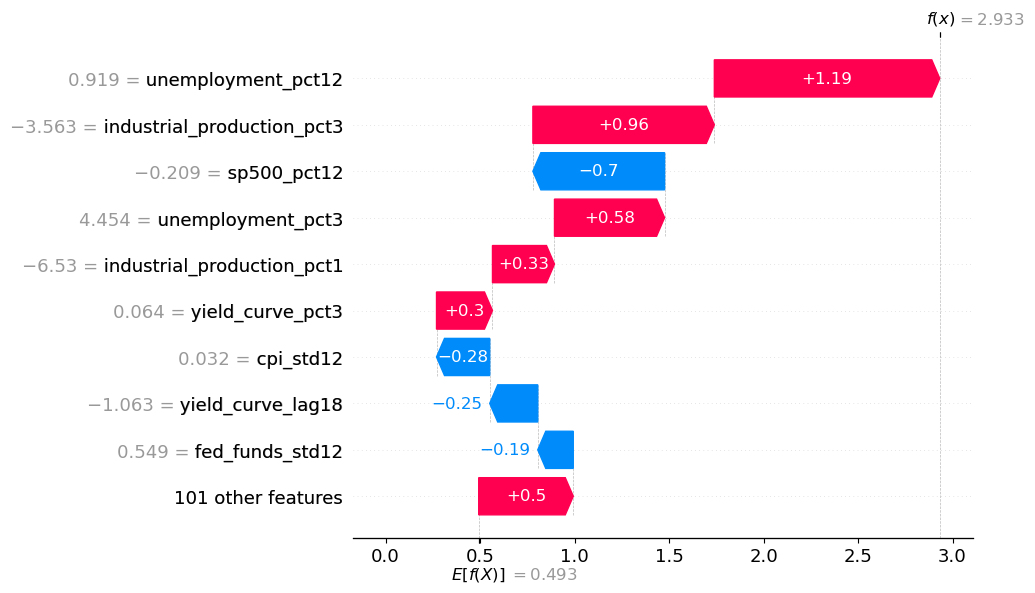

In [90]:
# SHAP Waterfall - 1987 Dataset 

recession_months_1987 = y_1987_test[y_1987_test == 1]
print(f"Recession months in 1987 test set: {recession_months_1987.index.tolist()}")

recession_idx_1987   = recession_months_1987.index[0]
sample_position_1987 = X_1987_test_scaled.index.get_loc(recession_idx_1987)
sample_scaled_1987   = X_1987_test_scaled.iloc[[sample_position_1987]]

shap_single_1987 = explainer_1987.shap_values(sample_scaled_1987)

shap.waterfall_plot(
    shap.Explanation(
        values=shap_single_1987[0],
        base_values=explainer_1987.expected_value,
        data=sample_scaled_1987.values[0],
        feature_names=X_1987_train_scaled.columns.tolist()
    ),
    show=False
)
#plt.gcf().savefig("shap_waterfall_1987.png", dpi=150, bbox_inches="tight")
plt.show()

## Predicted Recession Probability

The predicted recession probability plots provide the most intuitive and accessible form of model interpretability, showing how the model's recession risk signal evolves over time relative to actual recession periods. Rather than presenting a binary classification, the XGBoost model outputs a continuous probability score for each month indicating the degree of recession risk, with scores above the 0.5 decision threshold resulting in a recession classification. The green dashed vertical line in the full timeline plots marks the train/test split, helping readers visually distinguish in-sample training performance from out-of-sample test performance.

### 1960 Dataset - Full Timeline

The full timeline plot reveals a striking pattern across the training period from 1960 to 2013. The model generates sharp, clean spikes toward 1.0 precisely within the shaded recession windows for every single historical episode - the Rolling Adjustment recession, Nixon recession, Oil Shock, both Energy Crisis recessions, the Gulf War recession, the Dot-Com recession and the GFC - before returning immediately to near zero outside those windows. This near-perfect alignment between predicted probability spikes and actual recession periods across seven decades of economic history demonstrates that the model has successfully learned the macroeconomic patterns associated with recession onset.

Between recession episodes the probability line remains consistently close to zero, with very few false positive signals in the training period. This indicates the model is highly discriminative - it is not generating elevated recession risk scores during normal expansion periods, only spiking when the combination of indicators matches historical recession patterns.

In the test period the model correctly identifies the COVID-19 recession in 2020 with a sharp spike to 1.0, but also generates several false positive signals in the post-2021 period with probability scores reaching 0.4 to 0.5. These false alarms do not cross the 0.5 decision threshold consistently but suggest the model is detecting elevated economic stress in the post-pandemic environment that has not resulted in an officially declared recession.

### 1987 Dataset - Full Timeline

The 1987 dataset plot shows similarly clean performance in the training period, with the Dot-Com and GFC recessions both producing sharp probability spikes to approximately 0.95-1.0 within their respective windows. The Gulf War recession at the start of the series produces a narrower spike, consistent with its shorter duration.

The test period from January 2019 onwards shows more noise than the 1960 dataset, with elevated probability signals appearing in 2021, 2023 and 2025 in addition to the correct COVID-19 spike. Several of these signals cross the 0.5 threshold, producing false positive classifications. This noisier behaviour in the 1987 dataset test period likely reflects the richer feature set picking up on economic stress signals - rising credit spreads, yield curve movements and labour market volatility - that have occurred in the post-pandemic environment without resulting in a formal recession declaration. It may also partly reflect the structural changes in the modern economy discussed in the limitations section, where post-2020 economic dynamics differ from historical patterns.

### Test Period Zoom

The zoomed test period plots confirm that both models correctly identify the COVID-19 recession with high confidence spikes to 1.0 in March 2020, while the 1987 model generates more frequent and higher amplitude false positive signals in subsequent years. The 1960 model is notably cleaner in the post-COVID period, with probability scores remaining mostly below 0.2 outside the recession window and only occasional brief spikes above 0.4. This difference between the two datasets in the test period is an interesting finding - the simpler 1960 feature set may generalise better to the post-pandemic environment precisely because it is less sensitive to the unusual economic dynamics of the 2020s.

These visualisations provide a practical and intuitive tool for non-technical stakeholders, showing not just whether a recession is predicted but how confident the model is and how that confidence has evolved over time.

### Final Models and Current Risk Assessment

To generate a current recession risk assessment, both XGBoost models were retrained on the full available dataset rather than the 80% training split used for evaluation. Training on the full dataset ensures the final models incorporate all available economic history, including the COVID-19 recession and the post-pandemic period, before generating predictions on the most recent data.

As of July 2026, both models indicate very low recession risk in the United States. The 1960 model assigns a recession probability of 0.0% and the 1987 model assigns 0.2%, with both falling firmly in the low risk category well below the 0.5 decision threshold. This is consistent with the broader macroeconomic picture - unemployment remains near historically low levels, industrial production has continued to expand, credit spreads have not widened to recessionary levels, and the yield curve has normalised following the inversion of 2022 to 2023.

It should be noted that this assessment is based on the most recently available FRED data at the time of running the notebook. Due to reporting lags in official economic data, the most recent one to two months may reflect preliminary figures. Additionally, the full timeline plots of the final models confirm that when trained on the complete dataset the probability spikes align cleanly with all nine historical recession episodes and the signal returns to near zero in the current period, providing confidence that the low current reading reflects genuine model output rather than an artefact of the training process.

This current risk assessment updates automatically each time the notebook is run, as the data collection code fetches the most recent available data from FRED and Yahoo Finance. The assessment should always be interpreted alongside broader economic context and human judgement rather than as a standalone prediction.

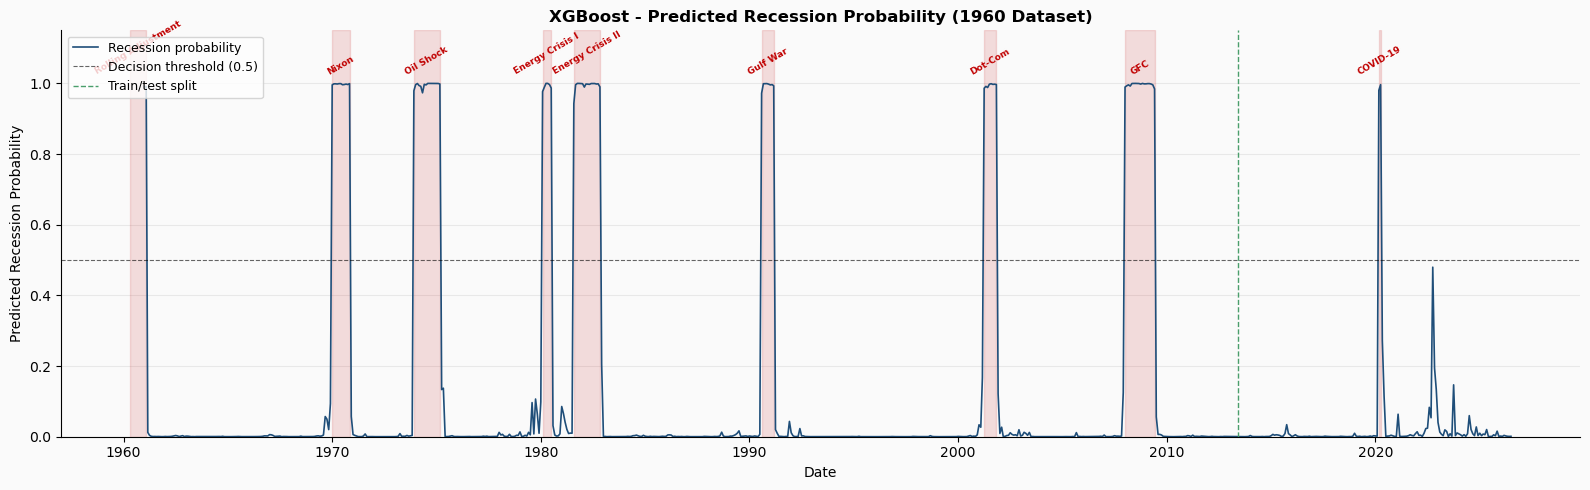

In [91]:
# Predicted Recession Probability - Full Timeline 
# apply tuned XGBoost to the full dataset to show recession
# probability across all historical episodes

# 1960 dataset - full timeline
X_1960_full_scaled = pd.DataFrame(
    scaler_1960.transform(X_1960),
    columns=X_1960.columns,
    index=X_1960.index
)

proba_1960_full = pd.Series(
    xgb_tuned_1960.best_estimator_.predict_proba(X_1960_full_scaled)[:, 1],
    index=X_1960_full_scaled.index
)

fig, ax = plt.subplots(figsize=(16, 5))
fig.patch.set_facecolor("#fafafa")
ax.set_facecolor("#fafafa")

ax.plot(proba_1960_full.index, proba_1960_full.values,
        color="#1f4e79", linewidth=1.2, label="Recession probability")
ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8,
           label="Decision threshold (0.5)", alpha=0.6)
ax.axvline(X_1960_test_scaled.index.min(), color="#4a9e6b",
           linestyle="--", linewidth=1.0, label="Train/test split")

for _, ep in episodes_1960.iterrows():
    ax.axvspan(ep["start"], ep["end"], color="#c00000", alpha=0.12)
    mid = ep["start"] + (ep["end"] - ep["start"]) / 2
    ax.text(mid, 1.02, ep["name"], ha="center", va="bottom",
            fontsize=6.5, color="#c00000", fontweight="bold", rotation=30)

ax.set_ylim(0, 1.15)
ax.set_ylabel("Predicted Recession Probability", fontsize=10)
ax.set_xlabel("Date", fontsize=10)
ax.set_title("XGBoost - Predicted Recession Probability (1960 Dataset)",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=9, loc="upper left")
ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
#plt.gcf().savefig("recession_probability_1960.png", dpi=150, bbox_inches="tight")
plt.show()

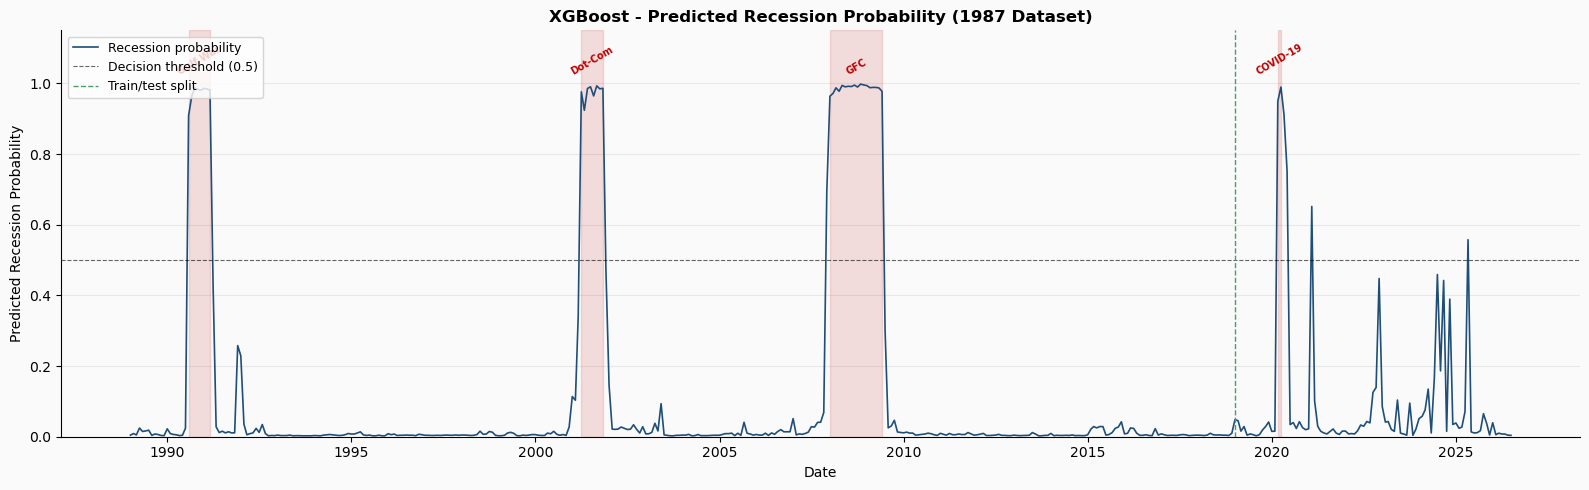

In [92]:
# Predicted Recession Probability - 1987 Dataset 

X_1987_full_scaled = pd.DataFrame(
    scaler_1987.transform(X_1987),
    columns=X_1987.columns,
    index=X_1987.index
)

proba_1987_full = pd.Series(
    xgb_tuned_1987.best_estimator_.predict_proba(X_1987_full_scaled)[:, 1],
    index=X_1987_full_scaled.index
)

fig, ax = plt.subplots(figsize=(16, 5))
fig.patch.set_facecolor("#fafafa")
ax.set_facecolor("#fafafa")

ax.plot(proba_1987_full.index, proba_1987_full.values,
        color="#1f4e79", linewidth=1.2, label="Recession probability")
ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8,
           label="Decision threshold (0.5)", alpha=0.6)
ax.axvline(X_1987_test_scaled.index.min(), color="#4a9e6b",
           linestyle="--", linewidth=1.0, label="Train/test split")

for _, ep in episodes_1987.iterrows():
    ax.axvspan(ep["start"], ep["end"], color="#c00000", alpha=0.12)
    mid = ep["start"] + (ep["end"] - ep["start"]) / 2
    ax.text(mid, 1.02, ep["name"], ha="center", va="bottom",
            fontsize=7, color="#c00000", fontweight="bold", rotation=30)

ax.set_ylim(0, 1.15)
ax.set_ylabel("Predicted Recession Probability", fontsize=10)
ax.set_xlabel("Date", fontsize=10)
ax.set_title("XGBoost - Predicted Recession Probability (1987 Dataset)",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=9, loc="upper left")
ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
#plt.gcf().savefig("recession_probability_1987.png", dpi=150, bbox_inches="tight")
plt.show()

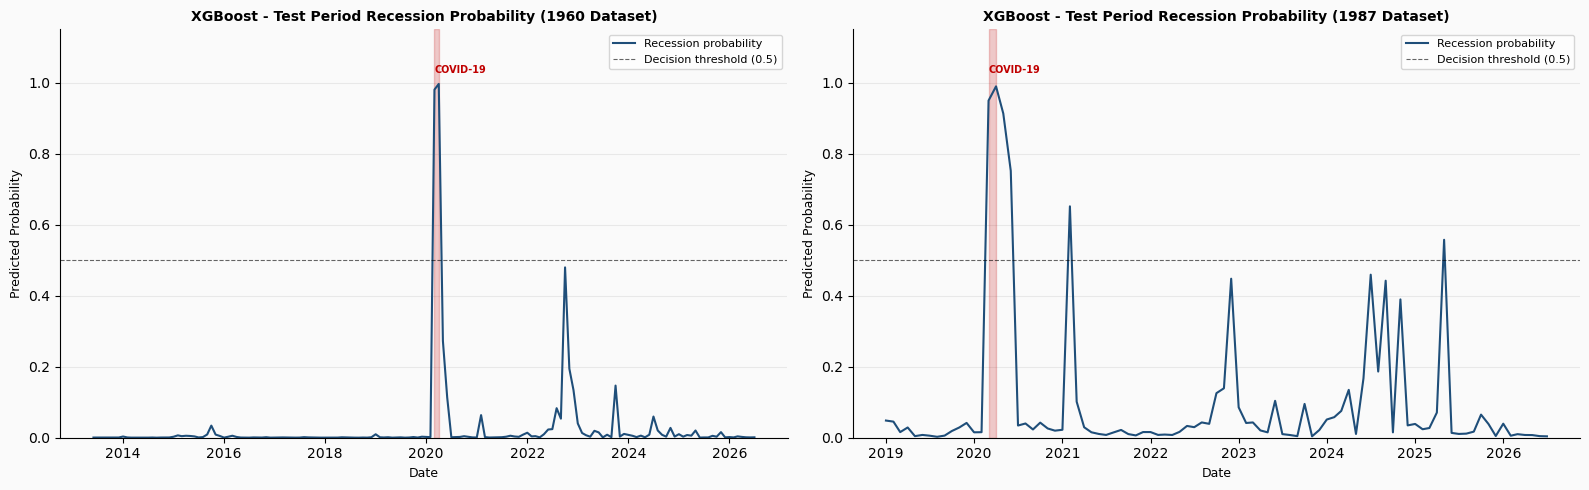

In [93]:
# Recession Probability - Test Period Only
# zoom into the test period to show model performance more clearly

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.patch.set_facecolor("#fafafa")

for ax, proba_full, episodes, X_test, label in [
    (axes[0], proba_1960_full, episodes_1960, X_1960_test_scaled, "1960"),
    (axes[1], proba_1987_full, episodes_1987, X_1987_test_scaled, "1987"),
]:
    ax.set_facecolor("#fafafa")
    test_start = X_test.index.min()
    proba_test = proba_full[proba_full.index >= test_start]

    ax.plot(proba_test.index, proba_test.values,
            color="#1f4e79", linewidth=1.5, label="Recession probability")
    ax.axhline(0.5, color="black", linestyle="--", linewidth=0.8,
               label="Decision threshold (0.5)", alpha=0.6)

    for _, ep in episodes[episodes["start"] >= test_start].iterrows():
        ax.axvspan(ep["start"], ep["end"], color="#c00000", alpha=0.2)
        ax.text(ep["start"], 1.02, ep["name"],
                ha="left", va="bottom", fontsize=7,
                color="#c00000", fontweight="bold")

    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Predicted Probability", fontsize=9)
    ax.set_xlabel("Date", fontsize=9)
    ax.set_title(f"XGBoost - Test Period Recession Probability ({label} Dataset)",
                 fontsize=10, fontweight="bold")
    ax.legend(fontsize=8)
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
#plt.gcf().savefig("recession_probability_test.png", dpi=150, bbox_inches="tight")
plt.show()

In [94]:
# Final Model - Train on Full Dataset
# retrain on full dataset including test set
# this is the deployment model - uses all available data

spw_1960_full = (y_1960 == 0).sum() / (y_1960 == 1).sum()
spw_1987_full = (y_1987 == 0).sum() / (y_1987 == 1).sum()

# scale full dataset
scaler_1960_final = StandardScaler()
scaler_1987_final = StandardScaler()

X_1960_final_scaled = pd.DataFrame(
    scaler_1960_final.fit_transform(X_1960),
    columns=X_1960.columns,
    index=X_1960.index
)

X_1987_final_scaled = pd.DataFrame(
    scaler_1987_final.fit_transform(X_1987),
    columns=X_1987.columns,
    index=X_1987.index
)

# train final models on full dataset
xgb_final_1960 = XGBClassifier(
    **xgb_tuned_1960.best_params_,
    scale_pos_weight=spw_1960_full,
    random_state=42,
    eval_metric="logloss",
    verbosity=0
)
xgb_final_1960.fit(X_1960_final_scaled, y_1960)

xgb_final_1987 = XGBClassifier(
    **xgb_tuned_1987.best_params_,
    scale_pos_weight=spw_1987_full,
    random_state=42,
    eval_metric="logloss",
    verbosity=0
)
xgb_final_1987.fit(X_1987_final_scaled, y_1987)

print("Final models trained on full datasets")
print(f"1960 model - trained on {len(X_1960_final_scaled)} observations")
print(f"1987 model - trained on {len(X_1987_final_scaled)} observations")

Final models trained on full datasets
1960 model - trained on 787 observations
1987 model - trained on 451 observations


In [95]:
# Current Recession Risk Assessment
# apply final models to most recent available data
# probability reflects current economic conditions

latest_date_1960 = X_1960_final_scaled.index.max()
latest_date_1987 = X_1987_final_scaled.index.max()

latest_proba_1960 = xgb_final_1960.predict_proba(
    X_1960_final_scaled.loc[[latest_date_1960]])[:, 1][0]
latest_proba_1987 = xgb_final_1987.predict_proba(
    X_1987_final_scaled.loc[[latest_date_1987]])[:, 1][0]

def risk_label(proba):
    if proba >= 0.5:
        return "HIGH RISK - recession conditions detected"
    elif proba >= 0.25:
        return "ELEVATED RISK - monitor closely"
    elif proba >= 0.1:
        return "LOW-MODERATE RISK"
    else:
        return "LOW RISK - no recession signal detected"

print("=" * 55)
print("CURRENT RECESSION RISK ASSESSMENT")
print("=" * 55)
print(f"\n1960 Model (core macroeconomic indicators)")
print(f"  Data up to:            {latest_date_1960.strftime('%B %Y')}")
print(f"  Recession probability: {latest_proba_1960:.1%}")
print(f"  Signal:                {risk_label(latest_proba_1960)}")
print(f"\n1987 Model (full indicator set)")
print(f"  Data up to:            {latest_date_1987.strftime('%B %Y')}")
print(f"  Recession probability: {latest_proba_1987:.1%}")
print(f"  Signal:                {risk_label(latest_proba_1987)}")
print("\nNote: probabilities reflect current economic conditions")
print("relative to historical recession patterns.")
print("Models should be interpreted alongside human judgement.")

CURRENT RECESSION RISK ASSESSMENT

1960 Model (core macroeconomic indicators)
  Data up to:            July 2026
  Recession probability: 0.0%
  Signal:                LOW RISK - no recession signal detected

1987 Model (full indicator set)
  Data up to:            July 2026
  Recession probability: 0.2%
  Signal:                LOW RISK - no recession signal detected

Note: probabilities reflect current economic conditions
relative to historical recession patterns.
Models should be interpreted alongside human judgement.


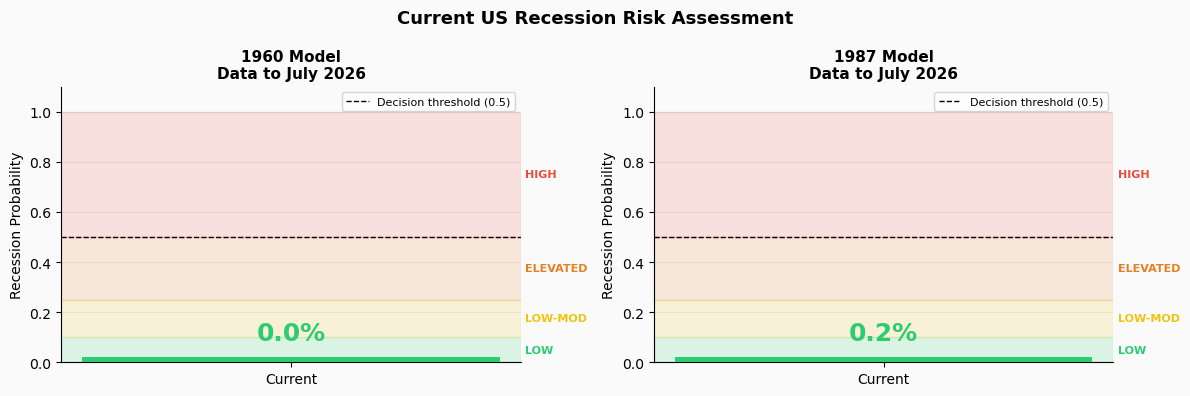

In [96]:
# Current Risk Gauge Visual 

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.patch.set_facecolor("#fafafa")

for ax, proba, label, date in [
    (axes[0], latest_proba_1960, "1960 Model", latest_date_1960),
    (axes[1], latest_proba_1987, "1987 Model", latest_date_1987),
]:
    ax.set_facecolor("#fafafa")

    # background zones
    ax.axhspan(0,    0.1,  color="#2ecc71", alpha=0.15, label="_nolegend_")
    ax.axhspan(0.1,  0.25, color="#f1c40f", alpha=0.15, label="_nolegend_")
    ax.axhspan(0.25, 0.5,  color="#e67e22", alpha=0.15, label="_nolegend_")
    ax.axhspan(0.5,  1.0,  color="#e74c3c", alpha=0.15, label="_nolegend_")

    # zone labels on right side
    for y, txt, col in [
        (0.05,  "LOW",       "#2ecc71"),
        (0.175, "LOW-MOD",   "#f1c40f"),
        (0.375, "ELEVATED",  "#e67e22"),
        (0.75,  "HIGH",      "#e74c3c"),
    ]:
        ax.text(1.01, y, txt, fontsize=8, color=col,
                va="center", fontweight="bold",
                transform=ax.get_yaxis_transform())

    # probability bar
    colour = "#e74c3c" if proba >= 0.5 else \
             "#e67e22" if proba >= 0.25 else \
             "#f1c40f" if proba >= 0.1 else "#2ecc71"

    ax.bar(["Current"], [max(proba, 0.02)], color=colour,
           width=0.4, zorder=3)
    ax.axhline(0.5, color="black", linestyle="--",
               linewidth=1.0, label="Decision threshold (0.5)", zorder=4)

    # percentage label above the bar
    ax.text(0, max(proba, 0.02) + 0.05, f"{proba:.1%}",
            ha="center", va="bottom", fontsize=18,
            fontweight="bold", color=colour)

    ax.set_ylim(0, 1.1)
    ax.set_ylabel("Recession Probability")
    ax.set_title(f"{label}\nData to {date.strftime('%B %Y')}",
                 fontsize=11, fontweight="bold")
    ax.legend(fontsize=8, loc="upper right")
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)

fig.suptitle("Current US Recession Risk Assessment", fontsize=13,
             fontweight="bold")
plt.tight_layout()
plt.show()

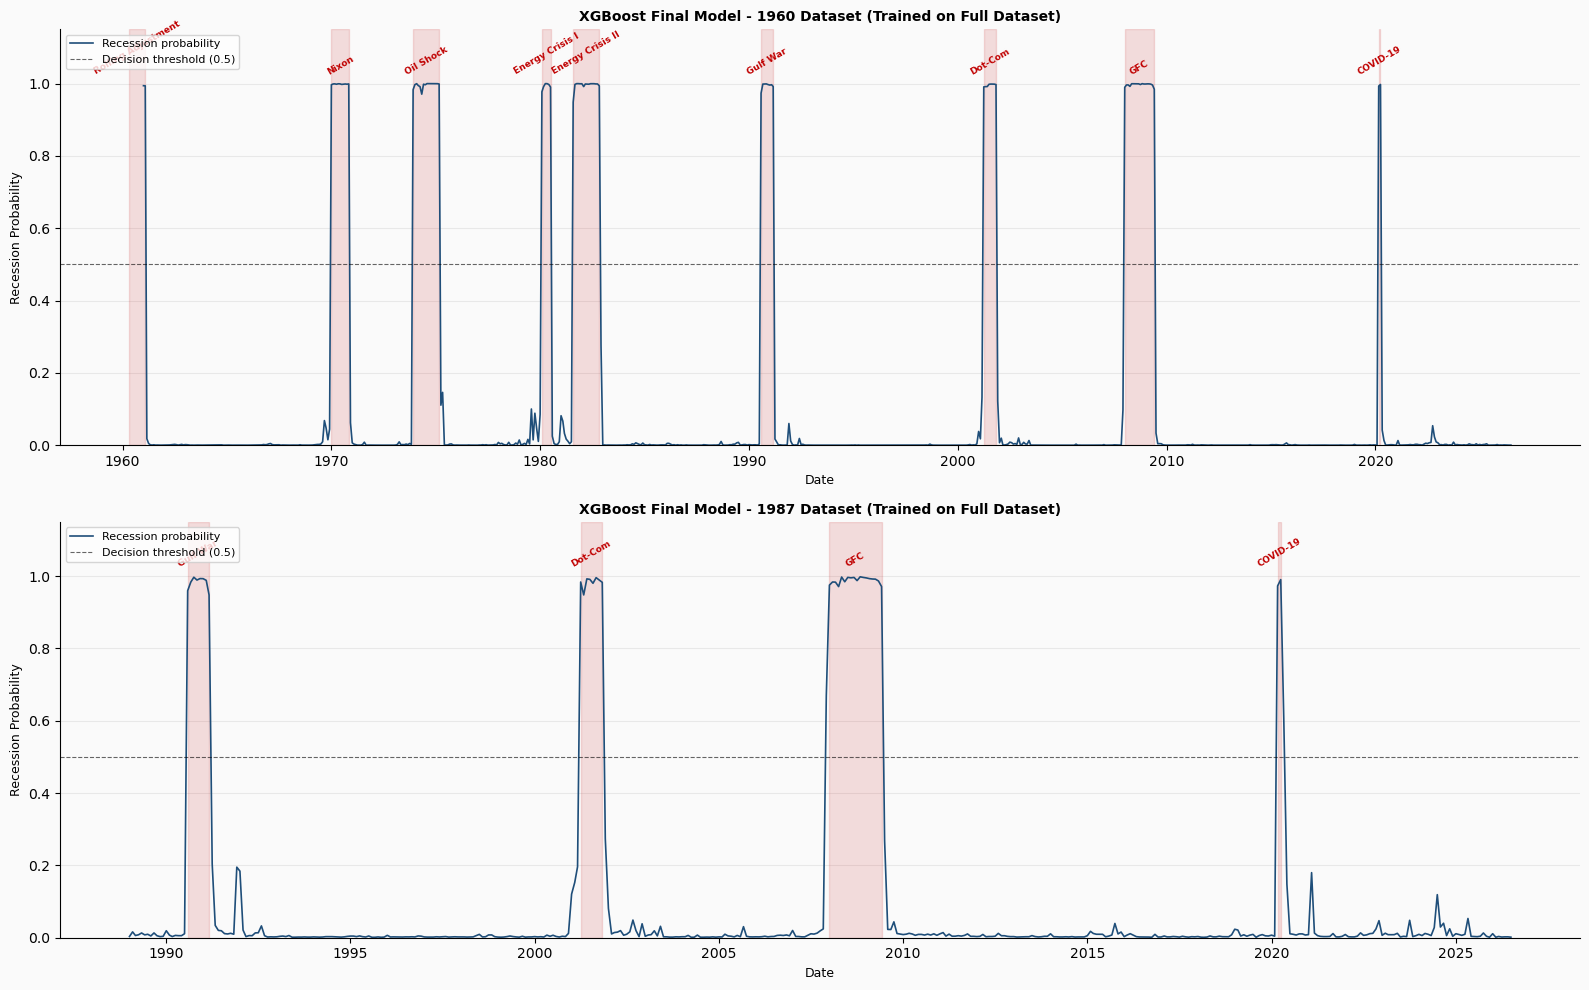

In [97]:
# Full Timeline Including Final Model Predictions 
# show recession probability across full history
# using final model trained on all available data

proba_1960_final_full = pd.Series(
    xgb_final_1960.predict_proba(X_1960_final_scaled)[:, 1],
    index=X_1960_final_scaled.index
)

proba_1987_final_full = pd.Series(
    xgb_final_1987.predict_proba(X_1987_final_scaled)[:, 1],
    index=X_1987_final_scaled.index
)

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=False)
fig.patch.set_facecolor("#fafafa")

for ax, proba_full, episodes, label in [
    (axes[0], proba_1960_final_full, episodes_1960, "1960 Dataset"),
    (axes[1], proba_1987_final_full, episodes_1987, "1987 Dataset"),
]:
    ax.set_facecolor("#fafafa")
    ax.plot(proba_full.index, proba_full.values,
            color="#1f4e79", linewidth=1.2, label="Recession probability")
    ax.axhline(0.5, color="black", linestyle="--",
               linewidth=0.8, label="Decision threshold (0.5)", alpha=0.6)

    for _, ep in episodes.iterrows():
        ax.axvspan(ep["start"], ep["end"], color="#c00000", alpha=0.12)
        mid = ep["start"] + (ep["end"] - ep["start"]) / 2
        ax.text(mid, 1.02, ep["name"], ha="center", va="bottom",
                fontsize=6.5, color="#c00000", fontweight="bold", rotation=30)

    ax.set_ylim(0, 1.15)
    ax.set_ylabel("Recession Probability", fontsize=9)
    ax.set_xlabel("Date", fontsize=9)
    ax.set_title(f"XGBoost Final Model - {label} (Trained on Full Dataset)",
                 fontsize=10, fontweight="bold")
    ax.legend(fontsize=8, loc="upper left")
    ax.yaxis.grid(True, color="#e8e8e8", linewidth=0.8)
    ax.set_axisbelow(True)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.show()

## Limitations and Next Steps

This section documents the key limitations of the current project and outlines the most promising directions for future development.

### Limitations

**Dataset size and recession frequency:**
The most fundamental limitation of this project is the rarity of recession events in the historical data. Recession months represent approximately 11% of the 1960 dataset and 8% of the 1987 dataset. Despite handling this through class weighting and appropriate evaluation metrics, the small number of recession months in the test sets - two in each case - means test set metrics are highly sensitive to individual predictions and should be interpreted with caution. The CV scores across the training set are the more reliable measure of generalisation performance.

**Temporal split and test set composition:**
Both test sets cover predominantly non-recessionary periods with COVID-19 being the only recession episode represented. This means model performance is evaluated entirely on one structurally unique recession driven by a non-economic external shock rather than by the macroeconomic imbalances the models were trained to detect. A longer dataset extending further into the future, or one that includes more diverse recession types in the test period, would provide a more robust evaluation.

**Post-2020 false positive signals:**
Both models generate elevated recession probability signals in the post-2021 period that do not correspond to officially declared recessions. This likely reflects genuine economic stress - post-pandemic inflation, aggressive monetary tightening, yield curve inversion and labour market disruption - that the models correctly identify as recessionary conditions based on historical patterns. Whether these are false positives or early warning signals of conditions that have not yet resulted in a formal recession declaration is an open question that only time will resolve.

**Structural breaks:**
The relationships between macroeconomic indicators and recession dynamics have shifted over time. The prolonged period of near-zero interest rates following the GFC altered the behaviour of several indicators as recession signals, and the post-pandemic environment of elevated inflation combined with strong employment has no clear historical precedent. Models trained on historical patterns may therefore be less reliable in structurally novel economic environments.

**LSTM data constraints:**
The LSTM neural network underperformed relative to traditional machine learning models across all eight configurations tested. This is attributable to the limited number of training sequences available - a maximum of 627 in the 1960 dataset and 368 in the 1987 dataset - after applying sequence windows to a monthly dataset. Higher frequency data or a longer historical record would likely improve LSTM performance substantially.

**Data availability:**
Several indicators are not available for the full 1960 to present period, requiring the use of two datasets of different lengths and feature richness. The yield curve is only available from 1976, credit spread from 1986 and house prices from 1987, meaning the 1960 dataset must rely on a smaller set of core macroeconomic indicators. Additionally, two indicators - VIX and the OECD Leading Economic Index - were excluded due to insufficient historical coverage or series ending before the present day.

**Current risk assessment caveat:**
The current recession risk assessment is based on the most recently available FRED data at the time of running the notebook. Due to reporting lags in official economic data, the most recent one to two months may be based on preliminary or incomplete data. The assessment should be interpreted as indicative rather than definitive, and always alongside broader economic context and human judgement.

### Next Steps

**Real-time deployment:**
The current risk assessment cell provides a foundation for a deployable tool. The next step would be developing a Streamlit web application that automatically fetches the latest FRED and Yahoo Finance data on a scheduled basis, retrains or updates the model, and displays the current recession probability in an accessible dashboard format with historical context.

**Forward looking probability:**
The current model assesses recession risk based on current and recent indicator values. A more powerful tool would forecast recession probability at a horizon of 3, 6 or 12 months ahead, giving businesses and investors more lead time to respond. This would require forecasting the indicator values themselves before feeding them to the recession model, representing a significant methodological extension.

**Ensemble methods:**
Combining the predictions of Logistic Regression, XGBoost and a retrained LSTM into an ensemble model could improve robustness by leveraging the different strengths of each approach. Logistic Regression provides well-calibrated probabilities, XGBoost captures non-linear feature interactions, and an LSTM with sufficient data could add temporal pattern recognition. Model stacking or simple probability averaging are natural starting points.

**Additional indicators:**
Further financial stress indicators such as the TED spread, commercial paper rates and bank lending standards could enrich the feature set. Consumer sentiment measures beyond those currently included and sector level employment data could also improve predictive performance.

**Higher frequency data:**
Resampling daily financial market data to capture within-month volatility through features such as monthly high-low range, intra-month standard deviation and maximum drawdown could provide more timely recession signals than monthly averages alone. Higher frequency data would also substantially increase the number of training sequences available for the LSTM.

**International datasets:**
Extending the analysis to other developed economies such as the United Kingdom, Germany and Japan would test whether the models generalise beyond the US economic context and whether global leading indicators add predictive value.

**Improved LSTM architecture:**
With access to higher frequency data generating more training sequences, a more sophisticated LSTM architecture incorporating attention mechanisms or transformer based sequence models could be expected to outperform the tree based models that currently dominate on limited monthly data.